### Task Group 0: Reproducible Setup & Locked Candidate Manifest

# Phase 1.6 — Grouped Cross-Validation & Final Model Selection

## Task Group 0 — Reproducible Setup & Locked Candidate Manifest

### Question

Before running grouped cross-validation, how do we make sure that the candidates,
target, weighting policy, and evaluation rules are fixed rather than being changed
in response to cross-validation results?

### Why this matters

Phase 1.5 was exploratory development. We repeatedly examined one fixed validation
split while testing modeling decisions.

Phase 1.6 has a different purpose: stronger model selection.

Before seeing grouped-CV results, we therefore freeze:

- the candidate model configurations,
- the exact uncapped RUL target,
- ordinary row weighting,
- grouped evaluation by engine,
- the primary and supporting metrics,
- and the rule that the official FD001 test labels remain sealed.

The cross-validation results are allowed to SELECT among the frozen candidates.
They are not supposed to generate an open-ended new tuning loop.

### Mental model

Phase 1.5:
experiment → learn → modify → experiment again

Phase 1.6:
freeze → evaluate → compare → select → lock

The candidate manifest is therefore a record of what we committed to BEFORE
seeing the stronger evaluation evidence.

In [1]:
# 0B — Imports and Phase 1.6 paths

from pathlib import Path
import hashlib

import pandas as pd
from IPython.display import display

from predictive_maintenance.config import (
    DATASET_NAME,
    RANDOM_STATE,
)

from predictive_maintenance.data.cmapss import (
    load_cmapss_subset,
)

from predictive_maintenance.data.targets import (
    add_training_rul,
)

from predictive_maintenance.features.feature_sets import (
    GROUP_COLUMN,
    TARGET_COLUMN,
    SIMPLE_TEMPORAL_MODEL_FEATURES,
)


# This notebook is expected to be run either:
#   1. from the repository root, or
#   2. from the notebooks/ directory.
#
# We resolve the project root so the report path works in either case.

CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

REPORTS_DIR = PROJECT_ROOT / "reports"

CANDIDATE_MANIFEST_PATH = (
    REPORTS_DIR / "phase_16_candidate_manifest.csv"
)

print("Dataset:", DATASET_NAME)
print("Random state:", RANDOM_STATE)
print("Project root:", PROJECT_ROOT)
print("Candidate manifest:", CANDIDATE_MANIFEST_PATH)

assert CANDIDATE_MANIFEST_PATH.exists(), (
    "Phase 1.6 candidate manifest was not found. "
    "It should have been created at the end of Phase 1.5."
)

Dataset: FD001
Random state: 42
Project root: /Users/stuart/repos/ml-predictive-maintenance-mlops
Candidate manifest: /Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_candidate_manifest.csv


## 0C — Prediction: What Does "Frozen" Actually Mean?

Before loading the manifest, predict:

Suppose Candidate A performs badly in the first few CV folds and you suddenly
think of a better hyperparameter value.

Should you:

A. Edit Candidate A and continue the cross-validation?

or

B. Finish evaluating the candidates that were declared before CV?

Why?

Also consider what would happen if we repeatedly changed candidates after
looking at grouped-CV results.

In [2]:
# 0D — Load the locked Phase 1.6 candidate manifest

candidate_manifest = pd.read_csv(
    CANDIDATE_MANIFEST_PATH
)

print(
    f"Loaded {len(candidate_manifest)} primary "
    "Phase 1.6 candidate configurations."
)

display(candidate_manifest)

Loaded 3 primary Phase 1.6 candidate configurations.


,candidate_id,description,representation,model_family,capacity_setting,n_features,sensor_6_included,target,weighting
0,candidate_A_current_leader,Current Phase 1.5 leading configuration,Matched temporal reference,RandomForest,max_depth=5,36,True,uncapped RUL,ordinary row weighting
1,candidate_B_sensor6_ablated,Current Phase 1.5 leader with Sensor 6 removed,Matched temporal reference,RandomForest,max_depth=5,35,False,uncapped RUL,ordinary row weighting
2,candidate_C_family_alternative,best linear-family alternative,Matched temporal reference,Ridge,alpha=100,36,True,uncapped RUL,ordinary row weighting


In [3]:
# 0E — Audit and fingerprint the locked candidate manifest

# These fields describe the complete high-level configuration that
# Phase 1.5 handed to Phase 1.6.
required_manifest_columns = {
    "candidate_id",
    "description",
    "representation",
    "model_family",
    "capacity_setting",
    "n_features",
    "sensor_6_included",
    "target",
    "weighting",
}

missing_columns = (
    required_manifest_columns
    - set(candidate_manifest.columns)
)

assert not missing_columns, (
    f"Candidate manifest is missing columns: {missing_columns}"
)


# We intentionally selected THREE primary candidates in Phase 1.5.
# The simple temporal OLS model will remain a separate benchmark.
assert len(candidate_manifest) == 3, (
    "Expected exactly three frozen primary candidates."
)

assert candidate_manifest["candidate_id"].is_unique, (
    "Each candidate must have a unique candidate_id."
)

assert candidate_manifest["candidate_id"].notna().all()

assert (
    pd.to_numeric(
        candidate_manifest["n_features"],
        errors="coerce",
    )
    .gt(0)
    .all()
), "Every candidate must have a positive feature count."


# We are solving the original exact-RUL prediction problem.
#
# The exact wording in the CSV may contain additional text, so we check
# the important semantic commitment: the target must be uncapped.
assert (
    candidate_manifest["target"]
    .astype(str)
    .str.lower()
    .str.contains("uncapped")
    .all()
), "Every Phase 1.6 candidate must use uncapped RUL."


# Equal-engine weighting did not become part of the final candidate contract.
assert (
    candidate_manifest["weighting"]
    .astype(str)
    .str.lower()
    .str.contains("ordinary")
    .all()
), "Every Phase 1.6 candidate must use ordinary row weighting."


# ------------------------------------------------------------
# Manifest fingerprint
# ------------------------------------------------------------
#
# A SHA-256 hash acts like a fingerprint of the exact CSV file.
#
# If even one character in the manifest changes later, the hash changes.
# This gives us a simple integrity check before running CV.

LOCKED_MANIFEST_SHA256 = hashlib.sha256(
    CANDIDATE_MANIFEST_PATH.read_bytes()
).hexdigest()

print("Candidate manifest audit: PASSED")
print()
print("Candidate IDs:")
for candidate_id in candidate_manifest["candidate_id"]:
    print("  -", candidate_id)

print()
print("Locked manifest SHA-256:")
print(LOCKED_MANIFEST_SHA256)

Candidate manifest audit: PASSED

Candidate IDs:
  - candidate_A_current_leader
  - candidate_B_sensor6_ablated
  - candidate_C_family_alternative

Locked manifest SHA-256:
72c9208849981d7257eb5117d6b62916f2293bc81f31d4f939b78c220371a7ff


## 0F — Prediction: What Is the Development Population Now?

During Phase 1.5 we used a fixed grouped split:

80 development-training engines
20 validation engines

Now that we are beginning grouped cross-validation, predict:

1. Should those same 20 validation engines remain permanently excluded from training?
2. Or should all 100 original FD001 training engines become the Phase 1.6 development pool?
3. What role will each engine play during grouped cross-validation?
4. Should the official FD001 test RUL labels participate anywhere in this process?

In [4]:
# 0G — Reconstruct the complete Phase 1.6 development population

# load_cmapss_subset currently returns:
#
#   1. complete FD001 training trajectories,
#   2. truncated official-test trajectories,
#   3. official-test RUL labels.
#
# Task Group 0 needs ONLY the original training trajectories.
#
# The test inputs and test labels are therefore immediately discarded
# without inspection. They must not influence model selection.

development_raw_df, discarded_test_df, discarded_test_rul = (
    load_cmapss_subset(DATASET_NAME)
)

del discarded_test_df
del discarded_test_rul


# The original FD001 training trajectories run to failure, which allows us
# to construct the exact row-level RUL target retrospectively.
development_df = add_training_rul(
    development_raw_df
)


# Sorting is important conceptually for sequential data.
#
# We want every engine trajectory ordered from its earliest observed cycle
# to its latest observed cycle before later temporal engineering.
development_df = (
    development_df
    .sort_values(
        [GROUP_COLUMN, "cycles"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------

EXPECTED_DEVELOPMENT_ENGINES = 100
EXPECTED_DEVELOPMENT_ROWS = 20_631

assert len(development_df) == EXPECTED_DEVELOPMENT_ROWS

assert (
    development_df[GROUP_COLUMN].nunique()
    == EXPECTED_DEVELOPMENT_ENGINES
)

assert development_df[TARGET_COLUMN].notna().all()

assert development_df[TARGET_COLUMN].ge(0).all()

assert (
    development_df
    .duplicated(
        subset=[GROUP_COLUMN, "cycles"]
    )
    .sum()
    == 0
)


# Every complete run-to-failure development engine should have RUL = 0
# at its final observed cycle.
final_cycle_indices = (
    development_df
    .groupby(GROUP_COLUMN)["cycles"]
    .idxmax()
)

assert (
    development_df
    .loc[final_cycle_indices, TARGET_COLUMN]
    .eq(0)
    .all()
)


print("Development-population audit: PASSED")
print("Rows:", len(development_df))
print(
    "Engines:",
    development_df[GROUP_COLUMN].nunique(),
)
print(
    "RUL range:",
    (
        development_df[TARGET_COLUMN].min(),
        development_df[TARGET_COLUMN].max(),
    ),
)

Development-population audit: PASSED
Rows: 20631
Engines: 100
RUL range: (np.int64(0), np.int64(361))


In [5]:
# 0H — Freeze the Phase 1.6 evaluation contract and benchmark

# The benchmark is intentionally separate from the three primary candidates.
#
# It gives us continuity with the simpler Phase 1.4 temporal OLS model.
# It is useful context, but it is not a fourth freshly tuned candidate.

PHASE_16_BENCHMARK = {
    "candidate_id": "benchmark_simple_temporal_ols",
    "role": "benchmark",
    "representation": "simple_temporal",
    "model_family": "LinearRegression",
    "capacity_setting": "unregularized",
    "n_features": len(SIMPLE_TEMPORAL_MODEL_FEATURES),
    "target": "exact uncapped RUL",
    "weighting": "ordinary row weighting",
}


# This dictionary records the rules by which the candidates will be judged.
#
# Importantly, we write these rules BEFORE seeing grouped-CV results.

PHASE_16_EVALUATION_CONTRACT = {
    "dataset": DATASET_NAME,
    "group_column": GROUP_COLUMN,
    "target": "exact uncapped RUL",
    "weighting": "ordinary row weighting",
    "primary_metric": "pooled out-of-fold RMSE",
    "secondary_metric": "pooled out-of-fold MAE",
    "supporting_diagnostics": (
        "fold RMSE variability, per-engine RMSE, "
        "signed errors, breadth of gains"
    ),
    "official_test_policy": (
        "do not inspect or use official test RUL "
        "until the final candidate is selected and locked"
    ),
}


print("Benchmark specification")
display(
    pd.Series(
        PHASE_16_BENCHMARK,
        name="value",
    ).to_frame()
)

print("\nPhase 1.6 evaluation contract")
display(
    pd.Series(
        PHASE_16_EVALUATION_CONTRACT,
        name="value",
    ).to_frame()
)


assert (
    len(SIMPLE_TEMPORAL_MODEL_FEATURES)
    == 36
), "Expected the simple temporal benchmark to use 36 features."

Benchmark specification


,value
candidate_id,benchmark_simple_temporal_ols
role,benchmark
representation,simple_temporal
model_family,LinearRegression
capacity_setting,unregularized
n_features,36
target,exact uncapped RUL
weighting,ordinary row weighting



Phase 1.6 evaluation contract


,value
dataset,FD001
group_column,unit_no
target,exact uncapped RUL
weighting,ordinary row weighting
primary_metric,pooled out-of-fold RMSE
secondary_metric,pooled out-of-fold MAE
supporting_diagnostics,"fold RMSE variability, per-engine RMSE, signed..."
official_test_policy,do not inspect or use official test RUL until ...


In [6]:
# 0I — Automatically generate the Task Group 0 summary

tg0_summary = pd.DataFrame(
    {
        "item": [
            "Dataset",
            "Development rows",
            "Development engines",
            "Frozen primary candidates",
            "Benchmark",
            "Target",
            "Weighting",
            "Grouping key",
            "Primary selection metric",
            "Official test RUL available to selection code",
            "Manifest fingerprint",
        ],
        "value": [
            DATASET_NAME,
            len(development_df),
            development_df[GROUP_COLUMN].nunique(),
            len(candidate_manifest),
            PHASE_16_BENCHMARK["candidate_id"],
            PHASE_16_EVALUATION_CONTRACT["target"],
            PHASE_16_EVALUATION_CONTRACT["weighting"],
            GROUP_COLUMN,
            PHASE_16_EVALUATION_CONTRACT["primary_metric"],
            "No",
            LOCKED_MANIFEST_SHA256[:16] + "...",
        ],
    }
)

display(tg0_summary)

,item,value
0,Dataset,FD001
1,Development rows,20631
2,Development engines,100
3,Frozen primary candidates,3
4,Benchmark,benchmark_simple_temporal_ols
5,Target,exact uncapped RUL
6,Weighting,ordinary row weighting
7,Grouping key,unit_no
8,Primary selection metric,pooled out-of-fold RMSE
9,Official test RUL available to selection code,No


## Task Group 0 — Active Recall

### Question 1
Why do we freeze the candidate manifest before examining grouped cross-validation results, and what could go wrong if we repeatedly modify candidates after seeing those results?

**Best section to review: 0C — Prediction: What Does "Frozen" Actually Mean?**

Because we need to embody the fact that candidates should not be edited anywhere throughout the cross validation process. If a candiate performs badly in the first few CV folds, then we should finish evaluating the candidates that were declared before cross-validation started (even though it might be tempting to edit the candidate if we think of a better hyperparameter value).

*The deeper reason is that grouped cross-validation results are supposed to provide new evidence about a set of candidates chosen without knowledge of the results.*

*The critical rule is that we do not redesign candidates based on the CV evidence and then treat the same CV results as unbiased evidence for those redesigned candiates.*

*We freeze the candidate definitions before grouped cross-validation so that the CV results provide independent evidence for configurations chosen beforehand. If we repeatedly modify candidates in response to their CV performance, we begin tuning to the cross-validation data itself, increasing the risk of validation overfitting and making the resulting generalization estimate overly optimistic.*

### Question 2
What is the difference between a candidate specification in the manifest and a fitted model produced inside a cross-validation fold?

**Best section to review: 0D — Load the Locked Phase 1.6 Candidate Manifest**

A candidate specification inside the manifest consists of a model, its parameters, and its `X` and `y` values. A fitted model produced inside a cross-validation fold is a model from the manifest that has been put through feature standardization and any other necessary parts of the training process. 

*The manifest does not contain the actual training observations or targets.*

*Think of a candidate as a recipe. It tells us what kind of model to construct and what representation/rules to use.*

*A candidate specification is an unfitted recipe describing the feature representation, model family, hyperparameters, target policy, weighting, and related modeling choices. A fitted model is a fresh instance of that specification that has learned parameters from on CV fold's training data. Any learned preprocessing, such as StandardScaler statistic, must also be fitted only on that fold's training observations.*

### Question 3
Why do all 100 original FD001 training engines become the development population for Phase 1.6 instead of permanently maintaining the old 80/20 Phase 1.5 split?

**Best section to review: 0F — Prediction: What Is the Development Population Now?**

Because now we are switching to cross-validation. The 80/20 split that was used in Phase 1.5 was only one possible configuration, and now we are switching to a situation where we need multiple folds. So we go back to declaring the 100 training engines as the development set, and then we start trying out folds that will be different from that original 80/20 split. 

*Across the full cross-validation procedure, every development engine gets an opportunity to serve as unseen held-out data.*

### Question 4
Why should the target, weighting policy, grouping rule, and primary selection metric be declared before cross-validation rather than chosen after looking at the CV results?

**Best section to review: 0H — Freeze the Phase 1.6 Evaluation Contract and Benchmark**

This goes back to the fact that we want to reduce the chances of validation overfitting. We want to remove our ability to make edits to a predetermined development process upon seeing initial results of that process. Otherwise we could get caught in a loop of seeing a result and editing and repeating, which could lead to a situation where we've done a good job of making predictions on the validation set without having created a model that will generalize well to unseen data.

**Freeze candidates before stronger evaluation so CV doesn't become another tuning loop.**

**A candidate specification is a recipe, not `X`, `y`, or a fitted model.**

**Each CV fold creates a fresh model and fresh learned preprocessing from that fold's training engines only.**

**All 100 engines form the development pool while grouped CV rotates which entire engines are unseen.**

**Predeclare how the winner will be judged instead of choosing the rules after seeing who wins.**

### Task Group 1: Grouped Cross-validation Design

# Task Group 1 — Grouped Cross-Validation Design

## 1A — Core Question

How can we evaluate our frozen candidates across multiple held-out populations
without allowing information from the same engine to appear in both training
and held-out data?

### Why this matters

FD001 contains many rows from each engine.

Those rows are not independent observations in the ordinary sense. They are
successive cycles from the same engine trajectory.

A random row-level split could therefore create a situation like:

Engine 17, cycles 1–140 → training

Engine 17, cycles 141–180 → held-out

The model would then be evaluated on an engine it has already encountered
during training.

Instead, Phase 1.6 groups by `unit_no`.

An engine's complete trajectory belongs entirely to either the training side
or the held-out side of a particular fold.

Across the complete cross-validation procedure, each development engine will
serve as a held-out engine once and as a training engine in the other folds.

### Phase 1.6 fold rule

Same engine → same side of a fold.

Same folds → every candidate.

Every development engine → held out once.

Official test engines → still separate.

## 1B — Prediction: What Should a Fold Mean?

Before creating the folds, answer these from memory.

1. Suppose Engine 42 contains 200 cycle rows. Can 150 rows go into training
   and 50 rows into the held-out portion of the same fold?

2. With 5-fold grouped cross-validation, what role should Engine 42 eventually
   play across the complete five-fold procedure?

3. Should Candidate A and Candidate B be evaluated using different fold
   assignments?

4. Should we first delete early cycles that lack enough temporal history and
   then decide which engines belong to each fold, or should fold membership
   first be defined from the complete engine population?

Think especially about what information the grouping variable represents.

In [7]:
# 1C — Create the five grouped cross-validation folds

from sklearn.model_selection import GroupKFold


# ------------------------------------------------------------
# Predeclare the number of folds
# ------------------------------------------------------------
#
# Five folds gives us multiple different held-out engine populations while
# still leaving most development engines available for training in each fold.
#
# We decide this BEFORE seeing candidate CV performance.

N_CV_FOLDS = 5

grouped_cv = GroupKFold(
    n_splits=N_CV_FOLDS
)


# ------------------------------------------------------------
# Generate the fold structure
# ------------------------------------------------------------
#
# IMPORTANT:
#
# We are splitting the COMPLETE development population here.
#
# We have NOT:
#   - created expanded temporal features,
#   - removed early cycles,
#   - fitted a scaler,
#   - fitted a model,
#   - or looked at candidate performance.
#
# GroupKFold only needs to know which rows belong to which engine.

cv_splits = []
fold_assignment_records = []

for fold_id, (train_idx, heldout_idx) in enumerate(
    grouped_cv.split(
        X=development_df,
        groups=development_df[GROUP_COLUMN],
    ),
    start=1,
):

    train_engine_ids = set(
        development_df
        .iloc[train_idx][GROUP_COLUMN]
        .unique()
    )

    heldout_engine_ids = set(
        development_df
        .iloc[heldout_idx][GROUP_COLUMN]
        .unique()
    )


    # --------------------------------------------------------
    # Immediate leakage check
    # --------------------------------------------------------
    #
    # No engine is allowed to appear on both sides of a fold.

    assert train_engine_ids.isdisjoint(
        heldout_engine_ids
    )


    # Save the row indices for later Task Groups.
    cv_splits.append(
        {
            "fold_id": fold_id,
            "train_idx": train_idx,
            "heldout_idx": heldout_idx,
        }
    )


    # Also create a simpler ENGINE-LEVEL record.
    #
    # This will become our persistent fold-assignment artifact.
    for engine_id in sorted(heldout_engine_ids):
        fold_assignment_records.append(
            {
                GROUP_COLUMN: engine_id,
                "heldout_fold": fold_id,
            }
        )


fold_assignment_df = (
    pd.DataFrame(fold_assignment_records)
    .sort_values(GROUP_COLUMN)
    .reset_index(drop=True)
)

print(
    f"Created {N_CV_FOLDS}-fold grouped "
    "cross-validation structure."
)

display(fold_assignment_df.head(15))

Created 5-fold grouped cross-validation structure.


,unit_no,heldout_fold
0,1,1
1,2,5
2,3,3
3,4,5
4,5,4
5,6,2
6,7,3
7,8,4
8,9,5
9,10,3


## 1D — Prediction: What Would Prove That Grouping Worked?

Before running the audit, decide what must be true.

Think about these separately:

- engine overlap within one fold,
- coverage of all 100 development engines,
- how many times each engine is held out,
- whether every row from an engine receives the same held-out fold ID,
- and whether all development rows are accounted for.

What assertion would fail if one engine accidentally appeared in both the
training and held-out portions of Fold 3?

In [8]:
# 1E — Audit the grouped cross-validation structure

development_engine_ids = set(
    development_df[GROUP_COLUMN].unique()
)

assigned_engine_ids = set(
    fold_assignment_df[GROUP_COLUMN]
)


# ------------------------------------------------------------
# Audit 1: Every development engine received a fold
# ------------------------------------------------------------

assert assigned_engine_ids == development_engine_ids


# ------------------------------------------------------------
# Audit 2: Each engine appears exactly once in the assignment table
# ------------------------------------------------------------
#
# "Exactly once" means each engine has exactly one fold in which it is
# the held-out engine.

assert fold_assignment_df[GROUP_COLUMN].is_unique

assert len(fold_assignment_df) == len(
    development_engine_ids
)


# ------------------------------------------------------------
# Audit 3: Exactly five held-out fold IDs exist
# ------------------------------------------------------------

expected_fold_ids = set(
    range(1, N_CV_FOLDS + 1)
)

actual_fold_ids = set(
    fold_assignment_df["heldout_fold"].unique()
)

assert actual_fold_ids == expected_fold_ids


# ------------------------------------------------------------
# Audit 4: No fold contains the same engine in train and held-out
# ------------------------------------------------------------

for split in cv_splits:

    train_idx = split["train_idx"]
    heldout_idx = split["heldout_idx"]

    train_engines = set(
        development_df
        .iloc[train_idx][GROUP_COLUMN]
        .unique()
    )

    heldout_engines = set(
        development_df
        .iloc[heldout_idx][GROUP_COLUMN]
        .unique()
    )

    assert train_engines.isdisjoint(
        heldout_engines
    )

    # Together, the two sides must still represent the entire
    # development-engine population.
    assert (
        train_engines | heldout_engines
        == development_engine_ids
    )

    # Every development row must be on exactly one side of the split.
    assert (
        len(train_idx) + len(heldout_idx)
        == len(development_df)
    )


# ------------------------------------------------------------
# Audit 5: Every row from the same engine receives the same fold ID
# ------------------------------------------------------------

engine_to_fold = (
    fold_assignment_df
    .set_index(GROUP_COLUMN)["heldout_fold"]
)

development_fold_membership = (
    development_df[
        [GROUP_COLUMN, "cycles", TARGET_COLUMN]
    ]
    .copy()
)

development_fold_membership["heldout_fold"] = (
    development_fold_membership[GROUP_COLUMN]
    .map(engine_to_fold)
)

assert (
    development_fold_membership["heldout_fold"]
    .notna()
    .all()
)

assert (
    development_fold_membership
    .groupby(GROUP_COLUMN)["heldout_fold"]
    .nunique()
    .eq(1)
    .all()
)


print("Grouped CV integrity audit: PASSED")
print(
    "Development engines:",
    len(development_engine_ids),
)
print(
    "Fold IDs:",
    sorted(actual_fold_ids),
)
print(
    "Every engine held out exactly once: YES"
)
print(
    "Same-engine train/held-out overlap: NONE"
)

Grouped CV integrity audit: PASSED
Development engines: 100
Fold IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Every engine held out exactly once: YES
Same-engine train/held-out overlap: NONE


In [9]:
# 1F — Inspect fold balance

fold_summary_records = []

for split in cv_splits:

    fold_id = split["fold_id"]
    train_idx = split["train_idx"]
    heldout_idx = split["heldout_idx"]

    train_groups = (
        development_df
        .iloc[train_idx][GROUP_COLUMN]
        .unique()
    )

    heldout_groups = (
        development_df
        .iloc[heldout_idx][GROUP_COLUMN]
        .unique()
    )

    fold_summary_records.append(
        {
            "fold_id": fold_id,
            "training_engines": len(train_groups),
            "heldout_engines": len(heldout_groups),
            "training_rows": len(train_idx),
            "heldout_rows": len(heldout_idx),
            "heldout_row_percent": (
                100 * len(heldout_idx)
                / len(development_df)
            ),
        }
    )


fold_summary_df = pd.DataFrame(
    fold_summary_records
)

display(
    fold_summary_df.round(
        {"heldout_row_percent": 2}
    )
)


print(
    "\nTotal held-out rows across all folds:",
    fold_summary_df["heldout_rows"].sum(),
)

assert (
    fold_summary_df["heldout_rows"].sum()
    == len(development_df)
)

,fold_id,training_engines,heldout_engines,training_rows,heldout_rows,heldout_row_percent
0,1,80,20,16511,4120,19.97
1,2,80,20,16498,4133,20.03
2,3,80,20,16505,4126,20.00
3,4,80,20,16506,4125,19.99
4,5,80,20,16504,4127,20.00



Total held-out rows across all folds: 20631


In [10]:
# 1G — Inspect which engines belong to each held-out fold

for fold_id in range(1, N_CV_FOLDS + 1):

    heldout_engines = (
        fold_assignment_df
        .loc[
            fold_assignment_df["heldout_fold"]
            .eq(fold_id),
            GROUP_COLUMN,
        ]
        .tolist()
    )

    print(
        f"Fold {fold_id} held-out engines "
        f"({len(heldout_engines)}):"
    )

    print(heldout_engines)
    print()

Fold 1 held-out engines (20):
[1, 12, 14, 16, 17, 22, 25, 26, 28, 31, 39, 49, 55, 61, 69, 72, 90, 93, 94, 100]

Fold 2 held-out engines (20):
[6, 18, 24, 29, 34, 37, 41, 43, 45, 58, 59, 62, 76, 79, 81, 84, 85, 86, 88, 92]

Fold 3 held-out engines (20):
[3, 7, 10, 11, 13, 21, 33, 42, 44, 47, 60, 65, 66, 73, 78, 91, 95, 96, 98, 99]

Fold 4 held-out engines (20):
[5, 8, 15, 23, 27, 32, 35, 38, 46, 48, 52, 53, 57, 64, 67, 68, 74, 80, 82, 89]

Fold 5 held-out engines (20):
[2, 4, 9, 19, 20, 30, 36, 40, 50, 51, 54, 56, 63, 70, 71, 75, 77, 83, 87, 97]



## 1H — Prediction: Why Must Every Candidate Use the Same Folds?

Imagine:

Candidate A is evaluated on one set of five engine partitions.

Candidate B is evaluated on a different set of five engine partitions.

Candidate A gets lower RMSE.

Can we confidently attribute that difference to the candidate configurations?

What additional explanation has now become possible?

How does this relate to the controlled-experiment logic from Phase 1.5?

In [11]:
# 1I — Freeze and save the grouped fold assignment

FOLD_ASSIGNMENT_PATH = (
    REPORTS_DIR
    / "phase_16_grouped_cv_folds.csv"
)


# Sort before saving so the artifact has a stable, readable order.
fold_assignment_to_save = (
    fold_assignment_df
    .sort_values(GROUP_COLUMN)
    .reset_index(drop=True)
)

fold_assignment_to_save.to_csv(
    FOLD_ASSIGNMENT_PATH,
    index=False,
)


# Create another integrity fingerprint, just as we did for the
# candidate manifest in Task Group 0.
LOCKED_FOLD_ASSIGNMENT_SHA256 = hashlib.sha256(
    FOLD_ASSIGNMENT_PATH.read_bytes()
).hexdigest()


print(
    "Saved grouped CV assignment to:"
)
print(FOLD_ASSIGNMENT_PATH)

print()
print("Locked fold-assignment SHA-256:")
print(LOCKED_FOLD_ASSIGNMENT_SHA256)

Saved grouped CV assignment to:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_grouped_cv_folds.csv

Locked fold-assignment SHA-256:
2f72ed1e2d19ae0aeef198d4ec456d729abcc1178c92cae7872809f32746f96c


In [12]:
# 1J — Automatically generate the Task Group 1 summary

tg1_summary = pd.DataFrame(
    {
        "item": [
            "Cross-validation folds",
            "Development engines",
            "Development rows",
            "Grouping variable",
            "Every engine assigned exactly one held-out fold",
            "Same-engine train/held-out overlap",
            "Total held-out rows across all folds",
            "Same folds used for every candidate",
            "Temporal features created yet",
            "Models fitted yet",
            "Fold assignment saved",
        ],
        "value": [
            N_CV_FOLDS,
            development_df[GROUP_COLUMN].nunique(),
            len(development_df),
            GROUP_COLUMN,
            fold_assignment_df[GROUP_COLUMN].is_unique,
            "None",
            fold_summary_df["heldout_rows"].sum(),
            "Yes",
            "No",
            "No",
            FOLD_ASSIGNMENT_PATH.name,
        ],
    }
)

display(tg1_summary)

,item,value
0,Cross-validation folds,5
1,Development engines,100
2,Development rows,20631
3,Grouping variable,unit_no
4,Every engine assigned exactly one held-out fold,True
5,Same-engine train/held-out overlap,None
6,Total held-out rows across all folds,20631
7,Same folds used for every candidate,Yes
8,Temporal features created yet,No
9,Models fitted yet,No


## Task Group 1 — Active Recall

### Question 1
Why would randomly splitting FD001 cycle rows create an invalid evaluation, and why does grouping by `unit_no` solve that problem?

**Best section to review: 1A — Core Question**

Randomly splitting without accounting for `unit_no` boundaries would create situations where some engines have their data in both the training and the validation split. This would create a form of leakage where the validation set would have access to engines in the training set. 

*We don't want to creat a situation where the model has already learned from the same engine it is later evaluated on.*

*Random row splitting would allow cycles from the same engine to appear in both training and validation, created same-engine leakage and an overly optimistic estimate of generalization. Grouping by `unit_no` keeps each engine's complete trajectory on one side of a fold so evaluation occurs on genuinely unseen engines.*

### Question 2
In 5-fold grouped cross-validation, what happens to one development engine across the complete five-fold procedure?

**Best section to review: 1E — Audit the Grouped Cross-Validation Structure**

It is given at least one chance to be in the validation fold rather than the training fold. 

*In 5-fold grouped cross-validation, each engine is assigned to exactly one held-out fold. It is excluded from training and evaluated in that fold, while appearing in the training population for the other four folds.*

### Question 3
Why must every candidate model be evaluated using the same grouped fold assignments?

**Best section to review: 1H — Prediction: Why Must Every Candidate Use the Same Folds?**

Because we want to create direct comparisons. Every set of evaluations we make among the candidate models must have everything fixed except the model types and their feature representations. 

*In this situation we want to match the evaluation conditions when comparing modeling configurations.*

*The candidates can differ in whatever was already frozen into their specifications—not necessarily only model type and representation. But the fold assignment must remain identical.*

### Question 4
Why do we define fold membership from the complete engine population before applying temporal-history eligibility rules or dropping early-cycle rows?

**Best section to review: 1B — Prediction: What Should a Fold Mean?**

(I'm unsure of how to confidently answer this one.)

*The key idea is fold membership should describe which engines are unseen, not which rows happen to survive a particular feature engineering scheme.*

*We assign folds from the complete engine population first because the grouped split should represent which engines are unseen independently of any particular feature representation. Temporal feature sets can require different amounts of historical data and therefore make different early cycle rows eligible. Those eligibility rules should operate inside an already-defined engine fold rather than determining fold membership themselves.*

### Question 5
Why is it useful to save and freeze an engine-to-fold assignment instead of simply generating new grouped folds whenever we rerun the evaluation?

**Best section to review: 1I — Freeze and Save the Grouped Fold Assignment**

Because we want to be able to apply our folds to multiple different models and make our comparisons as direct as possible. 

*Saving and freezing the engine-to-fold assignment ensures every candiate is evaluated on identical held-out engine populations and makes the experiment reproducible. Regenerating folds could change the apparent performance simply because different engines were held out.*

**Random rows are not enough. We need unseen engines.**

**In 5-fold grouped CV, every engine is held out exactly once and trains in the other four folds.**

**If same candidates, then same folds.**

**Choosen engine membership first. Apply temporal row-eligibility rules afterward.**

**Frozen folds improve both fair comparison and reproducibility.**

### Task Group 2: Fold-safe Temporal Feature Construction

# Task Group 2 — Fold-Safe Temporal Feature Construction

## 2A — Core Question

How can we construct temporal features inside grouped cross-validation without
using future information, mixing engine histories, or allowing the feature
representation to change which engines belong to a fold?

### Why this matters

A temporal feature at cycle t may legally use information from:

- the current cycle t,
- earlier cycles from the same engine.

It may not use:

- cycles t+1 or later,
- another engine's history,
- target information,
- or information learned from the held-out fold.

For every CV fold, we therefore:

1. identify the complete training-engine histories,
2. identify the complete held-out-engine histories,
3. construct temporal features independently in those two populations,
4. preserve all legal early history while features are being constructed,
5. and only afterward remove rows that do not yet have enough history.

### Mental model

At cycle t:

"Pretend the universe ends at t."

And:

"The universe contains only this engine."

Then, across CV:

"Training engines and held-out engines live in separate universes."

## 2B — Prediction: What History May a Held-Out Engine Use?

Suppose Engine 42 belongs to the held-out side of Fold 3.

We are predicting its RUL at cycle 50.

Which of the following may be used to construct its features?

- Engine 42, cycle 50
- Engine 42, cycles 1–49
- Engine 42, cycle 51
- another held-out engine's cycles
- training-engine sensor histories
- Engine 42's true RUL at cycle 50

Also ask:

Why is it legal to use earlier sensor observations from a held-out engine even
though that engine is not part of the training population?

Think about the difference between:

deterministic feature construction from information available at prediction time

and

learning model/preprocessing parameters from held-out data.

In [13]:
# 2C — Import the frozen temporal feature definitions
#
# What this does:
# Loads the same simple and expanded temporal feature definitions that were
# established during Phase 1.5.
#
# Why this matters:
# Phase 1.6 should evaluate frozen representations rather than quietly
# redefining feature engineering during cross-validation.

import numpy as np

from predictive_maintenance.features.feature_sets import (
    SIMPLE_TEMPORAL_MODEL_FEATURES,
    EXPANDED_TEMPORAL_SOURCE_FEATURES,
    EXPANDED_TEMPORAL_LAG,
    EXPANDED_TEMPORAL_WINDOW,
    EXPANDED_TEMPORAL_EXTENSION_FEATURES,
)

from predictive_maintenance.features.temporal import (
    add_simple_temporal_features,
    add_expanded_temporal_features,
)


# The maximal temporal table contains:
#
#   36 simple temporal/model features
# + 24 expanded temporal extensions
# = 60 total candidate features.
#
# Individual candidates will select their own subset later.
# Task Group 2 only constructs the legal feature SUPerset.

PHASE_16_TEMPORAL_SUPERSET = list(
    dict.fromkeys(
        list(SIMPLE_TEMPORAL_MODEL_FEATURES)
        + list(EXPANDED_TEMPORAL_EXTENSION_FEATURES)
    )
)


assert len(SIMPLE_TEMPORAL_MODEL_FEATURES) == 36
assert len(EXPANDED_TEMPORAL_EXTENSION_FEATURES) == 24
assert len(PHASE_16_TEMPORAL_SUPERSET) == 60


print(
    "Simple temporal features:",
    len(SIMPLE_TEMPORAL_MODEL_FEATURES),
)

print(
    "Expanded extensions:",
    len(EXPANDED_TEMPORAL_EXTENSION_FEATURES),
)

print(
    "Maximum temporal feature superset:",
    len(PHASE_16_TEMPORAL_SUPERSET),
)

print(
    "Maximum temporal history window:",
    EXPANDED_TEMPORAL_WINDOW,
    "cycles",
)

Simple temporal features: 36
Expanded extensions: 24
Maximum temporal feature superset: 60
Maximum temporal history window: 10 cycles


## 2D — Prediction: History First or Eligibility First?

Consider a 10-cycle rolling mean used to predict RUL at cycle 10.

To calculate it correctly, we need sensor observations from:

cycles 1 through 10.

But cycles 1 through 9 are not themselves eligible prediction rows under our
common 10-cycle-history evaluation policy.

Should we:

A. delete cycles 1–9 first and then calculate the rolling feature,

or

B. preserve cycles 1–9 as historical inputs, calculate the feature at cycle 10,
   and only then remove ineligible prediction rows?

What would be wrong with option A?

### Mental rule

Historical-input eligibility is not the same thing as prediction-row eligibility.

In [14]:
# 2E — Define one reusable fold-safe temporal feature builder
#
# What this does:
# Constructs the simple and expanded temporal features from COMPLETE histories
# for whichever engine population is supplied.
#
# Why this matters:
# The function does NOT decide which rows are eligible for modeling.
# It first preserves every legal historical observation.
#
# Concept to focus on:
# Engineer history first. Filter prediction rows second.

ROW_ID_COLUMN = "_development_row_id"


def build_phase_16_temporal_table(history_df):
    """
    Construct the complete Phase 1.6 temporal feature table for one
    already-separated population of engines.

    No model fitting or learned preprocessing occurs here.
    """

    # Keep a stable identifier for each original development row.
    #
    # We will later use this to prove that every eligible observation appears
    # in held-out evaluation exactly once.
    working_df = history_df.copy()

    working_df[ROW_ID_COLUMN] = (
        working_df.index
    )

    # Temporal calculations depend on chronological ordering within an engine.
    working_df = (
        working_df
        .sort_values(
            [GROUP_COLUMN, "cycles"]
        )
        .copy()
    )

    # ------------------------------------------------------------
    # Step 1: original simple temporal representation
    # ------------------------------------------------------------
    #
    # This creates the lag-1, difference-1, and rolling-mean-5 features
    # established earlier in the project.

    simple_df = add_simple_temporal_features(
        working_df
    )

    # ------------------------------------------------------------
    # Step 2: expanded temporal representation
    # ------------------------------------------------------------
    #
    # This adds the Phase 1.5 lag-5 and 10-cycle temporal extensions.
    #
    # IMPORTANT:
    # Each engine is still bounded by GROUP_COLUMN.

    expanded_df = add_expanded_temporal_features(
        X=simple_df,
        groups=simple_df[GROUP_COLUMN],
        sensor_columns=(
            EXPANDED_TEMPORAL_SOURCE_FEATURES
        ),
        lag=EXPANDED_TEMPORAL_LAG,
        window=EXPANDED_TEMPORAL_WINDOW,
    )


    # Basic structural integrity.
    assert len(expanded_df) == len(history_df)

    assert ROW_ID_COLUMN in expanded_df.columns
    assert GROUP_COLUMN in expanded_df.columns
    assert TARGET_COLUMN in expanded_df.columns

    return expanded_df

In [15]:
# 2F — Build fold-safe temporal tables for all five CV folds
#
# What this does:
# For each frozen fold:
#
#   1. separates training engines from held-out engines,
#   2. builds temporal features independently in each population,
#   3. creates one common eligible row population,
#   4. stores X, y, groups, cycles, and row IDs for later model fitting.
#
# Why this matters:
# Every candidate in Task Group 3 can now consume identical fold-safe data.

fold_feature_data = {}


for split in cv_splits:

    fold_id = split["fold_id"]
    train_idx = split["train_idx"]
    heldout_idx = split["heldout_idx"]


    # ------------------------------------------------------------
    # Preserve complete histories BEFORE temporal filtering
    # ------------------------------------------------------------

    train_history_df = (
        development_df
        .iloc[train_idx]
        .copy()
    )

    heldout_history_df = (
        development_df
        .iloc[heldout_idx]
        .copy()
    )


    # Confirm the grouped-CV boundary before doing any feature engineering.
    train_engines = set(
        train_history_df[GROUP_COLUMN].unique()
    )

    heldout_engines = set(
        heldout_history_df[GROUP_COLUMN].unique()
    )

    assert train_engines.isdisjoint(
        heldout_engines
    )


    # ------------------------------------------------------------
    # Feature engineering happens INDEPENDENTLY
    # ------------------------------------------------------------

    train_temporal_full = (
        build_phase_16_temporal_table(
            train_history_df
        )
    )

    heldout_temporal_full = (
        build_phase_16_temporal_table(
            heldout_history_df
        )
    )


    # ------------------------------------------------------------
    # Common Phase 1.6 eligibility policy
    # ------------------------------------------------------------
    #
    # A row becomes eligible only when the entire 60-feature temporal
    # superset is available.
    #
    # Because the longest features use a trailing 10-cycle window, this
    # produces the common later-history population required for direct
    # candidate comparison.
    #
    # Even the simpler benchmark will eventually be evaluated on these same
    # rows. That way:
    #
    #     rows stay fixed
    #     candidate configuration changes

    train_eligible_mask = (
        train_temporal_full[
            PHASE_16_TEMPORAL_SUPERSET
        ]
        .notna()
        .all(axis=1)
    )

    heldout_eligible_mask = (
        heldout_temporal_full[
            PHASE_16_TEMPORAL_SUPERSET
        ]
        .notna()
        .all(axis=1)
    )


    # ------------------------------------------------------------
    # Create matched modeling objects
    # ------------------------------------------------------------

    X_train_all = (
        train_temporal_full
        .loc[
            train_eligible_mask,
            PHASE_16_TEMPORAL_SUPERSET,
        ]
        .copy()
    )

    y_train_fold = (
        train_temporal_full
        .loc[
            train_eligible_mask,
            TARGET_COLUMN,
        ]
        .copy()
    )

    groups_train_fold = (
        train_temporal_full
        .loc[
            train_eligible_mask,
            GROUP_COLUMN,
        ]
        .copy()
    )

    cycles_train_fold = (
        train_temporal_full
        .loc[
            train_eligible_mask,
            "cycles",
        ]
        .copy()
    )

    train_row_ids = (
        train_temporal_full
        .loc[
            train_eligible_mask,
            ROW_ID_COLUMN,
        ]
        .copy()
    )


    X_heldout_all = (
        heldout_temporal_full
        .loc[
            heldout_eligible_mask,
            PHASE_16_TEMPORAL_SUPERSET,
        ]
        .copy()
    )

    y_heldout_fold = (
        heldout_temporal_full
        .loc[
            heldout_eligible_mask,
            TARGET_COLUMN,
        ]
        .copy()
    )

    groups_heldout_fold = (
        heldout_temporal_full
        .loc[
            heldout_eligible_mask,
            GROUP_COLUMN,
        ]
        .copy()
    )

    cycles_heldout_fold = (
        heldout_temporal_full
        .loc[
            heldout_eligible_mask,
            "cycles",
        ]
        .copy()
    )

    heldout_row_ids = (
        heldout_temporal_full
        .loc[
            heldout_eligible_mask,
            ROW_ID_COLUMN,
        ]
        .copy()
    )


    # ------------------------------------------------------------
    # Alignment checks
    # ------------------------------------------------------------

    assert X_train_all.index.equals(
        y_train_fold.index
    )

    assert X_train_all.index.equals(
        groups_train_fold.index
    )

    assert X_heldout_all.index.equals(
        y_heldout_fold.index
    )

    assert X_heldout_all.index.equals(
        groups_heldout_fold.index
    )

    assert list(X_train_all.columns) == list(
        X_heldout_all.columns
    )

    assert np.isfinite(
        X_train_all.to_numpy()
    ).all()

    assert np.isfinite(
        X_heldout_all.to_numpy()
    ).all()


    fold_feature_data[fold_id] = {
        "X_train_all": X_train_all,
        "y_train": y_train_fold,
        "groups_train": groups_train_fold,
        "cycles_train": cycles_train_fold,
        "train_row_ids": train_row_ids,

        "X_heldout_all": X_heldout_all,
        "y_heldout": y_heldout_fold,
        "groups_heldout": groups_heldout_fold,
        "cycles_heldout": cycles_heldout_fold,
        "heldout_row_ids": heldout_row_ids,

        # Keep full tables for integrity/debugging work.
        "train_temporal_full": train_temporal_full,
        "heldout_temporal_full": heldout_temporal_full,
    }


print(
    "Fold-safe temporal feature tables created "
    f"for {len(fold_feature_data)} folds."
)

Fold-safe temporal feature tables created for 5 folds.


## 2G — Why the Held-Out Engine's Past Is Not Leakage

Cross-validation prevents the model from LEARNING from a held-out engine.

That does not mean a prediction for that engine must ignore its own already
observed sensor history.

At cycle t, a real predictive-maintenance system could possess:

sensor(1), sensor(2), ..., sensor(t)

for that machine.

Using those observations to calculate a trailing mean, lag, standard deviation,
or slope is therefore legitimate.

The forbidden information is:

sensor(t + 1), sensor(t + 2), ...

or anything else that reveals the future.

This gives us two different boundaries:

### Model-learning boundary

The held-out engine must not contribute to:

- fitted regression coefficients,
- fitted trees,
- fitted StandardScaler statistics,
- hyperparameter adaptation.

### Temporal-information boundary

A prediction at cycle t may use:

- that same engine's observations through cycle t,

but not:

- that engine's future,
- another engine's history as though it were its own,
- future-derived labels.

Fold-safe does not mean "held-out X cannot be inspected."

It means every piece of information must be legal for the operation being
performed.

In [16]:
# 2H — Inspect how prediction-row eligibility changes with history
#
# What this does:
# Shows the first several cycles of one held-out engine and asks when the simple
# and expanded representations become complete.
#
# Why this matters:
# This makes "historical input vs prediction row" visible rather than abstract.

example_fold_id = 1

example_full_df = (
    fold_feature_data[
        example_fold_id
    ]["heldout_temporal_full"]
)

example_engine_id = (
    example_full_df[
        GROUP_COLUMN
    ]
    .iloc[0]
)

example_engine_df = (
    example_full_df
    .loc[
        example_full_df[GROUP_COLUMN]
        .eq(example_engine_id)
    ]
    .copy()
)


example_engine_df["simple_temporal_ready"] = (
    example_engine_df[
        SIMPLE_TEMPORAL_MODEL_FEATURES
    ]
    .notna()
    .all(axis=1)
)

example_engine_df["phase_16_common_ready"] = (
    example_engine_df[
        PHASE_16_TEMPORAL_SUPERSET
    ]
    .notna()
    .all(axis=1)
)


print(
    f"Fold {example_fold_id}, "
    f"example engine {example_engine_id}"
)

display(
    example_engine_df[
        [
            GROUP_COLUMN,
            "cycles",
            TARGET_COLUMN,
            "simple_temporal_ready",
            "phase_16_common_ready",
        ]
    ]
    .head(15)
)

Fold 1, example engine 1


,unit_no,cycles,rul,simple_temporal_ready,phase_16_common_ready
0,1,1,191,False,False
1,1,2,190,False,False
2,1,3,189,False,False
3,1,4,188,False,False
4,1,5,187,True,False
5,1,6,186,True,False
6,1,7,185,True,False
7,1,8,184,True,False
8,1,9,183,True,False
9,1,10,182,True,True


## 2I — Prediction: How Could We Test Causality Directly?

Suppose we calculate the feature vector for Engine 42 at cycle 30.

Now imagine deleting every observation after cycle 30 and recalculating the
features.

If the feature engineering is truly causal, what should happen to the feature
vector at cycle 30?

Would you expect it to:

A. change because cycles 31+ disappeared,

or

B. remain the same?

What kind of temporal-feature bug would cause it to change?

In [17]:
# 2J — Causality audit with a prefix-invariance test
#
# What this does:
# Calculates the SAME engine-cycle feature vector in two universes:
#
#   Universe A: the complete engine trajectory exists.
#   Universe B: the trajectory ends exactly at the prediction cycle.
#
# If the features are causal, future observations in Universe A must have
# absolutely no effect on the current-cycle feature vector.
#
# Why this matters:
# This is a direct behavioral test for accidental future leakage.

sample_engine_history = (
    development_df
    .loc[
        development_df[GROUP_COLUMN]
        .eq(example_engine_id)
    ]
    .copy()
)


# Choose a cycle comfortably beyond the maximum history requirement.
sample_cutoff_cycle = max(
    EXPANDED_TEMPORAL_WINDOW,
    20,
)

assert (
    sample_engine_history["cycles"].max()
    >= sample_cutoff_cycle
)


# Universe A: full trajectory exists.
full_engine_temporal = (
    build_phase_16_temporal_table(
        sample_engine_history
    )
)


# Universe B: pretend the universe ends at the cutoff cycle.
prefix_engine_history = (
    sample_engine_history
    .loc[
        sample_engine_history["cycles"]
        .le(sample_cutoff_cycle)
    ]
    .copy()
)

prefix_engine_temporal = (
    build_phase_16_temporal_table(
        prefix_engine_history
    )
)


full_cutoff_features = (
    full_engine_temporal
    .loc[
        full_engine_temporal["cycles"]
        .eq(sample_cutoff_cycle),
        PHASE_16_TEMPORAL_SUPERSET,
    ]
    .iloc[0]
)

prefix_cutoff_features = (
    prefix_engine_temporal
    .loc[
        prefix_engine_temporal["cycles"]
        .eq(sample_cutoff_cycle),
        PHASE_16_TEMPORAL_SUPERSET,
    ]
    .iloc[0]
)


assert np.allclose(
    full_cutoff_features.to_numpy(
        dtype=float
    ),
    prefix_cutoff_features.to_numpy(
        dtype=float
    ),
    equal_nan=True,
)


print(
    "Prefix-invariance causality audit: PASSED"
)

print(
    f"Engine {example_engine_id}, "
    f"cycle {sample_cutoff_cycle}:"
)

print(
    "Feature vector unchanged after removing "
    "all future cycles."
)

Prefix-invariance causality audit: PASSED
Engine 1, cycle 20:
Feature vector unchanged after removing all future cycles.


## 2K — Prediction: How Could We Test Engine Isolation?

Suppose Engine 42's temporal features are first calculated while Engine 42 is
inside a dataframe containing many other engines.

Then we remove every other engine and calculate Engine 42's features again.

If temporal engineering is truly engine-bounded, what should happen?

What would it imply if Engine 42's feature values changed merely because
Engine 41 or Engine 43 was removed?

In [18]:
# 2L — Engine-isolation audit
#
# What this does:
# Compares one engine's temporal features:
#
#   1. when engineered as part of a whole held-out partition,
#   2. when engineered completely by itself.
#
# Why this matters:
# Other engines must never contribute historical observations to this engine's
# temporal features.

partition_temporal = (
    fold_feature_data[
        example_fold_id
    ]["heldout_temporal_full"]
)


partition_engine_temporal = (
    partition_temporal
    .loc[
        partition_temporal[GROUP_COLUMN]
        .eq(example_engine_id)
    ]
    .copy()
)


engine_alone_history = (
    development_df
    .loc[
        development_df[GROUP_COLUMN]
        .eq(example_engine_id)
    ]
    .copy()
)

engine_alone_temporal = (
    build_phase_16_temporal_table(
        engine_alone_history
    )
)


# Compare using the stable original development-row ID.
partition_comparison = (
    partition_engine_temporal
    .set_index(ROW_ID_COLUMN)[
        PHASE_16_TEMPORAL_SUPERSET
    ]
    .sort_index()
)

alone_comparison = (
    engine_alone_temporal
    .set_index(ROW_ID_COLUMN)[
        PHASE_16_TEMPORAL_SUPERSET
    ]
    .sort_index()
)


assert partition_comparison.index.equals(
    alone_comparison.index
)

assert np.allclose(
    partition_comparison.to_numpy(
        dtype=float
    ),
    alone_comparison.to_numpy(
        dtype=float
    ),
    equal_nan=True,
)


print(
    "Engine-isolation audit: PASSED"
)

print(
    f"Engine {example_engine_id}'s temporal features "
    "are unchanged when all other engines are removed."
)

Engine-isolation audit: PASSED
Engine 1's temporal features are unchanged when all other engines are removed.


In [19]:
# 2M — Audit common eligibility and out-of-fold row coverage
#
# What this does:
# Verifies that:
#
#   - all candidates will receive the same 60-column source table,
#   - the earliest eligible cycle is governed by the 10-cycle history rule,
#   - and every eligible development observation appears on the held-out side
#     exactly once across the five folds.
#
# Why this matters:
# These observations will eventually become our pooled OOF prediction set.

fold_feature_summary_records = []
all_heldout_row_ids = []


for fold_id, data in fold_feature_data.items():

    X_train_all = data["X_train_all"]
    X_heldout_all = data["X_heldout_all"]

    groups_train_fold = data["groups_train"]
    groups_heldout_fold = data["groups_heldout"]

    cycles_train_fold = data["cycles_train"]
    cycles_heldout_fold = data["cycles_heldout"]


    # Same complete feature superset on both sides.
    assert list(X_train_all.columns) == (
        PHASE_16_TEMPORAL_SUPERSET
    )

    assert list(X_heldout_all.columns) == (
        PHASE_16_TEMPORAL_SUPERSET
    )


    # The engine boundary still holds after feature engineering/filtering.
    assert set(
        groups_train_fold.unique()
    ).isdisjoint(
        set(
            groups_heldout_fold.unique()
        )
    )


    # With the current full temporal superset, every eligible observation
    # should have at least the full trailing history window.
    minimum_heldout_cycle_by_engine = (
        pd.DataFrame(
            {
                GROUP_COLUMN: groups_heldout_fold,
                "cycles": cycles_heldout_fold,
            }
        )
        .groupby(GROUP_COLUMN)["cycles"]
        .min()
    )

    assert (
        minimum_heldout_cycle_by_engine
        .eq(EXPANDED_TEMPORAL_WINDOW)
        .all()
    )


    all_heldout_row_ids.extend(
        data[
            "heldout_row_ids"
        ].tolist()
    )


    fold_feature_summary_records.append(
        {
            "fold_id": fold_id,
            "training_engines": (
                groups_train_fold.nunique()
            ),
            "heldout_engines": (
                groups_heldout_fold.nunique()
            ),
            "training_eligible_rows": (
                len(X_train_all)
            ),
            "heldout_eligible_rows": (
                len(X_heldout_all)
            ),
            "n_available_features": (
                X_train_all.shape[1]
            ),
            "first_eligible_cycle": (
                minimum_heldout_cycle_by_engine.min()
            ),
        }
    )


fold_feature_summary_df = pd.DataFrame(
    fold_feature_summary_records
)


# ------------------------------------------------------------
# Every eligible development row must be held out exactly once
# ------------------------------------------------------------

all_heldout_row_ids = pd.Series(
    all_heldout_row_ids,
    name=ROW_ID_COLUMN,
)


assert all_heldout_row_ids.is_unique


# Calculate what the common history policy predicts directly from the
# original complete development population.
#
# For a 10-cycle window:
#
#   cycles 1–9 are historical-only
#   cycles 10+ are eligible prediction rows.

cycle_position = (
    development_df
    .groupby(GROUP_COLUMN)
    .cumcount()
    .add(1)
)

expected_eligible_row_ids = set(
    development_df.index[
        cycle_position.ge(
            EXPANDED_TEMPORAL_WINDOW
        )
    ]
)

actual_heldout_row_ids = set(
    all_heldout_row_ids
)


assert (
    actual_heldout_row_ids
    == expected_eligible_row_ids
)


display(fold_feature_summary_df)

print(
    "\nTotal common eligible development rows:",
    len(expected_eligible_row_ids),
)

print(
    "Total held-out rows across all folds:",
    len(actual_heldout_row_ids),
)

print(
    "Every common eligible observation held out exactly once: YES"
)

,fold_id,training_engines,heldout_engines,training_eligible_rows,heldout_eligible_rows,n_available_features,first_eligible_cycle
0,1,80,20,15791,3940,60,10
1,2,80,20,15778,3953,60,10
2,3,80,20,15785,3946,60,10
3,4,80,20,15786,3945,60,10
4,5,80,20,15784,3947,60,10



Total common eligible development rows: 19731
Total held-out rows across all folds: 19731
Every common eligible observation held out exactly once: YES


In [20]:
# 2N — Verify that the simple benchmark can use the SAME rows
#
# What this does:
# Demonstrates that the 36-feature benchmark can be selected from the same
# cycle-10+ matrices used by richer candidates.
#
# Why this matters:
# The benchmark may need less history to calculate its own features, but giving
# it extra early prediction rows would make the comparison less direct.

for fold_id, data in fold_feature_data.items():

    X_train_benchmark = (
        data["X_train_all"][
            SIMPLE_TEMPORAL_MODEL_FEATURES
        ]
    )

    X_heldout_benchmark = (
        data["X_heldout_all"][
            SIMPLE_TEMPORAL_MODEL_FEATURES
        ]
    )

    assert len(
        X_train_benchmark
    ) == len(
        data["X_train_all"]
    )

    assert len(
        X_heldout_benchmark
    ) == len(
        data["X_heldout_all"]
    )

    assert X_train_benchmark.shape[1] == 36
    assert X_heldout_benchmark.shape[1] == 36


print(
    "Matched benchmark-row audit: PASSED"
)

print(
    "The 36-feature benchmark and richer candidates "
    "will use identical eligible observations."
)

Matched benchmark-row audit: PASSED
The 36-feature benchmark and richer candidates will use identical eligible observations.


In [21]:
# 2O — Generate the Task Group 2 summary
#
# No candidate has been fitted yet.
# This cell summarizes the evaluation data environment we have created.

tg2_summary = pd.DataFrame(
    {
        "item": [
            "CV folds",
            "Maximum temporal features available",
            "Simple benchmark features",
            "Maximum history requirement",
            "First common eligible cycle",
            "Feature construction causal",
            "Feature construction engine-bounded",
            "Training/held-out temporal construction",
            "Common rows across candidates",
            "Every eligible row held out exactly once",
            "Learned preprocessing fitted",
            "Candidate models fitted",
        ],
        "value": [
            len(fold_feature_data),
            len(PHASE_16_TEMPORAL_SUPERSET),
            len(SIMPLE_TEMPORAL_MODEL_FEATURES),
            f"{EXPANDED_TEMPORAL_WINDOW} cycles",
            EXPANDED_TEMPORAL_WINDOW,
            "Prefix-invariance audit passed",
            "Engine-isolation audit passed",
            "Independent within every fold",
            "Yes",
            all_heldout_row_ids.is_unique,
            "No",
            "No",
        ],
    }
)

display(tg2_summary)

,item,value
0,CV folds,5
1,Maximum temporal features available,60
2,Simple benchmark features,36
3,Maximum history requirement,10 cycles
4,First common eligible cycle,10
5,Feature construction causal,Prefix-invariance audit passed
6,Feature construction engine-bounded,Engine-isolation audit passed
7,Training/held-out temporal construction,Independent within every fold
8,Common rows across candidates,Yes
9,Every eligible row held out exactly once,True


## Task Group 2 — Active Recall

### Question 1
What two properties must our temporal features satisfy to prevent temporal leakage and cross-engine contamination, and how does the Phase 1.6 construction enforce them?

**Best sections to review: 2A — Core Question and 2J/2L — Integrity Audits**

Our temporal features must always be causal and group-bounded by engine number. As for how Phase 1.6 enforces these rules, we use a direct behavioral test for accidental future leakage (though I'm not sure how to explain it in more detail). We also check if other engines contribute any historical observations in an engine isolation audit.

*Prefix invariance tests "no future."*

*Engine isolation tests "no other engine."*

### Question 2
Why must we construct temporal features from each engine's complete legal history before removing early cycles that are not themselves eligible prediction rows?

**Best section to review: 2D — Prediction: History First or Eligibility First?**

I don't know how to confidently answer this one, but I'm seeing that it has to do with the fact that historical-input eligibility is not the same thing as prediction-row eligibility (and even that statement is kind of beyond me at a conceptual level, I need help on everything on this question, apparently).

*A row can be too early to predict from while still being useful history for a later prediction.*

*We construct temporal features from the complete legal history first because early cycles may be necessary input for later temporal features even when those early cycles are not themselves eligible prediction rows. For example, cycle 1-9 cannot support a 10-cycle history prediction, but they are required to calculate the 10-cycle rolling features at cycle 10. Therefore we engineer history first and filter prediction rows afterward.*

*Don't throw away history just because you aren't going to score a prediction there.*

### Question 3
Why is it legal to use earlier sensor observations from a held-out engine to construct its temporal features, while it would be illegal to use that engine's future observations or fit a StandardScaler from its data?

**Best section to review: 2G — Why the Held-Out Engine's Past Is Not Leakage**

Both of these could be considered leakage and would break the causality rule. At each cycle, a held-out engine can only have access to information from the present and the past, never the future. Having future observations breaks causality. And fitting a StandardScaler requires access to the full lifecycle of the engine, which would again give a current cycle access to future cycles.

*Temporal features ask: "What information exists at prediction time?"*

*Learned preprocessing asks: "What data was allowed to influence model fitting?"*

*Earlier sensor observations from a held-out engine are legal because they would already be availalbe when making a real prediction at the current cycle. Future observations violate temporal causality. Fitting a StandardScaler on held-out data violates a different boundary: the scaler learns statistics from data, so its means and standard deviations must be estimated only from the fold's training observations.*

### Question 4
Why do the simple benchmark and richer temporal candidates use the same cycle-10+ prediction-row population even though the simple representation could make predictions earlier?

**Best section to review: 2N — Verify That the Simple Benchmark Can Use the SAME Rows**

Because we need to match observations across models if we want our comparisons to be valid/meaningful. If one set of feature candidates used cycle-10+ prediction rows and a different set of candidates used a different cycle-XX scheme, then our models would wind up getting trained on different subsets of the data, which would make our comparisons less meaningful. 

### Question 5
What do the prefix-invariance test and engine-isolation test each demonstrate about our temporal feature engineering?

**Best sections to review: 2J — Causality Audit and 2L — Engine-Isolation Audit**

The prefix-invariance test ensures the causality rule is always enforced. The engine-isoluation test ensures our models are always trained on group-bounded data.

*The engine-isolation test is not testing model training. It's specifically testing temporal feature construction.*

*Later, grouped CV separately ensures that whole engines do not cross the training/held-out model fitting boundary.*

**Temporal features need two guarantees: no future and no other engine.**

**Prefix invariance = remove the future. Current features shouldn't change.**

**Engine isolation = remove other engines. This engine's features shouldn't change.**

**A row can be ineligible for prediction but still be necessary historical input.**

**Engineer history first. Filter prediction rows second.**

**Held-out past sensor data can be legal input. Held-out data cannot be used to learn scaler/model parameters.**

**Match prediction observations across candidates so RMSE differences reflect candidate differences rather than different row populations.**

### Task Group 3: Fold-safe Candidate Training & Out-of-Fold Predictions

# Task Group 3 — Fold-Safe Candidate Training & Out-of-Fold Predictions

## 3A — Core Question

How can we train every frozen candidate across all five grouped folds while
ensuring that:

- every fold starts with a fresh, unfitted estimator,
- learned preprocessing uses only the fold-training observations,
- every candidate uses its frozen feature representation,
- held-out engines never influence model fitting,
- and every eligible development observation receives exactly one out-of-fold
  prediction from each candidate?

### Why this matters

Cross-validation is not:

fit one model → repeatedly test it on different folds

Instead, each fold represents a separate training experiment:

Fold 1:
training engines → fit fresh model → predict Fold 1 engines

Fold 2:
different training engines → fit another fresh model → predict Fold 2 engines

...

Fold 5:
different training engines → fit another fresh model → predict Fold 5 engines

A model fitted during Fold 1 must never carry learned state into Fold 2.

This includes learned preprocessing.

For example, a Ridge pipeline using StandardScaler must estimate its feature
means and standard deviations from that fold's training observations only.

### Mental model

Candidate specification = recipe.

Fold-training data + recipe = fitted model.

Held-out data = predictions only.

Every new fold → start the recipe again from scratch.

## 3B — Prediction: What Must Be Reset Between Folds?

Suppose Candidate A is evaluated in Fold 1 and then Fold 2.

Which of these should carry from Fold 1 into Fold 2?

- model-family choice,
- frozen hyperparameter values,
- frozen feature representation,
- learned regression coefficients,
- fitted Random Forest trees,
- fitted StandardScaler means and standard deviations.

What is the difference between preserving a model CONFIGURATION and preserving
a model's LEARNED STATE?

Also predict:

Why would reusing Fold 1's fitted StandardScaler in Fold 2 violate the
cross-validation boundary?

In [22]:
# 3C — Recheck the frozen Phase 1.6 configuration before model fitting
#
# What this does:
# Verifies that neither the candidate manifest nor the engine-fold assignment
# has changed since we froze them.
#
# Why this matters:
# We are about to generate the evidence used for final model selection.
# The evaluation rules should still match what we committed to beforehand.

import hashlib
import re
import time

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from predictive_maintenance.config import RANDOM_STATE

from predictive_maintenance.features.feature_sets import (
    GROUP_COLUMN,
    TARGET_COLUMN,
    SIMPLE_TEMPORAL_MODEL_FEATURES,
    EXPANDED_LAG_5_FEATURES,
    EXPANDED_ROLLING_MEAN_10_FEATURES,
    EXPANDED_ROLLING_STD_10_FEATURES,
    EXPANDED_ROLLING_SLOPE_10_FEATURES,
    EXPANDED_TEMPORAL_EXTENSION_FEATURES,
)

from predictive_maintenance.models.evaluation import (
    calculate_regression_metrics,
)


current_manifest_hash = hashlib.sha256(
    CANDIDATE_MANIFEST_PATH.read_bytes()
).hexdigest()

current_fold_hash = hashlib.sha256(
    FOLD_ASSIGNMENT_PATH.read_bytes()
).hexdigest()


assert (
    current_manifest_hash
    == LOCKED_MANIFEST_SHA256
), "Candidate manifest changed after being frozen."

assert (
    current_fold_hash
    == LOCKED_FOLD_ASSIGNMENT_SHA256
), "Fold assignment changed after being frozen."


print("Frozen candidate manifest: VERIFIED")
print("Frozen engine-fold assignment: VERIFIED")

Frozen candidate manifest: VERIFIED
Frozen engine-fold assignment: VERIFIED


## 3D — Candidate Specifications Must Become Executable Recipes

The candidate manifest stores specifications rather than fitted models.

For cross-validation we now need two reusable operations:

1. translate a representation name into its exact feature columns,
2. translate a model specification into a fresh estimator.

For example:

representation:
Temporal + rolling std 10

becomes:

36 simple temporal features
+
6 rolling-standard-deviation features

And:

model family:
Ridge

capacity:
alpha = 10

becomes:

StandardScaler
→
Ridge(alpha=10)

Neither operation fits anything yet.

In [23]:
# 3E — Build the frozen candidate-specification objects
#
# What this does:
# Converts the primary candidate manifest plus the simple temporal benchmark
# into ordinary dictionaries that later functions can consume.
#
# Why this matters:
# We want ONE source of truth for candidate definitions.

def normalize_bool(value):
    """Convert common CSV boolean representations into a real bool."""

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    normalized = str(value).strip().lower()

    if normalized in {"true", "1", "yes"}:
        return True

    if normalized in {"false", "0", "no"}:
        return False

    raise ValueError(
        f"Cannot interpret boolean value: {value}"
    )


primary_candidate_specs = []

for _, row in candidate_manifest.iterrows():

    spec = row.to_dict()
    spec["role"] = "primary"

    spec["sensor_6_included"] = normalize_bool(
        spec["sensor_6_included"]
    )

    primary_candidate_specs.append(spec)


# The benchmark stays outside the three-candidate competition, but we run it
# through the same CV machinery for context.
benchmark_spec = {
    **PHASE_16_BENCHMARK,
    "role": "benchmark",
    "sensor_6_included": True,
}


evaluation_specs = (
    primary_candidate_specs
    + [benchmark_spec]
)


print(
    "Primary candidates:",
    len(primary_candidate_specs),
)

print(
    "Benchmarks:",
    1,
)

print(
    "Total configurations evaluated:",
    len(evaluation_specs),
)

Primary candidates: 3
Benchmarks: 1
Total configurations evaluated: 4


In [24]:
# 3F — Resolve each candidate's frozen feature representation
#
# What this does:
# Reconstructs the exact feature list associated with each representation name
# used in the frozen Phase 1.6 candidate manifest.
#
# Important:
# "Matched temporal reference" is NOT a different feature representation.
# It is the original 36-feature simple temporal representation evaluated on
# the later, cycle-10+ matched observation population.

SENSOR_6_FEATURE = "sensor_measurement_6"


def base_feature_names_for_representation(
    representation,
):
    """
    Translate a frozen Phase 1.5 representation label into feature names.
    """

    name = str(
        representation
    ).strip().lower()


    # ------------------------------------------------------------
    # Original 36-feature simple temporal representation
    # ------------------------------------------------------------
    #
    # "Matched temporal reference" used these same 36 features.
    # What changed in TG4 was the eligible ROW POPULATION, not the columns.

    if (
        name == "matched temporal reference"
        or name == "temporal"
        or name == "simple_temporal"
        or "simple temporal" in name
    ):
        return list(
            SIMPLE_TEMPORAL_MODEL_FEATURES
        )


    # ------------------------------------------------------------
    # Full 60-feature temporal representation
    # ------------------------------------------------------------

    if (
        "all extension" in name
        or "all temporal" in name
        or "full temporal" in name
    ):
        return (
            list(SIMPLE_TEMPORAL_MODEL_FEATURES)
            + list(
                EXPANDED_TEMPORAL_EXTENSION_FEATURES
            )
        )


    # ------------------------------------------------------------
    # 36 simple features + one six-feature expanded family
    # ------------------------------------------------------------

    if (
        "std" in name
        or "standard deviation" in name
        or "variability" in name
    ):
        extension = (
            EXPANDED_ROLLING_STD_10_FEATURES
        )

    elif "slope" in name:
        extension = (
            EXPANDED_ROLLING_SLOPE_10_FEATURES
        )

    elif "mean" in name:
        extension = (
            EXPANDED_ROLLING_MEAN_10_FEATURES
        )

    elif (
        "lag" in name
        and "5" in name
    ):
        extension = (
            EXPANDED_LAG_5_FEATURES
        )

    else:
        raise ValueError(
            "Unrecognized frozen temporal representation: "
            f"{representation!r}\n\n"
            "Review candidate_manifest['representation'] "
            "rather than guessing a replacement."
        )


    return (
        list(SIMPLE_TEMPORAL_MODEL_FEATURES)
        + list(extension)
    )


def feature_names_for_spec(spec):
    """
    Return the exact feature list for one candidate specification.
    """

    feature_names = (
        base_feature_names_for_representation(
            spec["representation"]
        )
    )


    # Sensor 6 ablation candidate:
    # preserve everything else and remove only Sensor 6.
    if not spec["sensor_6_included"]:

        assert SENSOR_6_FEATURE in feature_names

        feature_names = [
            feature
            for feature in feature_names
            if feature != SENSOR_6_FEATURE
        ]


    expected_n_features = int(
        spec["n_features"]
    )

    assert len(feature_names) == expected_n_features, (
        f"{spec['candidate_id']} reconstructed "
        f"{len(feature_names)} features, but the frozen "
        f"manifest expects {expected_n_features}."
    )


    forbidden_columns = {
        GROUP_COLUMN,
        TARGET_COLUMN,
        ROW_ID_COLUMN,
    }

    assert forbidden_columns.isdisjoint(
        feature_names
    )


    return feature_names

## 3G — Prediction: Why Does StandardScaler Belong Inside the Fold?

Ridge uses coefficient shrinkage.

Because its penalty depends on coefficient magnitude, feature scale matters.

Therefore Ridge uses:

StandardScaler → Ridge

But the scaler itself learns from data.

It calculates quantities such as:

- feature means,
- feature standard deviations.

Suppose Fold 2 contains:

80 training engines
20 held-out engines

Which data should be used to fit the scaler?

What would be wrong with fitting StandardScaler once on all 100 engines before
running cross-validation?

### Mental rule

Anything that learns from data lives inside the current training boundary.

In [25]:
# 3H — Define the fresh-estimator factory
#
# What this does:
# Converts one frozen candidate specification into a NEW, unfitted sklearn
# estimator.
#
# Why this matters:
# This function is called again for every candidate × fold combination.
# No learned coefficients, trees, or scaler statistics can carry between folds.

def first_number(text):
    """
    Extract the first numeric value from a string.

    Examples:
        'alpha=10'      -> 10.0
        'alpha = 0.1'   -> 0.1
        'max_depth=5'   -> 5.0
    """

    match = re.search(
        r"[-+]?(?:\d*\.\d+|\d+)",
        str(text),
    )

    if not match:
        return None

    return float(match.group())


def make_fresh_estimator(spec):
    """
    Build a fresh unfitted estimator from a frozen candidate spec.
    """

    family = (
        str(spec["model_family"])
        .strip()
        .lower()
        .replace("_", "")
        .replace(" ", "")
    )

    capacity = str(
        spec.get(
            "capacity_setting",
            "",
        )
    ).strip().lower()


    # --------------------------------------------------------
    # Ordinary least squares
    # --------------------------------------------------------

    if (
        "linearregression" in family
        or family in {"ols", "linear"}
    ):
        return LinearRegression()


    # --------------------------------------------------------
    # Ridge regression
    # --------------------------------------------------------
    #
    # Ridge requires scaling because its coefficient penalty depends on
    # feature units.
    #
    # StandardScaler is inside the Pipeline so pipeline.fit(X_train, y_train)
    # learns scaling statistics ONLY from that fold's training observations.

    if "ridge" in family:

        alpha = first_number(
            capacity
        )

        if alpha is None:
            raise ValueError(
                "Could not recover Ridge alpha from "
                f"capacity_setting={capacity!r}"
            )

        return Pipeline(
            steps=[
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    Ridge(
                        alpha=alpha
                    ),
                ),
            ]
        )


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    if (
        "randomforest" in family
        or family == "rf"
    ):

        if (
            "none" in capacity
            or "unlimited" in capacity
        ):
            max_depth = None

        else:
            depth_value = first_number(
                capacity
            )

            if depth_value is None:
                raise ValueError(
                    "Could not recover Random Forest "
                    f"max_depth from {capacity!r}"
                )

            max_depth = int(
                depth_value
            )


        return RandomForestRegressor(
            n_estimators=300,
            max_depth=max_depth,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )


    raise ValueError(
        "Unrecognized frozen model family: "
        f"{spec['model_family']!r}"
    )

In [26]:
# 3I — Dry-run the candidate reconstruction before fitting anything
#
# What this does:
# Shows exactly what Phase 1.6 thinks every frozen candidate means.
#
# Why this matters:
# This is our last structural check before expensive model fitting begins.

candidate_plan_records = []


for spec in evaluation_specs:

    feature_names = feature_names_for_spec(
        spec
    )

    estimator_a = make_fresh_estimator(
        spec
    )

    estimator_b = make_fresh_estimator(
        spec
    )


    # Two calls must create separate estimator objects.
    assert estimator_a is not estimator_b


    uses_scaler = (
        isinstance(
            estimator_a,
            Pipeline,
        )
        and "scaler"
        in estimator_a.named_steps
    )


    candidate_plan_records.append(
        {
            "candidate_id": spec["candidate_id"],
            "role": spec["role"],
            "representation": spec["representation"],
            "model_family": spec["model_family"],
            "capacity_setting": spec.get(
                "capacity_setting"
            ),
            "n_features": len(
                feature_names
            ),
            "sensor_6_included": (
                spec["sensor_6_included"]
            ),
            "uses_standard_scaler": (
                uses_scaler
            ),
        }
    )


candidate_plan_df = pd.DataFrame(
    candidate_plan_records
)

display(candidate_plan_df)

,candidate_id,role,representation,model_family,capacity_setting,n_features,sensor_6_included,uses_standard_scaler
0,candidate_A_current_leader,primary,Matched temporal reference,RandomForest,max_depth=5,36,True,False
1,candidate_B_sensor6_ablated,primary,Matched temporal reference,RandomForest,max_depth=5,35,False,False
2,candidate_C_family_alternative,primary,Matched temporal reference,Ridge,alpha=100,36,True,True
3,benchmark_simple_temporal_ols,benchmark,simple_temporal,LinearRegression,unregularized,36,True,False


## 3J — What Is an Out-of-Fold Prediction?

For a given development observation, an out-of-fold prediction is produced when
that observation's ENGINE belongs to the held-out side of the current fold.

Example:

Engine 42 → held-out Fold 3

The prediction for:

Engine 42, cycle 75

must therefore come from the model fitted using Fold 3's TRAINING engines.

That model has never trained on any cycle from Engine 42.

Across five-fold grouped CV:

each eligible engine-cycle row
→ held out exactly once
→ receives one OOF prediction per candidate

Later, Task Group 4 will concatenate those predictions and calculate pooled OOF
metrics.

### Important distinction

Fold RMSE asks:

"How did the model perform on this particular held-out engine population?"

Pooled OOF RMSE asks:

"How did the model perform across all development observations when each was
predicted from a model that had not trained on its engine?"

In [27]:
# 3K — Fit every candidate in every fold and collect OOF predictions
#
# What this does:
#
# candidate
#    ×
# five grouped folds
#    ↓
# fresh estimator each time
#    ↓
# fit only on that fold's training observations
#    ↓
# predict only that fold's held-out observations
#    ↓
# save one OOF prediction record per held-out row
#
# Why this matters:
# This is the actual grouped cross-validation execution.

oof_prediction_frames = []
fold_metric_records = []

scaler_audits_passed = 0


for spec in evaluation_specs:

    candidate_id = spec["candidate_id"]

    feature_names = feature_names_for_spec(
        spec
    )


    print(
        "\n" + "=" * 70
    )

    print(
        f"Evaluating: {candidate_id}"
    )

    print(
        "=" * 70
    )


    for fold_id in sorted(
        fold_feature_data
    ):

        data = fold_feature_data[
            fold_id
        ]


        # --------------------------------------------------------
        # Candidate-specific X matrices
        # --------------------------------------------------------
        #
        # TG2 already guaranteed that ALL candidates receive the same rows.
        # Here we vary only which frozen feature columns each candidate uses.

        X_train_fold = (
            data["X_train_all"]
            .loc[:, feature_names]
            .copy()
        )

        X_heldout_fold = (
            data["X_heldout_all"]
            .loc[:, feature_names]
            .copy()
        )

        y_train_fold = (
            data["y_train"]
            .copy()
        )

        y_heldout_fold = (
            data["y_heldout"]
            .copy()
        )


        # --------------------------------------------------------
        # Alignment and leakage-boundary checks
        # --------------------------------------------------------

        assert X_train_fold.index.equals(
            y_train_fold.index
        )

        assert X_heldout_fold.index.equals(
            y_heldout_fold.index
        )

        assert set(
            data["groups_train"].unique()
        ).isdisjoint(
            set(
                data[
                    "groups_heldout"
                ].unique()
            )
        )


        # --------------------------------------------------------
        # NEW estimator for THIS candidate and THIS fold
        # --------------------------------------------------------

        estimator = make_fresh_estimator(
            spec
        )


        # --------------------------------------------------------
        # Fit
        # --------------------------------------------------------

        fit_start = time.perf_counter()

        estimator.fit(
            X_train_fold,
            y_train_fold,
        )

        fit_seconds = (
            time.perf_counter()
            - fit_start
        )


        # --------------------------------------------------------
        # Fold-safe scaler audit
        # --------------------------------------------------------
        #
        # If this candidate uses StandardScaler, verify that its learned means
        # equal the means of the TRAINING matrix.
        #
        # If held-out rows had influenced fitting, these values would generally
        # not match.

        if (
            isinstance(
                estimator,
                Pipeline,
            )
            and "scaler"
            in estimator.named_steps
        ):

            scaler = (
                estimator
                .named_steps["scaler"]
            )

            assert np.allclose(
                scaler.mean_,
                X_train_fold
                .mean(axis=0)
                .to_numpy(),
            )

            scaler_audits_passed += 1


        # --------------------------------------------------------
        # Predictions
        # --------------------------------------------------------

        train_predictions = estimator.predict(
            X_train_fold
        )

        heldout_predictions = estimator.predict(
            X_heldout_fold
        )


        assert np.isfinite(
            heldout_predictions
        ).all()


        # --------------------------------------------------------
        # Fold metrics
        # --------------------------------------------------------

        train_metrics = (
            calculate_regression_metrics(
                y_train_fold,
                train_predictions,
            )
        )

        heldout_metrics = (
            calculate_regression_metrics(
                y_heldout_fold,
                heldout_predictions,
            )
        )


        fold_metric_records.append(
            {
                "candidate_id": candidate_id,
                "role": spec["role"],
                "fold_id": fold_id,
                "n_features": len(
                    feature_names
                ),
                "training_rows": len(
                    X_train_fold
                ),
                "heldout_rows": len(
                    X_heldout_fold
                ),
                "train_rmse": (
                    train_metrics.rmse
                ),
                "heldout_rmse": (
                    heldout_metrics.rmse
                ),
                "heldout_mae": (
                    heldout_metrics.mae
                ),
                "fit_seconds": fit_seconds,
            }
        )


        # --------------------------------------------------------
        # Save every held-out prediction
        # --------------------------------------------------------

        fold_oof_df = pd.DataFrame(
            {
                "candidate_id": candidate_id,
                "role": spec["role"],
                "fold_id": fold_id,

                ROW_ID_COLUMN: (
                    data[
                        "heldout_row_ids"
                    ]
                    .to_numpy()
                ),

                GROUP_COLUMN: (
                    data[
                        "groups_heldout"
                    ]
                    .to_numpy()
                ),

                "cycles": (
                    data[
                        "cycles_heldout"
                    ]
                    .to_numpy()
                ),

                "actual_rul": (
                    y_heldout_fold
                    .to_numpy()
                ),

                "predicted_rul": (
                    heldout_predictions
                ),
            }
        )


        fold_oof_df["signed_error"] = (
            fold_oof_df["predicted_rul"]
            - fold_oof_df["actual_rul"]
        )

        fold_oof_df["absolute_error"] = (
            fold_oof_df[
                "signed_error"
            ]
            .abs()
        )

        fold_oof_df["squared_error"] = (
            fold_oof_df[
                "signed_error"
            ]
            .pow(2)
        )


        oof_prediction_frames.append(
            fold_oof_df
        )


        print(
            f"Fold {fold_id}: "
            f"held-out RMSE="
            f"{heldout_metrics.rmse:.3f}, "
            f"MAE="
            f"{heldout_metrics.mae:.3f}, "
            f"fit={fit_seconds:.2f}s"
        )


Evaluating: candidate_A_current_leader
Fold 1: held-out RMSE=41.945, MAE=28.702, fit=2.41s
Fold 2: held-out RMSE=38.795, MAE=26.970, fit=2.35s
Fold 3: held-out RMSE=38.352, MAE=28.203, fit=2.33s
Fold 4: held-out RMSE=35.745, MAE=24.305, fit=2.35s
Fold 5: held-out RMSE=31.557, MAE=23.577, fit=2.34s

Evaluating: candidate_B_sensor6_ablated
Fold 1: held-out RMSE=41.946, MAE=28.702, fit=2.35s
Fold 2: held-out RMSE=38.795, MAE=26.971, fit=2.32s
Fold 3: held-out RMSE=38.352, MAE=28.204, fit=2.33s
Fold 4: held-out RMSE=35.745, MAE=24.305, fit=2.41s
Fold 5: held-out RMSE=31.557, MAE=23.577, fit=2.33s

Evaluating: candidate_C_family_alternative
Fold 1: held-out RMSE=45.447, MAE=33.418, fit=0.01s
Fold 2: held-out RMSE=42.973, MAE=33.119, fit=0.00s
Fold 3: held-out RMSE=38.362, MAE=29.978, fit=0.00s
Fold 4: held-out RMSE=36.894, MAE=28.182, fit=0.00s
Fold 5: held-out RMSE=33.950, MAE=26.751, fit=0.00s

Evaluating: benchmark_simple_temporal_ols
Fold 1: held-out RMSE=45.460, MAE=33.419, fit=0.01s


In [28]:
# 3L — Combine the fold-level results
#
# What this does:
# Converts the accumulated lists into two analysis-ready tables.
#
# 1. fold_metrics_df
#    One row per candidate × fold.
#
# 2. oof_predictions_df
#    One row per candidate × held-out engine-cycle observation.

fold_metrics_df = (
    pd.DataFrame(
        fold_metric_records
    )
    .sort_values(
        [
            "candidate_id",
            "fold_id",
        ]
    )
    .reset_index(drop=True)
)


oof_predictions_df = (
    pd.concat(
        oof_prediction_frames,
        ignore_index=True,
    )
    .sort_values(
        [
            "candidate_id",
            "fold_id",
            GROUP_COLUMN,
            "cycles",
        ]
    )
    .reset_index(drop=True)
)


print(
    "Fold-level metric rows:",
    len(fold_metrics_df),
)

print(
    "OOF prediction rows:",
    len(oof_predictions_df),
)


display(fold_metrics_df)

display(
    oof_predictions_df.head(10)
)

Fold-level metric rows: 20
OOF prediction rows: 78924


,candidate_id,role,fold_id,n_features,training_rows,heldout_rows,train_rmse,heldout_rmse,heldout_mae,fit_seconds
0,benchmark_simple_temporal_ols,benchmark,1,36,15791,3940,37.944911,45.459717,33.418775,0.007678
1,benchmark_simple_temporal_ols,benchmark,2,36,15778,3953,38.649539,42.986363,33.133071,0.006319
2,benchmark_simple_temporal_ols,benchmark,3,36,15785,3946,39.864590,38.381772,30.005040,0.006774
3,benchmark_simple_temporal_ols,benchmark,4,36,15786,3945,40.202264,36.928301,28.222356,0.006456
4,benchmark_simple_temporal_ols,benchmark,5,36,15784,3947,40.840806,33.948952,26.772658,0.005950
5,candidate_A_current_leader,primary,1,36,15791,3940,32.711191,41.944828,28.701924,2.409538
6,candidate_A_current_leader,primary,2,36,15778,3953,33.624135,38.794711,26.970289,2.353666
7,candidate_A_current_leader,primary,3,36,15785,3946,34.099168,38.352082,28.203049,2.327437
8,candidate_A_current_leader,primary,4,36,15786,3945,34.146823,35.745289,24.304701,2.353968
9,candidate_A_current_leader,primary,5,36,15784,3947,35.455017,31.557157,23.577499,2.337504


,candidate_id,role,fold_id,_development_row_id,unit_no,cycles,actual_rul,predicted_rul,signed_error,absolute_error,squared_error
0,benchmark_simple_temporal_ols,benchmark,1,9,1,10,182,182.017468,0.017468,0.017468,0.000305
1,benchmark_simple_temporal_ols,benchmark,1,10,1,11,181,180.586894,-0.413106,0.413106,0.170657
2,benchmark_simple_temporal_ols,benchmark,1,11,1,12,180,186.676607,6.676607,6.676607,44.577081
3,benchmark_simple_temporal_ols,benchmark,1,12,1,13,179,173.535446,-5.464554,5.464554,29.861350
4,benchmark_simple_temporal_ols,benchmark,1,13,1,14,178,173.461092,-4.538908,4.538908,20.601683
5,benchmark_simple_temporal_ols,benchmark,1,14,1,15,177,171.486025,-5.513975,5.513975,30.403916
6,benchmark_simple_temporal_ols,benchmark,1,15,1,16,176,176.092906,0.092906,0.092906,0.008631
7,benchmark_simple_temporal_ols,benchmark,1,16,1,17,175,169.240699,-5.759301,5.759301,33.169549
8,benchmark_simple_temporal_ols,benchmark,1,17,1,18,174,173.523639,-0.476361,0.476361,0.226920
9,benchmark_simple_temporal_ols,benchmark,1,18,1,19,173,172.057281,-0.942719,0.942719,0.888719


## 3M — Prediction: What Must Be True of the OOF Table?

Before auditing the OOF predictions, predict what the table should prove.

For each candidate:

1. Can the same development row appear twice?
2. Should every common cycle-10+ development row appear?
3. Can a row's `fold_id` disagree with its engine's frozen held-out fold?
4. Can Candidate A and Candidate B have different `actual_rul` values for the
   same development row?
5. Must every engine eventually appear in the OOF prediction table?

Think about why each property matters for pooled OOF evaluation.

In [29]:
# 3N — Audit the complete out-of-fold prediction set
#
# What this does:
# Verifies that the OOF table really represents one held-out prediction for
# every eligible observation from every evaluated configuration.
#
# Why this matters:
# Pooled OOF RMSE is only meaningful if the prediction table has complete,
# nonduplicated, correctly assigned held-out coverage.

expected_candidate_ids = {
    spec["candidate_id"]
    for spec in evaluation_specs
}


actual_candidate_ids = set(
    oof_predictions_df[
        "candidate_id"
    ].unique()
)


assert (
    actual_candidate_ids
    == expected_candidate_ids
)


# Reconstruct the complete expected eligible OOF row population from TG2.
expected_oof_row_ids = set()

for data in fold_feature_data.values():

    expected_oof_row_ids.update(
        data[
            "heldout_row_ids"
        ].tolist()
    )


# ------------------------------------------------------------
# Audit each candidate independently
# ------------------------------------------------------------

for candidate_id in expected_candidate_ids:

    candidate_oof = (
        oof_predictions_df
        .loc[
            oof_predictions_df[
                "candidate_id"
            ]
            .eq(candidate_id)
        ]
        .copy()
    )


    # One prediction per eligible development row.
    assert candidate_oof[
        ROW_ID_COLUMN
    ].is_unique


    # Complete OOF coverage.
    assert set(
        candidate_oof[
            ROW_ID_COLUMN
        ]
    ) == expected_oof_row_ids


    # Every development engine participates in held-out evaluation.
    assert (
        candidate_oof[
            GROUP_COLUMN
        ].nunique()
        == development_df[
            GROUP_COLUMN
        ].nunique()
    )


    # Predictions must be finite.
    assert np.isfinite(
        candidate_oof[
            "predicted_rul"
        ]
    ).all()


# ------------------------------------------------------------
# Audit frozen engine → fold membership
# ------------------------------------------------------------

oof_with_expected_fold = (
    oof_predictions_df
    .merge(
        fold_assignment_df,
        on=GROUP_COLUMN,
        how="left",
    )
)


assert (
    oof_with_expected_fold[
        "fold_id"
    ]
    .eq(
        oof_with_expected_fold[
            "heldout_fold"
        ]
    )
    .all()
)


# ------------------------------------------------------------
# Audit actual targets across candidates
# ------------------------------------------------------------
#
# The same development observation must have the same true RUL regardless of
# which candidate is being evaluated.

target_consistency = (
    oof_predictions_df
    .groupby(
        ROW_ID_COLUMN
    )["actual_rul"]
    .nunique()
)


assert target_consistency.eq(1).all()


# ------------------------------------------------------------
# Audit expected total table size
# ------------------------------------------------------------

expected_total_oof_rows = (
    len(expected_candidate_ids)
    * len(expected_oof_row_ids)
)

assert (
    len(oof_predictions_df)
    == expected_total_oof_rows
)


print("OOF integrity audit: PASSED")

print(
    "Evaluated configurations:",
    len(expected_candidate_ids),
)

print(
    "Eligible OOF observations per configuration:",
    len(expected_oof_row_ids),
)

print(
    "Every eligible row predicted exactly once per configuration: YES"
)

print(
    "Engine-to-fold assignments preserved: YES"
)

print(
    "Targets matched across candidates: YES"
)

OOF integrity audit: PASSED
Evaluated configurations: 4
Eligible OOF observations per configuration: 19731
Every eligible row predicted exactly once per configuration: YES
Engine-to-fold assignments preserved: YES
Targets matched across candidates: YES


In [30]:
# 3O — Inspect fold-level metrics without selecting a winner
#
# What this does:
# Shows each candidate's performance separately in each held-out fold.
#
# Why this matters:
# We want to confirm that the CV machinery generated usable evidence.
# Formal cross-candidate aggregation and stability analysis belongs to TG4.

fold_metric_view = (
    fold_metrics_df[
        [
            "candidate_id",
            "role",
            "fold_id",
            "n_features",
            "train_rmse",
            "heldout_rmse",
            "heldout_mae",
            "fit_seconds",
        ]
    ]
    .copy()
)


display(
    fold_metric_view.round(3)
)

,candidate_id,role,fold_id,n_features,train_rmse,heldout_rmse,heldout_mae,fit_seconds
0,benchmark_simple_temporal_ols,benchmark,1,36,37.945,45.460,33.419,0.008
1,benchmark_simple_temporal_ols,benchmark,2,36,38.650,42.986,33.133,0.006
2,benchmark_simple_temporal_ols,benchmark,3,36,39.865,38.382,30.005,0.007
3,benchmark_simple_temporal_ols,benchmark,4,36,40.202,36.928,28.222,0.006
4,benchmark_simple_temporal_ols,benchmark,5,36,40.841,33.949,26.773,0.006
5,candidate_A_current_leader,primary,1,36,32.711,41.945,28.702,2.410
6,candidate_A_current_leader,primary,2,36,33.624,38.795,26.970,2.354
7,candidate_A_current_leader,primary,3,36,34.099,38.352,28.203,2.327
8,candidate_A_current_leader,primary,4,36,34.147,35.745,24.305,2.354
9,candidate_A_current_leader,primary,5,36,35.455,31.557,23.577,2.338


In [31]:
# 3P — Save the raw Phase 1.6 cross-validation evidence
#
# What this does:
# Saves both levels of evidence before we perform higher-level aggregation.
#
# Why this matters:
# Task Group 4 can be reproduced from these artifacts without needing to
# rerun every model fit.

PHASE_16_OOF_PREDICTIONS_PATH = (
    REPORTS_DIR
    / "phase_16_oof_predictions.csv"
)

PHASE_16_FOLD_METRICS_PATH = (
    REPORTS_DIR
    / "phase_16_fold_metrics.csv"
)


oof_predictions_df.to_csv(
    PHASE_16_OOF_PREDICTIONS_PATH,
    index=False,
)

fold_metrics_df.to_csv(
    PHASE_16_FOLD_METRICS_PATH,
    index=False,
)


print(
    "Saved OOF predictions:"
)

print(
    PHASE_16_OOF_PREDICTIONS_PATH
)

print()

print(
    "Saved fold metrics:"
)

print(
    PHASE_16_FOLD_METRICS_PATH
)

Saved OOF predictions:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_oof_predictions.csv

Saved fold metrics:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_fold_metrics.csv


In [32]:
# 3Q — Generate the Task Group 3 summary

tg3_summary = pd.DataFrame(
    {
        "item": [
            "Primary candidates evaluated",
            "Benchmark configurations",
            "Grouped CV folds",
            "Fresh estimator per candidate × fold",
            "Scaler fitted only on fold-training rows",
            "OOF coverage per configuration",
            "Duplicate OOF rows per configuration",
            "Engine-fold assignment preserved",
            "OOF predictions saved",
            "Fold metrics saved",
            "Final candidate selected yet",
        ],
        "value": [
            len(primary_candidate_specs),
            1,
            len(fold_feature_data),
            "Yes",
            "Yes where scaling is required",
            len(expected_oof_row_ids),
            "None",
            "Yes",
            PHASE_16_OOF_PREDICTIONS_PATH.name,
            PHASE_16_FOLD_METRICS_PATH.name,
            "No",
        ],
    }
)

display(tg3_summary)

,item,value
0,Primary candidates evaluated,3
1,Benchmark configurations,1
2,Grouped CV folds,5
3,Fresh estimator per candidate × fold,Yes
4,Scaler fitted only on fold-training rows,Yes where scaling is required
5,OOF coverage per configuration,19731
6,Duplicate OOF rows per configuration,None
7,Engine-fold assignment preserved,Yes
8,OOF predictions saved,phase_16_oof_predictions.csv
9,Fold metrics saved,phase_16_fold_metrics.csv


## Task Group 3 — Active Recall

### Question 1
Why must each candidate receive a fresh, unfitted estimator in every cross-validation fold, and which parts of a candidate should remain fixed versus be relearned?

**Best section to review: 3B — Prediction: What Must Be Reset Between Folds?**

(Not entirely sure what an estimator is in this context.) Each candidate must receive a fresh, unfitted estimator in every cross-validation fold because estimators should only be fitted or learn their parameters from the training fold, never the cross-validation fold. That would create a form of leakage. As for which parts of a candidate should remain fixed versus be relearned, model family choice and frozen feature representation should remain fixed.

*In scikit-learn, an estimator is basically an object that learns something from data through .fit().*

*A fresh estimator is a new unfitted instance of the frozen model configuration. The model family, feature representation, and hyperparameters remain fixed across folds, while anything learned from data—such as regression coefficients, trees, or scaler statistics—is relearned from that fold's training observations only.*

### Question 2
Why must StandardScaler be fitted only on the current fold's training observations, and how does placing it inside a sklearn Pipeline help enforce that boundary?

This hearkins back to the rule that anything that learns from data needs to live inside the current training bounday. If we were to fit our scaler with a combination of training and cross-validation data, that would create a form of leakage because the training values would then be influenced by cross-validation values. As for the usefulness of placing it inside a sklearn Pipeline to help enforce the boundary, we can convert on frozen candidate specification into a new, unfitted sklearn estimator. Then we can call that function for every candidate and fold combination. This prevents learned coefficients, trees, or scaler statistics from carrying over between folds. (Worth noting that I kind of just felt like I was copying the text you wrote for me and I don't especially know what's going on in this answer conceptually.)

**Best section to review: 3G — Prediction: Why Does StandardScaler Belong Inside the Fold?**

*Pipeline keeps preprocessing and model fitting inside one controlled training operation.*

### Question 3
What exactly is an out-of-fold prediction in this grouped-CV project, and why can we say that an OOF prediction for Engine 42 comes from a model that has never trained on Engine 42?

**Best section to review: 3J — What Is an Out-of-Fold Prediction?**

An OOF prediction occurs when a particular observation's engine belongs to the cross-validation fold rather than the training fold. If a prediction for one of the observations from Engine 42 is an OOF prediction, then we can say that Engine 42 was confined to the cross-validation fold. If Engine 42 was confined to the cross-validation fold, then the model was trained on the training data rather than the CV data, and therefore was not trained on Engine 42. 

*Instead of calling it the cross-validation fold, it would be better to call if the held-out part of the fold or the held-out portion of the fold.*

*The central concept we're working with is that an OOF prediction is generated while that observation's entire engine is absent from model training.*

### Question 4
Why should every eligible development observation receive exactly one OOF prediction per candidate across the complete five-fold procedure?

**Best section to review: 3N — Audit the Complete Out-of-Fold Prediction Set**

Because we make even splits across the 80/20 scheme, meaning there are a total of 5 instances of making an 80/20 split. And we do it in a way that ensures each group of 20 gets used as the cross-validation fold strictly once. If done correctly, this leads to exactly one OOF prediction per candidate. 

*The fundamental guarantee of this process is that each engine is assigned to exactly one held-out fold.*

*This creates exactly one OOF prediction per candidate.*

*In five-fold grouped CV, each engine belongs to exactly one held-out fold. Therefore every eligible observation from that engine is predicted exactly once while its engine is excluded from training. This gives each candidate one complete, nonduplicated set of OOF predictions across the development population.*

### Question 5
What is the difference between the candidate manifest, the fitted models created inside the CV loop, and the final OOF prediction table?

**Best sections to review: 3D — Candidate Specifications Must Become Executable Recipes and 3J — What Is an Out-of-Fold Prediction?**

In the candidate manifest we have a collection of specifications rather than fitted models. These could be thought of as executable recipes and get created before model training takes place. The fitted models created inside the CV loop are the result of applying the information in the candidate manifest. As for an OOF prediction, this is a prediction associated with an observation that was outside of the training fold and instead in the CV fold.

*Candidate manifest = recipe*

*Fitted fold model = recipe + training data*

*OOF prediction table = evidence produced by those models*

**An estimator is a scitkit-learn object that learns from .fit() and can usually generate predictions afterward.**

**Configuration stays fixed; learned state resets every fold.**

**Fresh estimator factory resets state between folds.**

**Pipeline keeps learned preprocessing inside the current fold's training process.**

**OOF prediction = prediction made while that observation's entire engien was absent from training.**

**Each engine is held out exactly once—not necessarily "exactly 20 engines per fold."**

**Manifest = recipe -> fitted fold model = learned recipe -> OOF table = evaluation evidence.**

### Task Group 4: Cross-validation Performance & Stability Analysis

# Task Group 4 — Cross-Validation Performance & Stability Analysis

## 4A — Core Question

Which frozen candidate has the strongest grouped cross-validation evidence, and
how stable is that evidence across different held-out engine populations?

### Why this matters

Task Group 3 produced out-of-fold predictions.

Every eligible development observation now has a prediction from a model that
did not train on that observation's engine.

Task Group 4 turns those raw predictions into evidence about:

- overall generalization performance,
- fold-to-fold stability,
- performance across individual engines,
- signed-error behavior,
- and how broadly improvements occur.

### Primary metric

Pooled out-of-fold RMSE

### Supporting evidence

- pooled OOF MAE,
- fold-level RMSE,
- fold-to-fold RMSE variability,
- per-engine RMSE,
- signed-error behavior,
- breadth of gains across engines.

### Important rule

Task Group 4 ANALYZES the frozen candidates.

It does not:

- invent new candidates,
- retune hyperparameters,
- change feature representations,
- or choose a new evaluation rule after seeing the results.

Formal candidate selection and locking happens in Task Group 5.

## 4B — Prediction: Pooled OOF RMSE vs. Mean Fold RMSE

Suppose a candidate has these five fold RMSE values:

Fold 1: 20
Fold 2: 24
Fold 3: 27
Fold 4: 31
Fold 5: 35

Is the candidate's pooled OOF RMSE necessarily equal to:

(20 + 24 + 27 + 31 + 35) / 5 ?

Why or why not?

Think about two facts:

1. RMSE takes a square root AFTER averaging squared errors.
2. Different folds can contain different numbers of eligible observations.

What question does pooled OOF RMSE answer that the simple mean of fold RMSE
does not answer as directly?

In [33]:
# 4C — Audit the Task Group 3 evidence before analysis
#
# What this does:
# Rechecks the basic structure of the OOF and fold-level evidence before we
# start interpreting candidate performance.
#
# Why this matters:
# Analysis is only trustworthy if every candidate was evaluated on the same
# complete OOF population.

required_oof_columns = {
    "candidate_id",
    "role",
    "fold_id",
    ROW_ID_COLUMN,
    GROUP_COLUMN,
    "cycles",
    "actual_rul",
    "predicted_rul",
    "signed_error",
    "absolute_error",
    "squared_error",
}

required_fold_columns = {
    "candidate_id",
    "role",
    "fold_id",
    "heldout_rows",
    "heldout_rmse",
    "heldout_mae",
}


assert required_oof_columns.issubset(
    oof_predictions_df.columns
)

assert required_fold_columns.issubset(
    fold_metrics_df.columns
)


candidate_ids = (
    oof_predictions_df[
        "candidate_id"
    ]
    .drop_duplicates()
    .tolist()
)


# Every candidate must have the same number of OOF rows.
candidate_oof_counts = (
    oof_predictions_df
    .groupby("candidate_id")
    .size()
)

assert candidate_oof_counts.nunique() == 1


# Every candidate must have all five folds.
candidate_fold_counts = (
    fold_metrics_df
    .groupby("candidate_id")["fold_id"]
    .nunique()
)

assert (
    candidate_fold_counts
    .eq(N_CV_FOLDS)
    .all()
)


print("Task Group 4 evidence audit: PASSED")

print(
    "Candidates/configurations:",
    len(candidate_ids),
)

print(
    "OOF observations per configuration:",
    candidate_oof_counts.iloc[0],
)

print(
    "Folds per configuration:",
    N_CV_FOLDS,
)

Task Group 4 evidence audit: PASSED
Candidates/configurations: 4
OOF observations per configuration: 19731
Folds per configuration: 5


In [34]:
# 4D — Calculate pooled out-of-fold performance
#
# What this does:
# Pools ALL held-out observations for each candidate before calculating the
# primary and secondary metrics.
#
# Why this matters:
# Pooled OOF RMSE is the predeclared primary Phase 1.6 selection metric.

pooled_oof_summary = (
    oof_predictions_df
    .groupby(
        [
            "candidate_id",
            "role",
        ],
        as_index=False,
    )
    .agg(
        oof_rows=(
            "actual_rul",
            "size",
        ),
        mean_squared_error=(
            "squared_error",
            "mean",
        ),
        pooled_oof_mae=(
            "absolute_error",
            "mean",
        ),
        mean_signed_error=(
            "signed_error",
            "mean",
        ),
        median_signed_error=(
            "signed_error",
            "median",
        ),
        overprediction_rate=(
            "signed_error",
            lambda values: (
                values.gt(0).mean()
            ),
        ),
        underprediction_rate=(
            "signed_error",
            lambda values: (
                values.lt(0).mean()
            ),
        ),
    )
)


pooled_oof_summary[
    "pooled_oof_rmse"
] = np.sqrt(
    pooled_oof_summary[
        "mean_squared_error"
    ]
)


pooled_oof_summary = (
    pooled_oof_summary
    .drop(
        columns="mean_squared_error"
    )
    .sort_values(
        "pooled_oof_rmse"
    )
    .reset_index(drop=True)
)


display(
    pooled_oof_summary.round(4)
)

,candidate_id,role,oof_rows,pooled_oof_mae,mean_signed_error,median_signed_error,overprediction_rate,underprediction_rate,pooled_oof_rmse
0,candidate_A_current_leader,primary,19731,26.3510,-0.0281,3.6552,0.5788,0.4212,37.4391
1,candidate_B_sensor6_ablated,primary,19731,26.3511,-0.0280,3.6552,0.5789,0.4211,37.4395
2,candidate_C_family_alternative,primary,19731,30.2895,-0.0398,5.9398,0.5706,0.4294,39.7419
3,benchmark_simple_temporal_ols,benchmark,19731,30.3104,-0.0378,5.9708,0.5703,0.4297,39.7580


In [35]:
# 4E — Verify exactly how pooled OOF RMSE relates to fold RMSE
#
# What this does:
# Reconstructs pooled OOF RMSE from the fold-level RMSE values and fold sizes.
#
# Formula:
#
# pooled RMSE =
#
# sqrt(
#     sum(n_fold * RMSE_fold^2)
#     /
#     sum(n_fold)
# )
#
# Why this matters:
# It demonstrates why simply averaging the five fold RMSE values is not the
# same calculation.

pooled_rmse_lookup = (
    pooled_oof_summary
    .set_index(
        "candidate_id"
    )["pooled_oof_rmse"]
)


pooled_rmse_audit_records = []


for candidate_id in candidate_ids:

    candidate_folds = (
        fold_metrics_df
        .loc[
            fold_metrics_df[
                "candidate_id"
            ]
            .eq(candidate_id)
        ]
        .copy()
    )


    simple_mean_fold_rmse = (
        candidate_folds[
            "heldout_rmse"
        ]
        .mean()
    )


    reconstructed_pooled_rmse = np.sqrt(
        np.average(
            candidate_folds[
                "heldout_rmse"
            ].pow(2),
            weights=(
                candidate_folds[
                    "heldout_rows"
                ]
            ),
        )
    )


    stored_pooled_rmse = (
        pooled_rmse_lookup.loc[
            candidate_id
        ]
    )


    assert np.isclose(
        reconstructed_pooled_rmse,
        stored_pooled_rmse,
    )


    pooled_rmse_audit_records.append(
        {
            "candidate_id": candidate_id,
            "mean_fold_rmse": (
                simple_mean_fold_rmse
            ),
            "pooled_oof_rmse": (
                stored_pooled_rmse
            ),
            "difference": (
                simple_mean_fold_rmse
                - stored_pooled_rmse
            ),
        }
    )


pooled_rmse_audit_df = pd.DataFrame(
    pooled_rmse_audit_records
)


display(
    pooled_rmse_audit_df.round(4)
)

,candidate_id,mean_fold_rmse,pooled_oof_rmse,difference
0,benchmark_simple_temporal_ols,39.5410,39.7580,-0.2170
1,candidate_A_current_leader,37.2788,37.4391,-0.1603
2,candidate_B_sensor6_ablated,37.2791,37.4395,-0.1603
3,candidate_C_family_alternative,39.5249,39.7419,-0.2170


## 4F — Prediction: What Does Fold Variability Tell Us?

Imagine two candidates:

Candidate A fold RMSE:
25, 25, 26, 25, 26

Candidate B fold RMSE:
18, 21, 25, 31, 36

Suppose their pooled OOF RMSE values are fairly similar.

Would you regard the candidates as having identical cross-validation evidence?

What does Candidate B's greater fold-to-fold variation suggest?

Does high fold variability automatically prove that Candidate B is a bad model?

### Important distinction

Overall performance and stability are related but different questions.

Pooled OOF RMSE:
"How large were the candidate's errors overall?"

Fold variability:
"How sensitive was performance to which engines happened to be held out?"

In [36]:
# 4G — Measure fold-to-fold performance stability
#
# What this does:
# Summarizes the five held-out RMSE values for every candidate.
#
# Why this matters:
# Two candidates with similar pooled OOF performance can behave very
# differently across different collections of unseen engines.

fold_stability_summary = (
    fold_metrics_df
    .groupby(
        [
            "candidate_id",
            "role",
        ],
        as_index=False,
    )
    .agg(
        mean_fold_rmse=(
            "heldout_rmse",
            "mean",
        ),
        fold_rmse_std=(
            "heldout_rmse",
            "std",
        ),
        minimum_fold_rmse=(
            "heldout_rmse",
            "min",
        ),
        maximum_fold_rmse=(
            "heldout_rmse",
            "max",
        ),
        mean_fold_mae=(
            "heldout_mae",
            "mean",
        ),
    )
)


fold_stability_summary[
    "fold_rmse_range"
] = (
    fold_stability_summary[
        "maximum_fold_rmse"
    ]
    - fold_stability_summary[
        "minimum_fold_rmse"
    ]
)


fold_stability_summary = (
    fold_stability_summary
    .sort_values(
        "fold_rmse_std"
    )
    .reset_index(drop=True)
)


display(
    fold_stability_summary.round(4)
)

,candidate_id,role,mean_fold_rmse,fold_rmse_std,minimum_fold_rmse,maximum_fold_rmse,mean_fold_mae,fold_rmse_range
0,candidate_A_current_leader,primary,37.2788,3.8830,31.5572,41.9448,26.3515,10.3877
1,candidate_B_sensor6_ablated,primary,37.2791,3.8834,31.5570,41.9459,26.3517,10.3889
2,candidate_C_family_alternative,primary,39.5249,4.6452,33.9498,45.4465,30.2896,11.4968
3,benchmark_simple_temporal_ols,benchmark,39.5410,4.6460,33.9490,45.4597,30.3104,11.5108


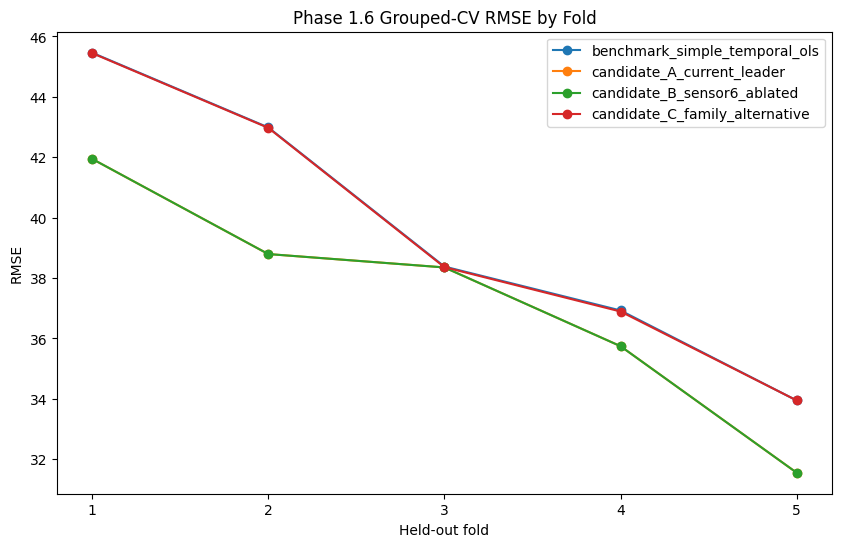

In [37]:
# 4H — Visualize fold-level RMSE
#
# What this does:
# Makes fold-to-fold stability visually obvious.
#
# Why this matters:
# A candidate with a good average score but one severe fold failure can look
# quite different from a candidate with similar overall performance that
# remains consistently strong.

import matplotlib.pyplot as plt


fig, ax = plt.subplots(
    figsize=(10, 6)
)


for candidate_id, candidate_df in (
    fold_metrics_df
    .sort_values("fold_id")
    .groupby("candidate_id")
):

    ax.plot(
        candidate_df["fold_id"],
        candidate_df["heldout_rmse"],
        marker="o",
        label=candidate_id,
    )


ax.set_xlabel(
    "Held-out fold"
)

ax.set_ylabel(
    "RMSE"
)

ax.set_title(
    "Phase 1.6 Grouped-CV RMSE by Fold"
)

ax.set_xticks(
    range(
        1,
        N_CV_FOLDS + 1,
    )
)

ax.legend()

plt.show()

## 4I — Why Look at Per-Engine Error?

Pooled OOF RMSE can still hide important variation.

For example, a model could perform extremely well on most engines but fail
badly on a small subset.

Another candidate could have a slightly worse pooled RMSE but more consistently
reasonable errors across engines.

Per-engine RMSE helps answer:

"Is a candidate's improvement broad across many engines, or concentrated in
only a few engine trajectories?"

This is supporting evidence.

It does not replace the predeclared primary pooled OOF RMSE.

In [38]:
# 4J — Calculate per-engine OOF metrics
#
# What this does:
# Treats each engine's complete eligible OOF trajectory as its own diagnostic
# population.
#
# Why this matters:
# Row-level metrics can hide engines on which the candidate performs poorly.

per_engine_metrics = (
    oof_predictions_df
    .groupby(
        [
            "candidate_id",
            "role",
            GROUP_COLUMN,
        ],
        as_index=False,
    )
    .agg(
        n_prediction_rows=(
            "actual_rul",
            "size",
        ),
        mean_squared_error=(
            "squared_error",
            "mean",
        ),
        engine_mae=(
            "absolute_error",
            "mean",
        ),
        engine_mean_signed_error=(
            "signed_error",
            "mean",
        ),
    )
)


per_engine_metrics[
    "engine_rmse"
] = np.sqrt(
    per_engine_metrics[
        "mean_squared_error"
    ]
)


per_engine_metrics = (
    per_engine_metrics
    .drop(
        columns="mean_squared_error"
    )
)


per_engine_summary = (
    per_engine_metrics
    .groupby(
        [
            "candidate_id",
            "role",
        ],
        as_index=False,
    )
    .agg(
        median_engine_rmse=(
            "engine_rmse",
            "median",
        ),
        mean_engine_rmse=(
            "engine_rmse",
            "mean",
        ),
        worst_engine_rmse=(
            "engine_rmse",
            "max",
        ),
        median_engine_mae=(
            "engine_mae",
            "median",
        ),
    )
)


display(
    per_engine_summary
    .sort_values(
        "median_engine_rmse"
    )
    .round(4)
)

,candidate_id,role,median_engine_rmse,mean_engine_rmse,worst_engine_rmse,median_engine_mae
1,candidate_A_current_leader,primary,25.0823,29.7900,96.0665,21.3045
2,candidate_B_sensor6_ablated,primary,25.0823,29.7905,96.0688,21.3045
0,benchmark_simple_temporal_ols,benchmark,27.8410,33.1836,105.6461,23.5846
3,candidate_C_family_alternative,primary,27.8451,33.1930,105.4540,23.6146


## 4K — Prediction: What Does "Breadth of Gains" Mean?

Suppose Candidate A has the lowest pooled OOF RMSE.

But compared with Candidate B:

- A is much better on 10 engines,
- B is slightly better on 80 engines,
- and they are similar on 10 engines.

Would "Candidate A has the lowest RMSE" tell you the entire story?

What might this suggest about WHERE Candidate A's aggregate advantage comes
from?

Why should breadth-of-gains evidence remain supporting evidence rather than
silently replacing pooled OOF RMSE as the selection rule?

In [39]:
# 4L — Measure breadth of performance across engines
#
# What this does:
# Compares PRIMARY candidates on matched engine-level RMSE.
#
# For each engine, we rank the primary candidates by engine RMSE.
#
# Why this matters:
# This tells us whether a candidate's strength is broad across engines rather
# than being driven by only a few trajectories.

primary_engine_metrics = (
    per_engine_metrics
    .loc[
        per_engine_metrics[
            "role"
        ]
        .eq("primary")
    ]
    .copy()
)


engine_rmse_matrix = (
    primary_engine_metrics
    .pivot(
        index=GROUP_COLUMN,
        columns="candidate_id",
        values="engine_rmse",
    )
)


# All primary candidates must have engine-level metrics for the same engines.
assert not engine_rmse_matrix.isna().any().any()


engine_rank_matrix = (
    engine_rmse_matrix
    .rank(
        axis=1,
        method="min",
        ascending=True,
    )
)


engine_win_counts = (
    engine_rank_matrix
    .eq(1)
    .sum(axis=0)
)


mean_engine_ranks = (
    engine_rank_matrix
    .mean(axis=0)
)


breadth_summary = pd.DataFrame(
    {
        "candidate_id": (
            engine_win_counts.index
        ),
        "engine_rmse_win_count": (
            engine_win_counts.values
        ),
        "mean_engine_rank": [
            mean_engine_ranks.loc[
                candidate_id
            ]
            for candidate_id
            in engine_win_counts.index
        ],
    }
)


display(
    breadth_summary
    .sort_values(
        [
            "engine_rmse_win_count",
            "mean_engine_rank",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .round(4)
)

,candidate_id,engine_rmse_win_count,mean_engine_rank
0,candidate_A_current_leader,47,1.58
1,candidate_B_sensor6_ablated,42,1.71
2,candidate_C_family_alternative,25,2.50


In [40]:
# 4M — Compare primary candidates against the fixed benchmark
#
# What this does:
# Counts how many engines each primary candidate improves upon relative to the
# simple temporal OLS benchmark.
#
# Why this matters:
# The benchmark gives us a stable historical reference for asking whether the
# added modeling complexity generalizes broadly.

benchmark_engine_metrics = (
    per_engine_metrics
    .loc[
        per_engine_metrics[
            "role"
        ]
        .eq("benchmark"),
        [
            GROUP_COLUMN,
            "engine_rmse",
        ],
    ]
    .rename(
        columns={
            "engine_rmse":
                "benchmark_engine_rmse"
        }
    )
)


assert (
    len(benchmark_engine_metrics)
    == development_df[
        GROUP_COLUMN
    ].nunique()
)


primary_vs_benchmark = (
    primary_engine_metrics
    .merge(
        benchmark_engine_metrics,
        on=GROUP_COLUMN,
        how="left",
    )
)


primary_vs_benchmark[
    "engine_rmse_delta_vs_benchmark"
] = (
    primary_vs_benchmark[
        "engine_rmse"
    ]
    - primary_vs_benchmark[
        "benchmark_engine_rmse"
    ]
)


benchmark_breadth_summary = (
    primary_vs_benchmark
    .groupby(
        "candidate_id",
        as_index=False,
    )
    .agg(
        engines_better_than_benchmark=(
            "engine_rmse_delta_vs_benchmark",
            lambda values: (
                values.lt(0).sum()
            ),
        ),
        engines_worse_than_benchmark=(
            "engine_rmse_delta_vs_benchmark",
            lambda values: (
                values.gt(0).sum()
            ),
        ),
        median_engine_rmse_delta_vs_benchmark=(
            "engine_rmse_delta_vs_benchmark",
            "median",
        ),
    )
)


display(
    benchmark_breadth_summary
    .sort_values(
        "engines_better_than_benchmark",
        ascending=False,
    )
    .round(4)
)

,candidate_id,engines_better_than_benchmark,engines_worse_than_benchmark,median_engine_rmse_delta_vs_benchmark
0,candidate_A_current_leader,75,25,-3.7979
1,candidate_B_sensor6_ablated,75,25,-3.7979
2,candidate_C_family_alternative,46,54,0.0079


## 4N — Signed Error as a Directional Diagnostic

RMSE and MAE tell us how large prediction errors are.

Signed error tells us their direction.

signed error = predicted RUL - actual RUL

Therefore:

positive signed error
→ predicted too much RUL
→ overprediction

negative signed error
→ predicted too little RUL
→ underprediction

Example:

actual RUL = 20
predicted RUL = 35

signed error = +15

The model is overestimating how much useful life remains.

A model can have good RMSE while still showing a directional tendency, which is
why signed error remains useful supporting evidence.

In [41]:
# 4O — Summarize directional error behavior
#
# What this does:
# Extracts the signed-error diagnostics already calculated from the full OOF
# prediction population.

signed_error_summary = (
    pooled_oof_summary[
        [
            "candidate_id",
            "role",
            "mean_signed_error",
            "median_signed_error",
            "overprediction_rate",
            "underprediction_rate",
        ]
    ]
    .copy()
)


signed_error_summary[
    "overprediction_percent"
] = (
    100
    * signed_error_summary[
        "overprediction_rate"
    ]
)


signed_error_summary[
    "underprediction_percent"
] = (
    100
    * signed_error_summary[
        "underprediction_rate"
    ]
)


display(
    signed_error_summary[
        [
            "candidate_id",
            "role",
            "mean_signed_error",
            "median_signed_error",
            "overprediction_percent",
            "underprediction_percent",
        ]
    ]
    .round(3)
)

,candidate_id,role,mean_signed_error,median_signed_error,overprediction_percent,underprediction_percent
0,candidate_A_current_leader,primary,-0.028,3.655,57.884,42.116
1,candidate_B_sensor6_ablated,primary,-0.028,3.655,57.889,42.111
2,candidate_C_family_alternative,primary,-0.040,5.940,57.062,42.938
3,benchmark_simple_temporal_ols,benchmark,-0.038,5.971,57.032,42.968


In [42]:
# 4P — Build the complete Phase 1.6 CV evidence table
#
# What this does:
# Places the main overall, stability, engine-level, and breadth diagnostics
# together in one table.
#
# Why this matters:
# Task Group 5 will use this evidence under the PREDECLARED selection hierarchy.

phase_16_cv_analysis = (
    pooled_oof_summary
    .merge(
        fold_stability_summary,
        on=[
            "candidate_id",
            "role",
        ],
        how="left",
    )
    .merge(
        per_engine_summary,
        on=[
            "candidate_id",
            "role",
        ],
        how="left",
    )
    .merge(
        breadth_summary,
        on="candidate_id",
        how="left",
    )
    .merge(
        benchmark_breadth_summary,
        on="candidate_id",
        how="left",
    )
)


# Rank PRIMARY candidates using the predeclared primary metric.
#
# This is descriptive only.
# Formal selection happens in TG5.

phase_16_cv_analysis[
    "primary_oof_rmse_rank"
] = np.nan


primary_mask = (
    phase_16_cv_analysis[
        "role"
    ]
    .eq("primary")
)


phase_16_cv_analysis.loc[
    primary_mask,
    "primary_oof_rmse_rank",
] = (
    phase_16_cv_analysis
    .loc[
        primary_mask,
        "pooled_oof_rmse",
    ]
    .rank(
        method="min",
        ascending=True,
    )
)


phase_16_cv_analysis = (
    phase_16_cv_analysis
    .sort_values(
        [
            "role",
            "pooled_oof_rmse",
        ]
    )
    .reset_index(drop=True)
)


display(
    phase_16_cv_analysis.round(4)
)

,candidate_id,role,oof_rows,pooled_oof_mae,mean_signed_error,median_signed_error,overprediction_rate,underprediction_rate,pooled_oof_rmse,mean_fold_rmse,...,median_engine_rmse,mean_engine_rmse,worst_engine_rmse,median_engine_mae,engine_rmse_win_count,mean_engine_rank,engines_better_than_benchmark,engines_worse_than_benchmark,median_engine_rmse_delta_vs_benchmark,primary_oof_rmse_rank
0,benchmark_simple_temporal_ols,benchmark,19731,30.3104,-0.0378,5.9708,0.5703,0.4297,39.7580,39.5410,...,27.8410,33.1836,105.6461,23.5846,NaN,NaN,NaN,NaN,NaN,NaN
1,candidate_A_current_leader,primary,19731,26.3510,-0.0281,3.6552,0.5788,0.4212,37.4391,37.2788,...,25.0823,29.7900,96.0665,21.3045,47.0,1.58,75.0,25.0,-3.7979,1.0
2,candidate_B_sensor6_ablated,primary,19731,26.3511,-0.0280,3.6552,0.5789,0.4211,37.4395,37.2791,...,25.0823,29.7905,96.0688,21.3045,42.0,1.71,75.0,25.0,-3.7979,2.0
3,candidate_C_family_alternative,primary,19731,30.2895,-0.0398,5.9398,0.5706,0.4294,39.7419,39.5249,...,27.8451,33.1930,105.4540,23.6146,25.0,2.50,46.0,54.0,0.0079,3.0


## 4Q — How to Interpret the Evidence Without Moving the Goalposts

Use the evidence in this order:

### 1. Primary question

Which primary candidate has the lowest pooled OOF RMSE?

This was declared before seeing the CV results.

### 2. How large is the difference?

A numerically lower RMSE is evidence of better performance, but the magnitude
still matters.

Do not invent an arbitrary "practical equivalence threshold" after seeing the
numbers simply because one candidate is preferred aesthetically.

### 3. Is the apparent advantage stable?

Compare:

- fold RMSE variability,
- minimum and maximum fold behavior,
- per-engine errors.

### 4. Is the gain broad?

Ask whether the candidate performs well across many engines or whether its
aggregate advantage comes from a narrow subset.

### 5. Does it show concerning directional behavior?

Inspect signed errors.

### 6. Parsimony

If candidates are genuinely difficult to distinguish from the evidence,
simplicity can serve as a tie-breaker.

But parsimony should not be used to override a meaningful and repeatable
predictive advantage.

### Important boundary

These diagnostics help INTERPRET the predeclared primary metric.

They should not become a post-hoc excuse to select whichever candidate we
already wanted to win.

In [43]:
# 4R — Save the Task Group 4 analysis artifacts

PHASE_16_CV_ANALYSIS_PATH = (
    REPORTS_DIR
    / "phase_16_cv_analysis.csv"
)

PHASE_16_ENGINE_METRICS_PATH = (
    REPORTS_DIR
    / "phase_16_per_engine_metrics.csv"
)


phase_16_cv_analysis.to_csv(
    PHASE_16_CV_ANALYSIS_PATH,
    index=False,
)

per_engine_metrics.to_csv(
    PHASE_16_ENGINE_METRICS_PATH,
    index=False,
)


print("Saved CV analysis:")
print(
    PHASE_16_CV_ANALYSIS_PATH
)

print()

print("Saved per-engine metrics:")
print(
    PHASE_16_ENGINE_METRICS_PATH
)

Saved CV analysis:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_cv_analysis.csv

Saved per-engine metrics:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_per_engine_metrics.csv


In [44]:
# 4S — Generate the Task Group 4 summary

primary_analysis = (
    phase_16_cv_analysis
    .loc[
        phase_16_cv_analysis[
            "role"
        ]
        .eq("primary")
    ]
    .sort_values(
        "pooled_oof_rmse"
    )
)


provisional_oof_leader = (
    primary_analysis
    .iloc[0]
)


tg4_summary = pd.DataFrame(
    {
        "item": [
            "Primary metric",
            "Primary candidates analyzed",
            "OOF observations per candidate",
            "Fold stability analyzed",
            "Per-engine performance analyzed",
            "Breadth of gains analyzed",
            "Signed-error behavior analyzed",
            "Current lowest pooled OOF RMSE candidate",
            "Final model formally selected",
        ],
        "value": [
            "Pooled OOF RMSE",
            len(primary_analysis),
            candidate_oof_counts.iloc[0],
            "Yes",
            "Yes",
            "Yes",
            "Yes",
            provisional_oof_leader[
                "candidate_id"
            ],
            "No — Task Group 5",
        ],
    }
)


display(tg4_summary)


print(
    "\nCurrent primary-candidate ordering "
    "by pooled OOF RMSE:"
)

display(
    primary_analysis[
        [
            "candidate_id",
            "pooled_oof_rmse",
            "pooled_oof_mae",
            "fold_rmse_std",
            "median_engine_rmse",
            "engine_rmse_win_count",
            "mean_signed_error",
        ]
    ]
    .round(4)
)

,item,value
0,Primary metric,Pooled OOF RMSE
1,Primary candidates analyzed,3
2,OOF observations per candidate,19731
3,Fold stability analyzed,Yes
4,Per-engine performance analyzed,Yes
5,Breadth of gains analyzed,Yes
6,Signed-error behavior analyzed,Yes
7,Current lowest pooled OOF RMSE candidate,candidate_A_current_leader
8,Final model formally selected,No — Task Group 5



Current primary-candidate ordering by pooled OOF RMSE:


,candidate_id,pooled_oof_rmse,pooled_oof_mae,fold_rmse_std,median_engine_rmse,engine_rmse_win_count,mean_signed_error
1,candidate_A_current_leader,37.4391,26.3510,3.8830,25.0823,47.0,-0.0281
2,candidate_B_sensor6_ablated,37.4395,26.3511,3.8834,25.0823,42.0,-0.0280
3,candidate_C_family_alternative,39.7419,30.2895,4.6452,27.8451,25.0,-0.0398


## Task Group 4 — Active Recall

### Question 1
What is pooled out-of-fold RMSE, and why is it not generally equal to the arithmetic mean of the five fold RMSE values?

**Best section to review: 4E — Verify Exactly How Pooled OOF RMSE Relates to Fold RMSE**

*Pooled OOF RMSE pools all held-out observations for each candidate before calculating a project's primary and secondary metrics. If we were to take the five OOF RMSE calculations for each fold and then average them, that would not be the same as pooling all the held-out observations and then calculating their RMSE.*

There are two main reasons why pooled OOF RMSE and mean OOF RMSE values are generally not equal. RMSE is nonlinear because the square root happens after averaging squared errors. Folds may contain different numbers of prediction rows, so a simple average gives every fold equal weight regardless of size.

Pooled OOF RMSE treats all OOF prediction rows as one combined held-out population and computes a single RMSE over them.

Pooled OOF RMSE combines the squared errors from every out-of-fold observation across all folds and then calculates the RMSE. It is not generally equal to the arithmetic mean of fold RMSEs because RMSE is nonlinear and folds can contain different numbers of observations.

### Question 2
What different information do pooled OOF RMSE and fold-to-fold RMSE variability provide about a candidate model?

**Best section to review: 4F — Prediction: What Does Fold Variability Tell Us?**

*Pooled OOF RMSE is a tool for figuring out how large a candidate model's errors were overall. Fold-to-fold RMSE variability is a tool for figuring out how sensitive a model's performance was to which engines happened to be in the held-out fold.*

Pooled OOF RMSE -> PERFORMANCE

Fold RMSE variability -> STABILITY

### Question 3
Why do we examine per-engine RMSE and breadth of gains when pooled OOF RMSE is already our primary metric?

**Best sections to review: 4I — Why Look at Per-Engine Error? and 4K — Prediction: What Does "Breadth of Gains" Mean?**

*Relying on pooled OOF RMSE alone can be a bad idea, there is still relevant information that it fails to account for. An example could be a model that performs very well on most engines but fails especially bad on a small subset. To make up for this we can also examine per-engine error, which is a good tool for figuring out if a candidate model's improvement was broad across many engines. As for what breadth of gains means, it's a reference to how broad a model's improvements were found to be when put through a particular process. It tells us whether a candidate's strength if broad across all engines or if any gains we observed were being driven by only a few trajectories.*

Pooled OOF RMSE summarizes all errors but can obscure heterogeneity across engines.

Aggregate improvement -> Did RMSE improve at all? 

Breadth -> How widely across all engines did the improvement occur? 

Pooled OOF RMSE summarizes overall row-level generalization but can hide how performance is distributed across engines. Per-engine RMSE shows whether some engines are unusually difficult, while breadth-of-gains analysis tells us whether an aggredate improvement occurs across many engines or is driven by a small number of trajectories.

### Question 4
What does signed error tell us that RMSE and MAE do not, and why can a mean signed error near zero still coexist with poor predictions?

**Best section to review: 4N — Signed Error as a Directional Diagnostic**

*RMSE and MAE are good tools for examining how large a model's prediction errors were. Signed error tells us their direction, in which we subtract actual RUL from predicted RUL. This creates a situation where positive signed error overpredicted the RUL, and a negative signed error underpredicted the RUL. Mean signed error near zero can still coexist with poor predictions because there can be a mix of large positive errors (overpredictions) and large negative errors (underpredictions) that balanced each other out.*

### Question 5
Why should stability, per-engine behavior, signed errors, and parsimony be treated as supporting evidence rather than used to redefine the model-selection rule after seeing the CV results?

**Best section to review: 4Q — How to Interpret the Evidence Without Moving the Goalposts**

*We locked in our selection criteria before training models in this phase of the project. Our primary selection criteria was to choose the candidate with lowest pooled OOF RMSE. Stability, per-engine behavior, signed errors, and parsimony could all be regarded as secondary selection criteria. We should only account for those unless they reveal something seriously wrong or unexpected about the candidate models. They help us interpret the predeclared primary metric without themselves becoming the primary metric, we need to be careful of using their results to justify selecting a model that we were already biased towards and were hoping would win.*

We predeclared pooled OOF RMSE as the primary selection metric so that we would not change the evaluation rule after seeing the results. Stability, per-engine performance, signed errors, and breadth of gains provide supporting evidence about how robust and interpretable the primary result is, while parsimony can hlep when candidates are genuinely difficult to distinguish. These diagnostics should not become post-hoc reasons to choose whichever model we already preferred.

**Pooled OOF RMSE = one RMSE over all held-out prediction rows.**

**Mean fold RMSE and pooled OOF RMSE differ because RMSE is nonlinear and fold can have different sizes.**

**Pooled DRMSE tells you overall performance; fold variability tells you stability.**

**Per-engine analysis doesn't replace pooled RMSE—it reveals where the aggregate performance came from.**

**Breadth of gains asks whether improvement is widespread or concentrated.**

**Signed error gives direction; RMSE/MAE gives magnitude.**

**Supporting diagnostics interpret the predeclared primary metric—they don't give us permission to move goalposts.**

### Task Group 5: Final Candidate Selection & Model Lock

# Task Group 5 — Final Candidate Selection & Model Lock

## 5A — Core Question

Given the grouped cross-validation evidence from Task Group 4, which frozen
primary candidate should become the final Phase 1 model configuration?

### Predeclared selection hierarchy

1. Primary criterion:
   Lowest pooled out-of-fold RMSE.

2. Supporting evidence:
   - pooled OOF MAE,
   - fold-to-fold RMSE stability,
   - per-engine error behavior,
   - breadth of gains,
   - signed-error behavior.

3. Parsimony:
   If candidates are genuinely difficult to distinguish from the predictive
   evidence, prefer the simpler configuration.

### Important boundary

Task Group 5 does NOT:

- create another candidate,
- change a hyperparameter,
- change the feature representation,
- rerun CV after seeing the result,
- or choose whichever diagnostic makes a preferred model look best.

The grouped-CV evidence is now complete.

Our job is to make the decision we said we would make.

### Mental model

Evidence first.

Decision second.

Lock third.

No more development after the lock.

## 5B — Prediction: What Should Happen If the CV Winner Surprises Us?

Imagine that before running grouped CV you expected Candidate A to win.

Instead:

Candidate B has the lowest pooled OOF RMSE.

Candidate B also has reasonable fold stability and no obviously alarming
diagnostic behavior.

Should we:

A. accept Candidate B as the winner,

or

B. return to Phase 1.5 and search for changes that allow Candidate A to win?

Why?

What would happen to the credibility of grouped cross-validation if we kept
changing the candidates whenever we disliked its answer?

In [45]:
# 5C — Reconstruct the primary-candidate selection table
#
# What this does:
# Isolates the three candidates that were actually eligible to win Phase 1.6
# and orders them using the predeclared PRIMARY metric.
#
# Why this matters:
# The benchmark is useful context, but it was never part of the three-way
# final candidate competition.

selection_table = (
    phase_16_cv_analysis
    .loc[
        phase_16_cv_analysis["role"]
        .eq("primary")
    ]
    .copy()
    .sort_values(
        "pooled_oof_rmse",
        ascending=True,
    )
    .reset_index(drop=True)
)


assert len(selection_table) == 3


# Recreate the primary rank directly from the primary metric.
selection_table[
    "selection_rank"
] = (
    selection_table[
        "pooled_oof_rmse"
    ]
    .rank(
        method="min",
        ascending=True,
    )
    .astype(int)
)


display(
    selection_table[
        [
            "selection_rank",
            "candidate_id",
            "pooled_oof_rmse",
            "pooled_oof_mae",
            "fold_rmse_std",
            "minimum_fold_rmse",
            "maximum_fold_rmse",
            "median_engine_rmse",
            "worst_engine_rmse",
            "engine_rmse_win_count",
            "mean_engine_rank",
            "mean_signed_error",
        ]
    ]
    .round(4)
)

,selection_rank,candidate_id,pooled_oof_rmse,pooled_oof_mae,fold_rmse_std,minimum_fold_rmse,maximum_fold_rmse,median_engine_rmse,worst_engine_rmse,engine_rmse_win_count,mean_engine_rank,mean_signed_error
0,1,candidate_A_current_leader,37.4391,26.3510,3.8830,31.5572,41.9448,25.0823,96.0665,47.0,1.58,-0.0281
1,2,candidate_B_sensor6_ablated,37.4395,26.3511,3.8834,31.5570,41.9459,25.0823,96.0688,42.0,1.71,-0.0280
2,3,candidate_C_family_alternative,39.7419,30.2895,4.6452,33.9498,45.4465,27.8451,105.4540,25.0,2.50,-0.0398


In [46]:
# 5D — Identify the primary-metric winner
#
# What this does:
# Selects the frozen primary candidate with the LOWEST pooled OOF RMSE.
#
# Why this matters:
# This implements the rule declared before grouped-CV results were available.

primary_metric_winner = (
    selection_table
    .iloc[0]
)


selected_candidate_id = (
    primary_metric_winner[
        "candidate_id"
    ]
)


print(
    "Primary-metric winner:"
)

print(
    selected_candidate_id
)

print()

print(
    "Pooled OOF RMSE:",
    round(
        primary_metric_winner[
            "pooled_oof_rmse"
        ],
        4,
    ),
)

print(
    "Pooled OOF MAE:",
    round(
        primary_metric_winner[
            "pooled_oof_mae"
        ],
        4,
    ),
)

print(
    "Fold RMSE standard deviation:",
    round(
        primary_metric_winner[
            "fold_rmse_std"
        ],
        4,
    ),
)

Primary-metric winner:
candidate_A_current_leader

Pooled OOF RMSE: 37.4391
Pooled OOF MAE: 26.351
Fold RMSE standard deviation: 3.883


## 5E — Prediction: What Can Supporting Diagnostics Legitimately Do?

Suppose the pooled OOF RMSE ordering is:

Candidate A: best
Candidate B: second
Candidate C: third

What are supporting diagnostics allowed to help us understand?

Examples:

- whether A's advantage was broad across engines,
- whether one fold was unusually difficult,
- whether A shows a strong directional error tendency,
- whether A is substantially more complex than B.

What should we be careful NOT to do?

For example, would it be legitimate to inspect twenty diagnostics until we
find one metric on which Candidate B beats Candidate A and then declare that
metric more important?

Why would that be another form of moving the goalposts?

In [47]:
# 5F — Compare the winner directly with the other primary candidates
#
# What this does:
# Expresses every candidate's primary performance relative to the CV winner.
#
# Why this matters:
# Absolute scores tell us who ranked first.
# Differences tell us how separated the candidates actually were.

winner_rmse = float(
    primary_metric_winner[
        "pooled_oof_rmse"
    ]
)


winner_comparison = (
    selection_table[
        [
            "candidate_id",
            "pooled_oof_rmse",
            "pooled_oof_mae",
            "fold_rmse_std",
            "median_engine_rmse",
            "worst_engine_rmse",
            "engine_rmse_win_count",
            "mean_engine_rank",
            "mean_signed_error",
        ]
    ]
    .copy()
)


winner_comparison[
    "rmse_above_winner"
] = (
    winner_comparison[
        "pooled_oof_rmse"
    ]
    - winner_rmse
)


winner_comparison[
    "rmse_above_winner_pct"
] = (
    100
    * winner_comparison[
        "rmse_above_winner"
    ]
    / winner_rmse
)


display(
    winner_comparison
    .sort_values(
        "pooled_oof_rmse"
    )
    .round(4)
)

,candidate_id,pooled_oof_rmse,pooled_oof_mae,fold_rmse_std,median_engine_rmse,worst_engine_rmse,engine_rmse_win_count,mean_engine_rank,mean_signed_error,rmse_above_winner,rmse_above_winner_pct
0,candidate_A_current_leader,37.4391,26.3510,3.8830,25.0823,96.0665,47.0,1.58,-0.0281,0.0000,0.0000
1,candidate_B_sensor6_ablated,37.4395,26.3511,3.8834,25.0823,96.0688,42.0,1.71,-0.0280,0.0004,0.0010
2,candidate_C_family_alternative,39.7419,30.2895,4.6452,27.8451,105.4540,25.0,2.50,-0.0398,2.3028,6.1508


In [48]:
# 5G — Inspect the winner's fold-level behavior
#
# What this does:
# Pulls out the five held-out fold results for the candidate that won pooled
# OOF RMSE.
#
# Why this matters:
# Before locking the model, we want to understand whether its aggregate result
# reflects reasonably consistent evidence across the five engine populations.

winner_fold_results = (
    fold_metrics_df
    .loc[
        fold_metrics_df[
            "candidate_id"
        ]
        .eq(
            selected_candidate_id
        )
    ]
    .sort_values(
        "fold_id"
    )
    .reset_index(drop=True)
)


display(
    winner_fold_results[
        [
            "fold_id",
            "training_rows",
            "heldout_rows",
            "train_rmse",
            "heldout_rmse",
            "heldout_mae",
        ]
    ]
    .round(4)
)

,fold_id,training_rows,heldout_rows,train_rmse,heldout_rmse,heldout_mae
0,1,15791,3940,32.7112,41.9448,28.7019
1,2,15778,3953,33.6241,38.7947,26.9703
2,3,15785,3946,34.0992,38.3521,28.2030
3,4,15786,3945,34.1468,35.7453,24.3047
4,5,15784,3947,35.4550,31.5572,23.5775


In [49]:
# 5H — Inspect the winner at the engine level
#
# What this does:
# Shows how the selected candidate performed across individual engines.
#
# Why this matters:
# This lets us understand both typical behavior and the difficult tail before
# finalizing the model-selection narrative.

winner_engine_metrics = (
    per_engine_metrics
    .loc[
        per_engine_metrics[
            "candidate_id"
        ]
        .eq(
            selected_candidate_id
        )
    ]
    .sort_values(
        "engine_rmse",
        ascending=False,
    )
    .reset_index(drop=True)
)


print(
    "Selected candidate:",
    selected_candidate_id,
)

print(
    "Number of evaluated engines:",
    winner_engine_metrics[
        GROUP_COLUMN
    ].nunique(),
)

print()

print(
    "10 highest-error engines:"
)

display(
    winner_engine_metrics[
        [
            GROUP_COLUMN,
            "n_prediction_rows",
            "engine_rmse",
            "engine_mae",
            "engine_mean_signed_error",
        ]
    ]
    .head(10)
    .round(4)
)

Selected candidate: candidate_A_current_leader
Number of evaluated engines: 100

10 highest-error engines:


,unit_no,n_prediction_rows,engine_rmse,engine_mae,engine_mean_signed_error
0,69,353,96.0665,77.6737,-77.5963
1,92,332,82.0795,67.1490,-66.8559
2,96,327,80.3777,62.6665,-62.3853
3,67,304,80.1893,65.1009,-64.9675
4,90,145,65.2823,60.8885,60.8885
5,57,128,63.0886,57.8176,57.8176
6,65,144,60.7561,56.5943,56.5943
7,56,266,59.3691,51.1563,-50.8971
8,84,258,55.8012,48.1155,-47.9641
9,64,274,55.6313,45.2056,-44.9254


## 5I — Parsimony as a Tie-Breaker, Not a Rescue Mechanism

Parsimony means preferring a simpler solution when predictive evidence does not
provide a meaningful reason to accept additional complexity.

Examples of simplicity might include:

- fewer input features,
- no unnecessary sensor dependency,
- simpler preprocessing,
- a simpler model family,
- easier deployment or interpretation.

But simplicity does NOT mean:

"Candidate B lost the primary metric, but I like it more, so I'll call the
difference negligible."

We deliberately did not create a new post-hoc numerical definition of
"practically tied."

Therefore, absent a predeclared tie or an evaluation-integrity problem, the
lowest pooled OOF RMSE candidate remains the winner.

### Mental rule

Parsimony can break a tie.

Parsimony should not manufacture a tie.

In [50]:
# 5J — Recover the exact frozen specification of the winning candidate
#
# What this does:
# Finds the ORIGINAL manifest row associated with the selected candidate.
#
# Why this matters:
# We lock the configuration that actually participated in CV.
# We do not manually reconstruct or reinterpret it after selection.

winner_manifest_rows = (
    candidate_manifest
    .loc[
        candidate_manifest[
            "candidate_id"
        ]
        .eq(
            selected_candidate_id
        )
    ]
)


assert len(
    winner_manifest_rows
) == 1


winner_manifest_row = (
    winner_manifest_rows
    .iloc[0]
    .copy()
)


winner_spec = (
    primary_candidate_specs[
        [
            spec["candidate_id"]
            for spec
            in primary_candidate_specs
        ]
        .index(
            selected_candidate_id
        )
    ]
)


winner_feature_names = (
    feature_names_for_spec(
        winner_spec
    )
)


assert (
    len(winner_feature_names)
    == int(
        winner_manifest_row[
            "n_features"
        ]
    )
)


print(
    "Winning frozen specification:"
)

display(
    winner_manifest_row
    .to_frame(
        name="value"
    )
)


print(
    "\nExact feature count:",
    len(
        winner_feature_names
    ),
)

Winning frozen specification:


,value
candidate_id,candidate_A_current_leader
description,Current Phase 1.5 leading configuration
representation,Matched temporal reference
model_family,RandomForest
capacity_setting,max_depth=5
n_features,36
sensor_6_included,True
target,uncapped RUL
weighting,ordinary row weighting



Exact feature count: 36


## 5K — Prediction: Why Lock the Whole Configuration?

Suppose the winner used:

- a particular temporal representation,
- Sensor 6 included,
- Ridge with a specific alpha,
- ordinary row weighting,
- exact uncapped RUL.

After seeing that it won, could we say:

"Great. Now before final testing, let's slightly change alpha and remove one
more sensor because that might make it even better."

Why would that produce a model that grouped cross-validation never actually
selected?

What exactly does it mean to say that we are locking a COMPLETE model
configuration rather than merely locking a model family?

In [51]:
# 5L — Build the immutable Phase 1.6 model-lock record
#
# What this does:
# Creates a machine-readable record of the exact configuration selected by
# grouped CV, together with the evidence used for the decision.
#
# Why this matters:
# Task Group 6 must refit THIS configuration on all development engines.

import json


def to_python_scalar(value):
    """Convert numpy scalars into ordinary Python values for JSON."""

    if isinstance(
        value,
        np.generic,
    ):
        return value.item()

    return value


locked_model_spec = {
    # ------------------------------------------------------------
    # Identity
    # ------------------------------------------------------------
    "candidate_id": (
        selected_candidate_id
    ),

    "selection_phase": (
        "Phase 1.6 grouped cross-validation"
    ),

    # ------------------------------------------------------------
    # Frozen modeling configuration
    # ------------------------------------------------------------
    "representation": (
        winner_spec[
            "representation"
        ]
    ),

    "model_family": (
        winner_spec[
            "model_family"
        ]
    ),

    "capacity_setting": (
        winner_spec[
            "capacity_setting"
        ]
    ),

    "n_features": (
        len(
            winner_feature_names
        )
    ),

    "feature_names": (
        list(
            winner_feature_names
        )
    ),

    "sensor_6_included": (
        bool(
            winner_spec[
                "sensor_6_included"
            ]
        )
    ),

    "target": (
        winner_spec[
            "target"
        ]
    ),

    "weighting": (
        winner_spec[
            "weighting"
        ]
    ),

    # ------------------------------------------------------------
    # Evaluation contract
    # ------------------------------------------------------------
    "group_column": (
        GROUP_COLUMN
    ),

    "primary_selection_metric": (
        "pooled OOF RMSE"
    ),

    "n_cv_folds": (
        N_CV_FOLDS
    ),

    # ------------------------------------------------------------
    # Selection evidence
    # ------------------------------------------------------------
    "pooled_oof_rmse": to_python_scalar(
        primary_metric_winner[
            "pooled_oof_rmse"
        ]
    ),

    "pooled_oof_mae": to_python_scalar(
        primary_metric_winner[
            "pooled_oof_mae"
        ]
    ),

    "fold_rmse_std": to_python_scalar(
        primary_metric_winner[
            "fold_rmse_std"
        ]
    ),

    "median_engine_rmse": to_python_scalar(
        primary_metric_winner[
            "median_engine_rmse"
        ]
    ),

    "mean_signed_error": to_python_scalar(
        primary_metric_winner[
            "mean_signed_error"
        ]
    ),

    # ------------------------------------------------------------
    # Selection decision
    # ------------------------------------------------------------
    "selection_reason": (
        "Lowest pooled OOF RMSE among the frozen "
        "Phase 1.6 primary candidates."
    ),

    "configuration_locked": True,

    "post_selection_tuning_allowed": False,

    "official_test_used_for_selection": False,
}


print(
    json.dumps(
        locked_model_spec,
        indent=2,
    )
)

{
  "candidate_id": "candidate_A_current_leader",
  "selection_phase": "Phase 1.6 grouped cross-validation",
  "representation": "Matched temporal reference",
  "model_family": "RandomForest",
  "capacity_setting": "max_depth=5",
  "n_features": 36,
  "feature_names": [
    "cycles",
    "op_setting_1",
    "op_setting_2",
    "sensor_measurement_2",
    "sensor_measurement_3",
    "sensor_measurement_4",
    "sensor_measurement_6",
    "sensor_measurement_7",
    "sensor_measurement_8",
    "sensor_measurement_9",
    "sensor_measurement_11",
    "sensor_measurement_12",
    "sensor_measurement_13",
    "sensor_measurement_14",
    "sensor_measurement_15",
    "sensor_measurement_17",
    "sensor_measurement_20",
    "sensor_measurement_21",
    "sensor_measurement_4_lag_1",
    "sensor_measurement_7_lag_1",
    "sensor_measurement_9_lag_1",
    "sensor_measurement_11_lag_1",
    "sensor_measurement_12_lag_1",
    "sensor_measurement_14_lag_1",
    "sensor_measurement_4_diff_1",
    "

In [52]:
# 5M — Save and fingerprint the locked model specification
#
# What this does:
# Writes the final selected configuration to disk and creates an integrity
# fingerprint.
#
# Why this matters:
# Task Groups 6 and 7 should consume this locked specification rather than
# silently reconstructing a different model.

LOCKED_MODEL_SPEC_PATH = (
    REPORTS_DIR
    / "phase_16_locked_model_spec.json"
)


with open(
    LOCKED_MODEL_SPEC_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        locked_model_spec,
        file,
        indent=2,
    )


LOCKED_MODEL_SPEC_SHA256 = (
    hashlib.sha256(
        LOCKED_MODEL_SPEC_PATH
        .read_bytes()
    )
    .hexdigest()
)


print(
    "Locked model specification saved:"
)

print(
    LOCKED_MODEL_SPEC_PATH
)

print()

print(
    "Locked specification SHA-256:"
)

print(
    LOCKED_MODEL_SPEC_SHA256
)

Locked model specification saved:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_locked_model_spec.json

Locked specification SHA-256:
34cdf9c7b844f71dba555b0bdc6206ee849eee7e5634e2ee4a8d6d4ed99f4c8e


In [53]:
# 5N — Verify that the model lock can reconstruct the same candidate
#
# What this does:
# Performs a final consistency audit between:
#
# - the candidate manifest,
# - the selected feature list,
# - the executable estimator factory,
# - and the saved lock file.
#
# Why this matters:
# A lock is only useful if we can faithfully reconstruct what was locked.

with open(
    LOCKED_MODEL_SPEC_PATH,
    "r",
    encoding="utf-8",
) as file:

    reloaded_model_lock = (
        json.load(file)
    )


assert (
    reloaded_model_lock[
        "candidate_id"
    ]
    == selected_candidate_id
)

assert (
    reloaded_model_lock[
        "feature_names"
    ]
    == winner_feature_names
)

assert (
    reloaded_model_lock[
        "n_features"
    ]
    == len(
        winner_feature_names
    )
)

assert (
    reloaded_model_lock[
        "configuration_locked"
    ]
    is True
)

assert (
    reloaded_model_lock[
        "post_selection_tuning_allowed"
    ]
    is False
)

assert (
    reloaded_model_lock[
        "official_test_used_for_selection"
    ]
    is False
)


# Verify that the winning manifest specification still creates
# a fresh unfitted estimator successfully.
final_unfitted_estimator = (
    make_fresh_estimator(
        winner_spec
    )
)


print(
    "Final model-lock audit: PASSED"
)

print()

print(
    "Selected candidate:",
    selected_candidate_id
)

print(
    "Model family:",
    winner_spec[
        "model_family"
    ],
)

print(
    "Capacity setting:",
    winner_spec[
        "capacity_setting"
    ],
)

print(
    "Features:",
    len(
        winner_feature_names
    ),
)

print(
    "Official test labels used:",
    "NO",
)

print(
    "Further tuning allowed:",
    "NO",
)

Final model-lock audit: PASSED

Selected candidate: candidate_A_current_leader
Model family: RandomForest
Capacity setting: max_depth=5
Features: 36
Official test labels used: NO
Further tuning allowed: NO


## 5O — What "Locked" Means From This Point Forward

The winning configuration is now fixed.

Task Group 6 is allowed to change one thing:

THE AMOUNT OF DEVELOPMENT DATA USED TO FIT THE MODEL.

During cross-validation, each fitted model learned from only the training
engines in one fold.

Now that selection is complete, we can refit the SAME configuration using all
100 development engines.

That does NOT count as additional tuning.

We are not changing:

- feature definitions,
- target definition,
- weighting,
- model family,
- hyperparameters,
- preprocessing policy,
- or evaluation criteria.

We are simply giving the already-selected configuration access to all
development data before final test evaluation.

### Mental model

Cross-validation answers:

"Which recipe should we use?"

Task Group 6 answers:

"Now that the recipe is chosen, what happens when we cook it using all
available development data?"

In [54]:
# 5P — Generate the Task Group 5 summary

runner_up = (
    selection_table
    .iloc[1]
)


tg5_summary = pd.DataFrame(
    {
        "item": [
            "Primary selection metric",
            "Primary candidates considered",
            "Selected candidate",
            "Selected pooled OOF RMSE",
            "Runner-up candidate",
            "Runner-up pooled OOF RMSE",
            "RMSE separation from runner-up",
            "Feature count",
            "Model family",
            "Capacity setting",
            "Configuration locked",
            "Further candidate tuning allowed",
            "Official test labels used",
            "Next step",
        ],
        "value": [
            "Pooled OOF RMSE",
            len(selection_table),
            selected_candidate_id,
            primary_metric_winner[
                "pooled_oof_rmse"
            ],
            runner_up[
                "candidate_id"
            ],
            runner_up[
                "pooled_oof_rmse"
            ],
            (
                runner_up[
                    "pooled_oof_rmse"
                ]
                - primary_metric_winner[
                    "pooled_oof_rmse"
                ]
            ),
            len(
                winner_feature_names
            ),
            winner_spec[
                "model_family"
            ],
            winner_spec[
                "capacity_setting"
            ],
            "Yes",
            "No",
            "No",
            (
                "Refit locked winner on all "
                "100 development engines"
            ),
        ],
    }
)


display(tg5_summary)

,item,value
0,Primary selection metric,Pooled OOF RMSE
1,Primary candidates considered,3
2,Selected candidate,candidate_A_current_leader
3,Selected pooled OOF RMSE,37.439092
4,Runner-up candidate,candidate_B_sensor6_ablated
5,Runner-up pooled OOF RMSE,37.439464
6,RMSE separation from runner-up,0.000371
7,Feature count,36
8,Model family,RandomForest
9,Capacity setting,max_depth=5


## Task Group 5 — Active Recall

### Question 1
Why should the candidate with the lowest pooled OOF RMSE normally win Phase 1.6 even if another candidate was the model we expected or hoped would perform best?

**Best section to review: 5B — Prediction: What Should Happen If the CV Winner Surprises Us?**

*Because that is the selection criteria we decidedo on before proceeding into the model training for this section of the project. We created a contract to prevent us from selecting a candidate model with bias as our justification rather than data.*

We should normally select the candidate with the lowest pooled OOF RMSE because the criterion was declared before observing the grouped-CV results. Accepting the predeclared winner reduces the opportunity for our expectations or preferences to influence the selection after seeing the evidence.

### Question 2
What legitimate role do fold stability, per-engine performance, breadth of gains, signed errors, and parsimony play after pooled OOF RMSE has identified the primary-metric winner?

**Best sections to review: 5E — Prediction: What Can Supporting Diagnostics Legitimately Do? and 5I — Parsimony as a Tie-Breaker, Not a Rescue Mechanism**

*Fold stability, per-engine performance, breadth of gains, signed errors, and parsimony could be described as auxiliary metrics. They can support our decision to choose the candiate with the lowest pooled OOF RMSE or alert us to any extreme or unexpected results, as pooled OOF RMSE doesn't provide a comprehensive picture of what model is performing best. These metrics can also serve as a tie breaker in a case where there is more than one model tied for first place as the best candidate on the primary metric.*

Pooled OOF RMSE -> primary decision evidence

Stability/engine behavior/signed errors/breadth -> understand robustness and failure patterns

Parsimony -> tie-break when predictive evidence is genuinely difficult to distinguish

### Question 3
Why do we lock the complete winning configuration—including feature representation, model family, hyperparameters, target, and weighting policy—instead of merely locking the model family?

**Best section to review: 5K — Prediction: Why Lock the Whole Configuration?**

*Because we need to produce a model that grouped cross-validation selected. If we were to leave the model unlocked there is potential for us to make slight modifications to it in the interest of improving performance, which would then create a model that wasn't selected by the cross-validation process that we used in this section. Just locking the model family leaves room for changing other critical pieces of our final candidate model.*

The evidence generated by CV applies to a complete configuration, not merely a family name.

### Question 4
What is the difference between the locked model specification created in Task Group 5 and the final fitted model that will be created in Task Group 6?

**Best section to review: 5O — What "Locked" Means From This Point Forward**

*This has to do with the cross-validation process. At the start of the project we had 100 training engines and 100 test engines. As part of cross-validation, we did a 5-fold cross validation on the 100 training engines, meaning we did a series of 80/20 splits where the 80 became the new trainining set and the 20 became the cross-validation set, which could be described as a simulated test set. For fitting a final model, we do no use an 80/20 split. We use all 100 training engines and instead of testing the resulting model on the cross-validation fold, we test it on the true test set.*

The specification tells us what to fit. The fitted model contains what was learned by fitting it. 

The locked model specification is an unfitted recipe containing the selected feature representation, model family, hyperparameters, target, weighting, and preprocessing policy. In Task Group 6, we instantiate that recipe and fit it on all 100 development engines, producing the final fitted model with learned parameters such as scaler statistics, regression coefficients, or decision trees.

### Question 5
Why is refitting the locked winner on all 100 development engines allowed after model selection, while changing its alpha, feature set, or weighting policy would count as additional tuning?

**Best section to review: 5O — What "Locked" Means From This Point Forward**

*Because our winning configuration is now fixed. The only thing we are allowed to change after locking our model and all its parameters is the amount of training data used to fit the model. This does not count as additional tuning because we are not editing any hyperparameters. The list of things we are not changing includes feature definitions, target definition, weighting, model family, hyperparameters, preprocessing policy, or evaluation criteria.*

Cross-validation answered the question of which configuration we should use.

We're moving from using a subset of development engines and a locked recipe (CV fit) to all 100 development engines with that same locked recipe (final fit).

**Predeclared selection rules only matter if we're willing to accept their winner.**

**Supporting diagnostics interpret the RMSE result; they don't give us permission to choose a favorite model afterward.**

**CV selects an entire configuration, not merely a model family.**

**Locked specification = uniftted recipe.**

**Final fitted model = locked recipe + learned state from all 100 development engines.**

**Task Group 6 fits; Task Group 7 tests.**

**Using more development data after selection is not tuning. Changing the recipe is tuning.**

### Task Group 6: Refit the Locked Winner on All Development Engines

# Task Group 6 — Refit the Locked Winner on All Development Engines

## 6A — Core Question

Now that grouped cross-validation has selected and locked one model
configuration, how do we create the final fitted model without performing any
additional tuning?

### What changes

During grouped CV:

- each fitted model saw only the training engines for one fold.

During the final refit:

- the selected configuration sees all 100 development engines.

### What does NOT change

We keep fixed:

- feature representation,
- feature names,
- model family,
- hyperparameters,
- target definition,
- weighting policy,
- preprocessing policy,
- temporal-feature logic,
- common prediction-row eligibility policy.

### Important boundary

Task Group 6 does NOT evaluate the official test set.

It only creates the final fitted model.

### Mental model

Task Group 5:

"Which recipe wins?"

Task Group 6:

"Fit that exact recipe using all available development data."

Task Group 7:

"Let the untouched official test set judge it."

## 6B — Prediction: Why Can We Use All 100 Development Engines Now?

During each grouped-CV fold, some development engines had to be withheld so
that we could estimate generalization to unseen engines.

Now model selection is finished.

Ask:

1. Why is there no longer a reason to withhold 20-ish development engines from
   the final fit?

2. Why does using all 100 development engines NOT count as hyperparameter
   tuning?

3. Why would changing Ridge alpha, Random Forest depth, or the feature set at
   this point be fundamentally different from simply providing the locked
   configuration more training data?

In [55]:
# 6C — Verify the locked model specification before final fitting
#
# What this does:
# Reloads the model-lock artifact created in Task Group 5 and verifies that
# it has not changed.
#
# Why this matters:
# The final fitted estimator must correspond to the configuration selected
# by grouped cross-validation.

import hashlib
import json
import joblib
import numpy as np
import pandas as pd


current_locked_model_hash = hashlib.sha256(
    LOCKED_MODEL_SPEC_PATH.read_bytes()
).hexdigest()


assert (
    current_locked_model_hash
    == LOCKED_MODEL_SPEC_SHA256
), "Locked model specification changed after Task Group 5."


with open(
    LOCKED_MODEL_SPEC_PATH,
    "r",
    encoding="utf-8",
) as file:

    final_locked_spec = json.load(
        file
    )


assert (
    final_locked_spec[
        "configuration_locked"
    ]
    is True
)

assert (
    final_locked_spec[
        "post_selection_tuning_allowed"
    ]
    is False
)

assert (
    final_locked_spec[
        "official_test_used_for_selection"
    ]
    is False
)


print(
    "Locked model specification: VERIFIED"
)

print(
    "Selected candidate:",
    final_locked_spec[
        "candidate_id"
    ],
)

print(
    "Model family:",
    final_locked_spec[
        "model_family"
    ],
)

print(
    "Feature count:",
    final_locked_spec[
        "n_features"
    ],
)

Locked model specification: VERIFIED
Selected candidate: candidate_A_current_leader
Model family: RandomForest
Feature count: 36


## 6D — Why Preserve the Cycle-10+ Training Population?

During grouped CV, all candidates were trained and evaluated using the same
common prediction-row population.

Because the richest temporal representation required a 10-cycle history,
cycles 1–9 were retained as historical INPUTS but were not used as prediction
rows.

Suppose the winning model happens to use only the 36-feature simple temporal
representation, which technically becomes complete earlier.

Should the final model suddenly be trained on cycles 5–9 as well?

No.

Why?

Because grouped CV selected the candidate under this condition:

same candidate recipe
+
cycle-10+ training population

Changing the final-fit row population would mean the final fitted model no
longer exactly corresponds to the configuration we evaluated.

### Mental rule

The model lock includes not only WHAT information the model uses, but also the
development procedure under which that configuration was selected.

In [56]:
# 6E — Construct temporal features from all 100 development-engine histories
#
# What this does:
# Applies the exact same causal, engine-bounded feature-engineering machinery
# used during grouped CV to the complete development population.
#
# Why this matters:
# We now want every development engine available for model fitting, but feature
# construction itself must remain unchanged.

final_development_temporal_full = (
    build_phase_16_temporal_table(
        development_df
    )
)


assert len(
    final_development_temporal_full
) == len(
    development_df
)

assert (
    final_development_temporal_full[
        GROUP_COLUMN
    ].nunique()
    == 100
)


print(
    "Complete development rows:",
    len(
        final_development_temporal_full
    ),
)

print(
    "Development engines:",
    final_development_temporal_full[
        GROUP_COLUMN
    ].nunique(),
)

Complete development rows: 20631
Development engines: 100


In [57]:
# 6F — Recreate the locked common row-eligibility population
#
# What this does:
# Applies the same Phase 1.6 common temporal eligibility rule used during CV.
#
# Why this matters:
# Final fitting should use the same type of observations on which the
# candidate configurations were compared and selected.

final_eligible_mask = (
    final_development_temporal_full[
        PHASE_16_TEMPORAL_SUPERSET
    ]
    .notna()
    .all(axis=1)
)


final_eligible_df = (
    final_development_temporal_full
    .loc[
        final_eligible_mask
    ]
    .copy()
)


# Every FD001 development engine should contribute eligible observations.
assert (
    final_eligible_df[
        GROUP_COLUMN
    ].nunique()
    == 100
)


# Under the current 10-cycle history policy, the first prediction row for
# every engine should be cycle 10.
first_eligible_cycles = (
    final_eligible_df
    .groupby(
        GROUP_COLUMN
    )["cycles"]
    .min()
)


assert (
    first_eligible_cycles
    .eq(
        EXPANDED_TEMPORAL_WINDOW
    )
    .all()
)


print(
    "Eligible final-fit rows:",
    len(
        final_eligible_df
    ),
)

print(
    "Expected rows from TG2:",
    len(
        expected_oof_row_ids
    ),
)

assert (
    len(
        final_eligible_df
    )
    == len(
        expected_oof_row_ids
    )
)


print(
    "Final-fit row population matches Phase 1.6 OOF population: YES"
)

Eligible final-fit rows: 19731
Expected rows from TG2: 19731
Final-fit row population matches Phase 1.6 OOF population: YES


## 6G — Prediction: Why Do We Still Keep Cycles 1–9?

We are about to fit the final model only on cycle-10+ prediction rows.

So why didn't we simply delete cycles 1–9 before constructing features?

Consider the rolling features at cycle 10.

What historical sensor observations do they need?

### Recall

A row can be:

not eligible as a prediction/training row

while still being:

necessary legal historical information for a later row.

The final refit must preserve the same distinction as Task Group 2.

In [58]:
# 6H — Build the exact final training matrix from the locked feature schema
#
# What this does:
# Uses the feature-name list stored in the model lock instead of inventing or
# reconstructing a new feature set.
#
# Why this matters:
# The final fit must consume exactly the features belonging to the CV winner.

locked_feature_names = list(
    final_locked_spec[
        "feature_names"
    ]
)


assert len(
    locked_feature_names
) == int(
    final_locked_spec[
        "n_features"
    ]
)


# Confirm every locked feature actually exists in the engineered dataframe.
missing_locked_features = [
    feature
    for feature in locked_feature_names
    if feature
    not in final_eligible_df.columns
]


assert not missing_locked_features, (
    "Locked features missing from final development table: "
    f"{missing_locked_features}"
)


X_final_development = (
    final_eligible_df[
        locked_feature_names
    ]
    .copy()
)


y_final_development = (
    final_eligible_df[
        TARGET_COLUMN
    ]
    .copy()
)


groups_final_development = (
    final_eligible_df[
        GROUP_COLUMN
    ]
    .copy()
)


cycles_final_development = (
    final_eligible_df[
        "cycles"
    ]
    .copy()
)


assert X_final_development.index.equals(
    y_final_development.index
)

assert X_final_development.index.equals(
    groups_final_development.index
)

assert np.isfinite(
    X_final_development
    .to_numpy()
).all()

assert np.isfinite(
    y_final_development
    .to_numpy()
).all()


print(
    "Final X shape:",
    X_final_development.shape
)

print(
    "Final y shape:",
    y_final_development.shape
)

print(
    "Final development engines:",
    groups_final_development.nunique()
)

Final X shape: (19731, 36)
Final y shape: (19731,)
Final development engines: 100


## 6I — Prediction: What Happens to StandardScaler Now?

Suppose Ridge won.

During cross-validation, every fold had its own StandardScaler fitted only on
that fold's training observations.

Now there is no held-out DEVELOPMENT fold.

Which observations should be used to fit the final scaler?

Answer:

all eligible development observations.

Why is that now legal?

Because all 100 engines belong to the final training population.

The official test population is still completely excluded.

### Boundary

Final development data
→ may influence scaler and model fitting

Official test data
→ may not influence fitted scaler/model parameters

In [59]:
# 6J — Reconstruct a fresh estimator from the winning frozen specification
#
# What this does:
# Uses the SAME estimator factory that was used during grouped CV.
#
# Why this matters:
# We do not manually construct a "close enough" version of the winner.

winner_spec_for_final_fit = (
    primary_candidate_specs[
        [
            spec["candidate_id"]
            for spec
            in primary_candidate_specs
        ]
        .index(
            final_locked_spec[
                "candidate_id"
            ]
        )
    ]
)


# Verify that the in-memory specification agrees with the persisted model lock.
assert (
    winner_spec_for_final_fit[
        "model_family"
    ]
    == final_locked_spec[
        "model_family"
    ]
)

assert (
    winner_spec_for_final_fit[
        "capacity_setting"
    ]
    == final_locked_spec[
        "capacity_setting"
    ]
)

assert (
    feature_names_for_spec(
        winner_spec_for_final_fit
    )
    == locked_feature_names
)


final_estimator = (
    make_fresh_estimator(
        winner_spec_for_final_fit
    )
)


print(
    "Fresh final estimator created."
)

print(
    final_estimator
)

Fresh final estimator created.
RandomForestRegressor(max_depth=5, n_estimators=300, n_jobs=-1, random_state=42)


In [60]:
# 6K — Fit the locked winner on all development engines
#
# What this does:
# Performs the ONE final development fit.
#
# Why this matters:
# Model selection is over. This fit creates the estimator that will be carried
# into official test evaluation.

final_estimator.fit(
    X_final_development,
    y_final_development,
)


print(
    "Final estimator fitted successfully."
)

print(
    "Training rows:",
    len(
        X_final_development
    ),
)

print(
    "Training engines:",
    groups_final_development.nunique()
)

Final estimator fitted successfully.
Training rows: 19731
Training engines: 100


In [61]:
# 6L — Audit learned preprocessing after the final fit
#
# What this does:
# If the winner uses a StandardScaler Pipeline, verify that the scaler learned
# its statistics from the complete final development training matrix.
#
# Why this matters:
# During CV, training-only meant "current fold training rows."
#
# After model selection, training-only means "all final development rows."
#
# The official test set still contributes nothing.

from sklearn.pipeline import Pipeline


if (
    isinstance(
        final_estimator,
        Pipeline,
    )
    and "scaler"
    in final_estimator.named_steps
):

    final_scaler = (
        final_estimator
        .named_steps[
            "scaler"
        ]
    )


    assert np.allclose(
        final_scaler.mean_,
        X_final_development
        .mean(axis=0)
        .to_numpy(),
    )


    print(
        "Final StandardScaler audit: PASSED"
    )

    print(
        "Scaler learned from all development rows and no test rows."
    )

else:

    print(
        "Selected configuration does not use StandardScaler."
    )

Selected configuration does not use StandardScaler.


## 6M — Why Training Performance Is Not Final Performance

Now that the final model is fitted, we can calculate predictions on the data
it just trained on as a sanity check.

But these are IN-SAMPLE predictions.

They are not:

- OOF performance,
- validation performance,
- or final test performance.

If final training RMSE looks excellent, that does not prove the model will
generalize well.

If it looks unexpectedly terrible, however, that could reveal a pipeline or
reconstruction error.

Therefore training metrics are useful here as an integrity diagnostic, not as
new model-selection evidence.

In [62]:
# 6N — Calculate final-fit training metrics as a sanity check
#
# What this does:
# Verifies that the saved final model can successfully predict its training
# population and produces finite, plausible outputs.
#
# Important:
# These metrics are DESCRIPTIVE ONLY.
# They must not replace the grouped-CV evidence or official test evaluation.

final_training_predictions = (
    final_estimator.predict(
        X_final_development
    )
)


assert np.isfinite(
    final_training_predictions
).all()


final_training_metrics = (
    calculate_regression_metrics(
        y_final_development,
        final_training_predictions,
    )
)


print(
    "FINAL-FIT TRAINING METRICS"
)

print(
    "These are NOT generalization metrics."
)

print()

print(
    "Training RMSE:",
    round(
        final_training_metrics.rmse,
        4,
    ),
)

print(
    "Training MAE:",
    round(
        final_training_metrics.mae,
        4,
    ),
)

FINAL-FIT TRAINING METRICS
These are NOT generalization metrics.

Training RMSE: 34.5147
Training MAE: 24.4357


In [63]:
# 6O — Save the final fitted estimator
#
# What this does:
# Serializes the exact fitted estimator that Task Group 7 will use.
#
# Why this matters:
# TG7 should evaluate this already-fitted artifact rather than refitting the
# model after official test data becomes visible.

FINAL_MODEL_PATH = (
    REPORTS_DIR
    / "phase_16_final_fitted_model.joblib"
)


joblib.dump(
    final_estimator,
    FINAL_MODEL_PATH,
)


FINAL_MODEL_SHA256 = (
    hashlib.sha256(
        FINAL_MODEL_PATH.read_bytes()
    )
    .hexdigest()
)


print(
    "Final fitted model saved:"
)

print(
    FINAL_MODEL_PATH
)

print()

print(
    "Final model SHA-256:"
)

print(
    FINAL_MODEL_SHA256
)

Final fitted model saved:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_final_fitted_model.joblib

Final model SHA-256:
bb5825d198d6eda27d1e720e67837a469ac7d126dfdd2e832bd9b5374514596b


In [64]:
# 6P — Save the final-fit provenance record
#
# What this does:
# Records exactly what data and configuration produced the final estimator.
#
# Why this matters:
# A serialized model is much easier to trust when we also know:
#
# - which candidate produced it,
# - how many engines/rows trained it,
# - which feature schema it expects,
# - and whether official test data was involved.

FINAL_FIT_RECORD_PATH = (
    REPORTS_DIR
    / "phase_16_final_fit_record.json"
)


final_fit_record = {
    "candidate_id": (
        final_locked_spec[
            "candidate_id"
        ]
    ),

    "locked_model_spec_sha256": (
        LOCKED_MODEL_SPEC_SHA256
    ),

    "final_model_sha256": (
        FINAL_MODEL_SHA256
    ),

    "development_engines": int(
        groups_final_development.nunique()
    ),

    "development_training_rows": int(
        len(
            X_final_development
        )
    ),

    "first_eligible_cycle": int(
        EXPANDED_TEMPORAL_WINDOW
    ),

    "n_features": int(
        X_final_development.shape[1]
    ),

    "feature_names": (
        list(
            X_final_development.columns
        )
    ),

    "target": (
        final_locked_spec[
            "target"
        ]
    ),

    "weighting": (
        final_locked_spec[
            "weighting"
        ]
    ),

    "model_family": (
        final_locked_spec[
            "model_family"
        ]
    ),

    "capacity_setting": (
        final_locked_spec[
            "capacity_setting"
        ]
    ),

    "official_test_data_used_in_fit": False,

    "official_test_labels_used_in_fit": False,

    "final_training_rmse": float(
        final_training_metrics.rmse
    ),

    "final_training_mae": float(
        final_training_metrics.mae
    ),
}


with open(
    FINAL_FIT_RECORD_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        final_fit_record,
        file,
        indent=2,
    )


print(
    "Final-fit provenance record saved:"
)

print(
    FINAL_FIT_RECORD_PATH
)

Final-fit provenance record saved:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_16_final_fit_record.json


## 6Q — Prediction: Why Must Task Group 7 Load This Saved Model?

Imagine that in Task Group 7 we load the official test set and then call:

make_fresh_estimator(...)
.fit(...)

again.

Even if we think we are using the same configuration, why is it cleaner to
evaluate the exact serialized estimator created here instead?

Think about experimental boundaries and reproducibility.

### Desired sequence

TG6:
fit final estimator
→ freeze artifact

TG7:
load frozen estimator
→ construct test inputs
→ predict
→ reveal test labels
→ evaluate

The final test set should judge an already-finished model, not participate in
the process that creates it.

In [65]:
# 6R — Reload the saved model and verify reproducibility
#
# What this does:
# Confirms that serialization did not alter model behavior.
#
# Why this matters:
# Task Group 7 will consume the saved model artifact rather than relying only
# on the current notebook's in-memory Python object.

reloaded_final_estimator = (
    joblib.load(
        FINAL_MODEL_PATH
    )
)


reloaded_training_predictions = (
    reloaded_final_estimator.predict(
        X_final_development
    )
)


assert np.allclose(
    final_training_predictions,
    reloaded_training_predictions,
)


reloaded_model_hash = (
    hashlib.sha256(
        FINAL_MODEL_PATH.read_bytes()
    )
    .hexdigest()
)


assert (
    reloaded_model_hash
    == FINAL_MODEL_SHA256
)


print(
    "Final model serialization audit: PASSED"
)

print(
    "Reloaded model reproduces identical predictions."
)

Final model serialization audit: PASSED
Reloaded model reproduces identical predictions.


In [66]:
# 6S — Generate the Task Group 6 summary

tg6_summary = pd.DataFrame(
    {
        "item": [
            "Locked candidate",
            "Development engines used",
            "Development rows before eligibility",
            "Eligible final-fit rows",
            "First eligible prediction cycle",
            "Feature count",
            "Model family",
            "Capacity setting",
            "Fresh estimator created",
            "Final estimator fitted",
            "Official test data used in fitting",
            "Official test labels used",
            "Training metrics used for selection",
            "Final estimator serialized",
            "Next step",
        ],
        "value": [
            final_locked_spec[
                "candidate_id"
            ],
            groups_final_development.nunique(),
            len(
                development_df
            ),
            len(
                X_final_development
            ),
            EXPANDED_TEMPORAL_WINDOW,
            len(
                locked_feature_names
            ),
            final_locked_spec[
                "model_family"
            ],
            final_locked_spec[
                "capacity_setting"
            ],
            "Yes",
            "Yes",
            "No",
            "No",
            "No — sanity check only",
            FINAL_MODEL_PATH.name,
            (
                "Official FD001 test evaluation"
            ),
        ],
    }
)


display(
    tg6_summary
)

,item,value
0,Locked candidate,candidate_A_current_leader
1,Development engines used,100
2,Development rows before eligibility,20631
3,Eligible final-fit rows,19731
4,First eligible prediction cycle,10
5,Feature count,36
6,Model family,RandomForest
7,Capacity setting,max_depth=5
8,Fresh estimator created,Yes
9,Final estimator fitted,Yes


## Task Group 6 — Active Recall

### Question 1
Why is it legitimate to refit the locked winning configuration on all 100 development engines after grouped cross-validation is complete?

**Best section to review: 6B — Prediction: Why Can We Use All 100 Development Engines Now?**

*Because the important part of this section of the project that was locked was the model recipe, not necessarily the data that was used to train it. We can still use a different dataset to train the model without changing any of its predetermined parameters.*

Cross-validation selected the configuration, not one of the temporary fold-specific fitted models. 

What we're specifically allowed to do is use all of the development data that participated in the CV procedure. 

Once grouped CV has selected the model recipe, the temporary held-out development engines no longer need to remain withheld. We can fit the same locked configuration on all 100 development engines because we are increasing the amount of development training data, not changing the configuration that CV selected.

### Question 2
Why do we preserve the same cycle-10+ row-eligibility policy during the final refit even if the winning candidate's own feature representation could technically support earlier prediction rows?

**Best section to review: 6D — Why Preserve the Cycle-10+ Training Population?**

*Because we need to perfectly match the model recipe that we decided in the previous set of tasks for this section of the project. We can change the amount of training data used to train the model, but everything else needs to remain frozen. The cycle-10+ row-eligibility and feature representations are among the parts of the model that need to remain fixed.*

Because the training population definition is also part of the procedure that we devoted so much effort to evaluating.

More engines -> allowed.

Different eligibility policy -> not allowed. 

### Question 3
If the winning configuration uses StandardScaler, why can the final scaler now be fitted on all eligible development observations, and what data must still remain excluded?

**Best section to review: 6I — Prediction: What Happens to StandardScaler Now?**

*Because the StandardScaler must be fitted on all training data without ever being influenced by the test data. In the cross-validation process we used the held-out engines to simulate a test set, but now those engines have been reabsorbed into the training set, meaning we can use them for the StandardScaler. Doing that won't be a form of leakage because the official test set still won't influence the scaler.*

The held-out CV engines are not literally a test set; they're a development-level proxy for unseen-engine evaluation.

### Question 4
Why are the final model's training RMSE and MAE useful as sanity checks but not valid estimates of final generalization performance?

**Best section to review: 6M — Why Training Performance Is Not Final Performance**

*They are useful as sanity checks because we can confirm that they aren't significantly different from the values we saw for RMSE and MAE as part of the cross-validation process. If they were significantly higher then we would have a cause for concern and need to investigate. But they aren't valid estimates of final generalization performance because we have not applied our model to the official test set yet and observed those values for RMSE and MAE.*

We should not expect final training RMSE to closely match OOF RMSE. 

We already have a generalization estimate from grouped CV and it's pooled OOF RMSE. 

Final training RMSE and MAE are useful as initegrity checks because they confirm that the reconstructed final model fits and produces sensible finite predictions. They are not estimates of generalization because they are calculated on the same observations used to fit the model, so they are inherently in-sample and potentially optimistic. Grouped OOF performance estimates generalization during development, while the official test set provides the final untouched evaluation.

### Question 5
What is the purpose of serializing and fingerprinting the final fitted estimator before Task Group 7 rather than simply reconstructing and refitting the model when official test evaluation begins?

**Best section to review: 6Q — Prediction: Why Must Task Group 7 Load This Saved Model?**

*Because we need to ensure we used a locked model that was put through the various quality checks in this section before brining in the test set. Otherwise we might risk refitting a model with an unverified recipe and not get an accurate reading on the official predictive abilities of the model as demonstrated by the test set.*

We aren't jsut freezing the recipe anymore. We're now freezing the actual fitted artifact.

Serialization freezes the exact learned estimator produced before official test evaluation, while fingerprinting lets us verify that the artifact has not changed. Task Group 7 can therefore evaluate the exact model created in Task Group 6 without any additional fitting after entering the test stage. 

**CV witholds development engines for evaluation; final refit can reclaim them once selection is over.**

**More training data is allowed. A different training procedure is not.**

**Final-fit scaler/model parameters may learn from all development data, but never the official test data.**

**Training RMSE is in-sample; OOF RMSE estimates unseen-engine generalization.**

**The official test set is the final untouched judgement, but CV already gave us a development-level generalization estimate.**

**TG5 freezes the recipe. TG6 freezes the fitted artifact. TG7 judges that artifact.**

**Serialization preserves the exact trained model; fingerprinting verifies that is has not changed.**

### Task Group 7: Official Test Evaluation & Phase 1 Conclusion

# Task Group 7 — Official Test Evaluation & Phase 1 Conclusion

## 7A — Core Question

How well does the completely locked and already-fitted model generalize to the
100 official FD001 test engines that played no role in model development?

### What is already finished

Before entering Task Group 7 we have already:

- explored the development data,
- engineered features,
- compared model configurations,
- performed grouped cross-validation,
- selected the winning candidate,
- locked its complete configuration,
- refit that configuration on all 100 development engines,
- serialized the final fitted estimator,
- and fingerprinted that estimator.

### What Task Group 7 is allowed to do

- load the frozen fitted estimator,
- construct legal test features,
- generate test predictions,
- reveal the official test RUL labels,
- calculate final test metrics,
- inspect final diagnostic behavior,
- document the Phase 1 conclusion.

### What Task Group 7 is NOT allowed to do

- refit the model,
- alter features,
- change hyperparameters,
- change weighting,
- select a different candidate,
- or use the test result to improve this Phase 1 model and then retest it.

### Mental model

Train learns.

Validation develops.

Grouped CV selects.

Test judges.

## 7B — Prediction: Why Must Predictions Come Before Labels?

Imagine that the official test RMSE is disappointing.

Would it be legitimate to:

1. inspect which test engines were difficult,
2. change Random Forest depth or features,
3. refit the model,
4. calculate official test RMSE again,
5. keep whichever version performed best?

Why would repeated use of the official test set gradually turn it into another
validation set?

### Important boundary

The value of the official test set comes from the fact that model-development
decisions were made WITHOUT its outcomes.

Once its labels influence another modeling decision, it is no longer providing
the same kind of untouched final evidence.

In [68]:
# 7C — Verify the frozen Phase 1 artifacts before touching test labels
#
# What this does:
# Confirms that both the locked recipe and the final serialized fitted model
# are exactly the artifacts produced in Tasks 5 and 6.
#
# Why this matters:
# The official test set should judge the model we already finished building.

import hashlib
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


current_locked_spec_hash = hashlib.sha256(
    LOCKED_MODEL_SPEC_PATH.read_bytes()
).hexdigest()

current_final_model_hash = hashlib.sha256(
    FINAL_MODEL_PATH.read_bytes()
).hexdigest()


assert (
    current_locked_spec_hash
    == LOCKED_MODEL_SPEC_SHA256
), "Locked model specification changed before final test evaluation."

assert (
    current_final_model_hash
    == FINAL_MODEL_SHA256
), "Final fitted model changed before final test evaluation."


with open(
    LOCKED_MODEL_SPEC_PATH,
    "r",
    encoding="utf-8",
) as file:
    official_test_locked_spec = json.load(file)


assert (
    official_test_locked_spec[
        "configuration_locked"
    ]
    is True
)

assert (
    official_test_locked_spec[
        "post_selection_tuning_allowed"
    ]
    is False
)


print("Locked model specification: VERIFIED")
print("Final fitted estimator: VERIFIED")

print()

print(
    "Candidate:",
    official_test_locked_spec[
        "candidate_id"
    ],
)

print(
    "Model family:",
    official_test_locked_spec[
        "model_family"
    ],
)

print(
    "Feature count:",
    official_test_locked_spec[
        "n_features"
    ],
)

Locked model specification: VERIFIED
Final fitted estimator: VERIFIED

Candidate: candidate_A_current_leader
Model family: RandomForest
Feature count: 36


In [69]:
# 7D — Load the official FD001 test INPUTS while keeping labels sealed
#
# What this does:
# Reloads the canonical FD001 data.
#
# The loader returns:
#
# 1. development/train dataframe
# 2. official test input dataframe
# 3. official test endpoint-RUL labels
#
# We deliberately set the labels aside and do not inspect or use them yet.

unused_development_df, official_test_raw_df, official_test_rul_sealed = (
    load_cmapss_subset(
        DATASET_NAME
    )
)

del unused_development_df


official_test_raw_df = (
    official_test_raw_df
    .sort_values(
        [
            GROUP_COLUMN,
            "cycles",
        ]
    )
    .reset_index(drop=True)
)


assert (
    official_test_raw_df[
        GROUP_COLUMN
    ].nunique()
    == 100
)

assert not official_test_raw_df.duplicated(
    subset=[
        GROUP_COLUMN,
        "cycles",
    ]
).any()


# The official test inputs should not already contain our training target.
assert (
    TARGET_COLUMN
    not in official_test_raw_df.columns
)


print(
    "Official test input rows:",
    len(
        official_test_raw_df
    ),
)

print(
    "Official test engines:",
    official_test_raw_df[
        GROUP_COLUMN
    ].nunique(),
)

print()

print(
    "Official test labels loaded but still SEALED."
)

Official test input rows: 13096
Official test engines: 100

Official test labels loaded but still SEALED.


## 7E — Why We Need a Target-Blind Temporal Builder

Our Task Group 2 helper was written around development data and included an
assertion that RUL existed in the dataframe.

The official test inputs correctly do NOT contain RUL.

Rather than adding labels merely to satisfy the helper, we create the same
deterministic temporal features without requiring a target column.

This gives us a cleaner boundary:

test sensor history
→ features
→ predictions

BEFORE

official RUL labels
→ evaluation

The temporal rules remain unchanged:

- current/past observations only,
- same engine only,
- no future cycles,
- no learned transformations from test data.

In [71]:
# 7F — Build temporal features from test inputs WITHOUT test labels
#
# What this does:
# Reproduces the Phase 1.6 temporal feature construction while remaining
# completely target-blind.

OFFICIAL_TEST_ROW_ID_COLUMN = (
    "_official_test_row_id"
)


def build_phase_16_test_temporal_table(
    history_df,
):
    """
    Construct the same causal Phase 1.6 temporal feature superset for
    target-free official test inputs.
    """

    working_df = history_df.copy()

    working_df[
        OFFICIAL_TEST_ROW_ID_COLUMN
    ] = working_df.index


    working_df = (
        working_df
        .sort_values(
            [
                GROUP_COLUMN,
                "cycles",
            ]
        )
        .copy()
    )


    # Same simple temporal construction used during development.
    simple_df = (
        add_simple_temporal_features(
            working_df
        )
    )


    # Same expanded causal temporal construction used during development.
    expanded_df = (
        add_expanded_temporal_features(
            X=simple_df,
            groups=simple_df[
                GROUP_COLUMN
            ],
            sensor_columns=(
                EXPANDED_TEMPORAL_SOURCE_FEATURES
            ),
            lag=(
                EXPANDED_TEMPORAL_LAG
            ),
            window=(
                EXPANDED_TEMPORAL_WINDOW
            ),
        )
    )


    assert len(
        expanded_df
    ) == len(
        history_df
    )

    assert (
        OFFICIAL_TEST_ROW_ID_COLUMN
        in expanded_df.columns
    )

    assert (
        GROUP_COLUMN
        in expanded_df.columns
    )


    return expanded_df


official_test_temporal_full = (
    build_phase_16_test_temporal_table(
        official_test_raw_df
    )
)


print(
    "Target-blind test temporal construction: COMPLETE"
)

Target-blind test temporal construction: COMPLETE


In [72]:
# 7G — Apply the SAME cycle-10+ eligibility policy used during Phase 1.6
#
# What this does:
# Requires the complete 60-feature Phase 1.6 temporal superset to be available
# before a test row becomes eligible.
#
# Why this matters:
# We do not change the row-eligibility policy just because model development
# has ended.

official_test_eligible_mask = (
    official_test_temporal_full[
        PHASE_16_TEMPORAL_SUPERSET
    ]
    .notna()
    .all(axis=1)
)


official_test_eligible_df = (
    official_test_temporal_full
    .loc[
        official_test_eligible_mask
    ]
    .copy()
)


first_test_eligible_cycle = (
    official_test_eligible_df
    .groupby(
        GROUP_COLUMN
    )["cycles"]
    .min()
)


assert (
    first_test_eligible_cycle
    .eq(
        EXPANDED_TEMPORAL_WINDOW
    )
    .all()
)


assert (
    official_test_eligible_df[
        GROUP_COLUMN
    ].nunique()
    == 100
)


expected_test_eligible_rows = (
    len(
        official_test_raw_df
    )
    - (
        official_test_raw_df[
            GROUP_COLUMN
        ].nunique()
        * (
            EXPANDED_TEMPORAL_WINDOW
            - 1
        )
    )
)


assert (
    len(
        official_test_eligible_df
    )
    == expected_test_eligible_rows
)


print(
    "Eligible official test rows:",
    len(
        official_test_eligible_df
    ),
)

print(
    "First eligible cycle:",
    EXPANDED_TEMPORAL_WINDOW,
)

Eligible official test rows: 12196
First eligible cycle: 10


In [73]:
# 7H — Construct the exact locked test feature matrix
#
# What this does:
# Uses ONLY the feature names stored in the locked model specification.
#
# Why this matters:
# The official test matrix must have exactly the schema expected by the
# already-fitted model.

official_test_feature_names = list(
    official_test_locked_spec[
        "feature_names"
    ]
)


assert (
    official_test_feature_names
    == locked_feature_names
)


missing_test_features = [
    feature
    for feature
    in official_test_feature_names
    if feature
    not in official_test_eligible_df.columns
]


assert not missing_test_features, (
    "Missing locked test features: "
    f"{missing_test_features}"
)


X_official_test = (
    official_test_eligible_df[
        official_test_feature_names
    ]
    .copy()
)


assert (
    X_official_test.shape[1]
    == official_test_locked_spec[
        "n_features"
    ]
)

assert np.isfinite(
    X_official_test
    .to_numpy()
).all()


print(
    "Official test X shape:",
    X_official_test.shape,
)

print(
    "Test labels used so far:",
    "NO",
)

Official test X shape: (12196, 36)
Test labels used so far: NO


## 7I — Prediction: What Happens If the Final Model Is a Pipeline?

Suppose Ridge had won and the serialized model contained:

StandardScaler
→ Ridge

When we call:

final_model.predict(X_official_test)

should StandardScaler calculate NEW means and standard deviations from the
official test set?

No.

The already-fitted scaler must use the development-data statistics learned in
Task Group 6.

Likewise, our Random Forest winner must use the already-grown trees from
Task Group 6.

### Mental rule

Test data may flow THROUGH learned transformations.

Test data may not CHANGE learned transformations.

In [74]:
# 7J — Load the frozen estimator and generate predictions BEFORE using labels
#
# What this does:
# Loads the exact serialized estimator produced in Task Group 6 and produces
# all eligible official-test predictions.
#
# No fitting occurs here.

official_test_estimator = (
    joblib.load(
        FINAL_MODEL_PATH
    )
)


# Recheck the serialized artifact after loading.
assert (
    hashlib.sha256(
        FINAL_MODEL_PATH.read_bytes()
    ).hexdigest()
    == FINAL_MODEL_SHA256
)


official_test_predictions_raw = (
    official_test_estimator.predict(
        X_official_test
    )
)


assert np.isfinite(
    official_test_predictions_raw
).all()


official_test_prediction_frame = pd.DataFrame(
    {
        OFFICIAL_TEST_ROW_ID_COLUMN: (
            official_test_eligible_df[
                OFFICIAL_TEST_ROW_ID_COLUMN
            ]
            .to_numpy()
        ),

        GROUP_COLUMN: (
            official_test_eligible_df[
                GROUP_COLUMN
            ]
            .to_numpy()
        ),

        "cycles": (
            official_test_eligible_df[
                "cycles"
            ]
            .to_numpy()
        ),

        "predicted_rul": (
            official_test_predictions_raw
        ),
    }
)


print(
    "Official test predictions generated:",
    len(
        official_test_prediction_frame
    ),
)

print()

print(
    "Model refitted during Task Group 7:",
    "NO",
)

print(
    "Official labels consulted before prediction:",
    "NO",
)

Official test predictions generated: 12196

Model refitted during Task Group 7: NO
Official labels consulted before prediction: NO


## 7K — Understanding the FD001 Test Labels

The official FD001 RUL file contains one value for each of the 100 test
engines.

That value represents:

RUL at the FINAL OBSERVED CYCLE of that truncated test engine.

Example:

Engine 42 ends at observed cycle 120.

Official endpoint RUL = 25.

That means:

cycle 120 → RUL 25
cycle 119 → RUL 26
cycle 118 → RUL 27
...
cycle 100 → RUL 45

Therefore, for an earlier observed cycle t:

RUL(t)
=
official endpoint RUL
+
(final observed cycle - t)

This allows us to calculate two useful test evaluations:

1. OFFICIAL ENDPOINT EVALUATION
   - exactly 100 predictions,
   - one at the final observed cycle of each engine,
   - directly corresponds to the supplied official RUL labels.

2. RECONSTRUCTED ROW-LEVEL EVALUATION
   - all eligible observed test cycles,
   - derived exactly from the endpoint RUL and cycle position,
   - useful because our development objective was row-level RUL prediction.

We will report both.

Neither will be used for further Phase 1 model selection.

In [75]:
# 7L — UNSEAL the official test labels and reconstruct exact test RUL
#
# This is the first cell in which the official test outcomes influence any
# computation.
#
# Importantly, predictions already exist.

assert (
    official_test_rul_sealed.shape[1]
    == 1
)


official_test_engine_ids = (
    np.sort(
        official_test_raw_df[
            GROUP_COLUMN
        ].unique()
    )
)


official_endpoint_rul_values = (
    pd.to_numeric(
        official_test_rul_sealed
        .iloc[:, 0]
    )
    .to_numpy()
)


assert (
    len(
        official_endpoint_rul_values
    )
    == len(
        official_test_engine_ids
    )
    == 100
)


# The NASA RUL file is ordered by test-engine number.
official_endpoint_truth = pd.DataFrame(
    {
        GROUP_COLUMN: (
            official_test_engine_ids
        ),
        "official_endpoint_rul": (
            official_endpoint_rul_values
        ),
    }
)


# Determine the final observed cycle for every truncated test engine.
test_final_cycles = (
    official_test_raw_df
    .groupby(
        GROUP_COLUMN,
        as_index=False,
    )["cycles"]
    .max()
    .rename(
        columns={
            "cycles":
                "final_observed_cycle"
        }
    )
)


# Build one truth record for every raw test row.
official_test_truth_rows = (
    official_test_raw_df[
        [
            GROUP_COLUMN,
            "cycles",
        ]
    ]
    .copy()
)


official_test_truth_rows[
    OFFICIAL_TEST_ROW_ID_COLUMN
] = (
    official_test_truth_rows.index
)


official_test_truth_rows = (
    official_test_truth_rows
    .merge(
        test_final_cycles,
        on=GROUP_COLUMN,
        how="left",
        validate="many_to_one",
    )
    .merge(
        official_endpoint_truth,
        on=GROUP_COLUMN,
        how="left",
        validate="many_to_one",
    )
)


# Exact RUL at every observed test cycle.
official_test_truth_rows[
    "actual_rul"
] = (
    official_test_truth_rows[
        "official_endpoint_rul"
    ]
    + (
        official_test_truth_rows[
            "final_observed_cycle"
        ]
        - official_test_truth_rows[
            "cycles"
        ]
    )
)


assert (
    official_test_truth_rows[
        "actual_rul"
    ]
    .ge(0)
    .all()
)


print(
    "Official FD001 test labels: UNSEALED"
)

print(
    "Model changes allowed from this point:",
    "NO",
)

Official FD001 test labels: UNSEALED
Model changes allowed from this point: NO


In [76]:
# 7M — Attach truth to the already-generated test predictions
#
# What this does:
# Joins test labels to predictions only AFTER those predictions were frozen.

official_test_predictions = (
    official_test_prediction_frame
    .merge(
        official_test_truth_rows[
            [
                OFFICIAL_TEST_ROW_ID_COLUMN,
                GROUP_COLUMN,
                "cycles",
                "actual_rul",
                "official_endpoint_rul",
                "final_observed_cycle",
            ]
        ],
        on=[
            OFFICIAL_TEST_ROW_ID_COLUMN,
            GROUP_COLUMN,
            "cycles",
        ],
        how="left",
        validate="one_to_one",
    )
)


assert not official_test_predictions[
    "actual_rul"
].isna().any()


official_test_predictions[
    "signed_error"
] = (
    official_test_predictions[
        "predicted_rul"
    ]
    - official_test_predictions[
        "actual_rul"
    ]
)


official_test_predictions[
    "absolute_error"
] = (
    official_test_predictions[
        "signed_error"
    ]
    .abs()
)


official_test_predictions[
    "squared_error"
] = (
    official_test_predictions[
        "signed_error"
    ]
    .pow(2)
)


print(
    "Prediction/truth alignment audit: PASSED"
)

Prediction/truth alignment audit: PASSED


In [77]:
# 7N — Calculate reconstructed row-level official test performance
#
# What this does:
# Scores all cycle-10+ official test observations.
#
# Why this matters:
# Our development objective was row-level exact RUL prediction, so this provides
# a useful test-set diagnostic using the same general type of prediction task.

official_test_row_metrics = (
    calculate_regression_metrics(
        official_test_predictions[
            "actual_rul"
        ],
        official_test_predictions[
            "predicted_rul"
        ],
    )
)


official_test_mean_signed_error = (
    official_test_predictions[
        "signed_error"
    ]
    .mean()
)


official_test_overprediction_rate = (
    official_test_predictions[
        "signed_error"
    ]
    .gt(0)
    .mean()
)


print(
    "RECONSTRUCTED ROW-LEVEL OFFICIAL TEST PERFORMANCE"
)

print()

print(
    "Eligible observations:",
    len(
        official_test_predictions
    ),
)

print(
    "RMSE:",
    round(
        official_test_row_metrics.rmse,
        4,
    ),
)

print(
    "MAE:",
    round(
        official_test_row_metrics.mae,
        4,
    ),
)

print(
    "Mean signed error:",
    round(
        official_test_mean_signed_error,
        4,
    ),
)

print(
    "Overprediction rate:",
    f"{100 * official_test_overprediction_rate:.1f}%",
)

RECONSTRUCTED ROW-LEVEL OFFICIAL TEST PERFORMANCE

Eligible observations: 12196
RMSE: 41.3419
MAE: 31.0221
Mean signed error: -3.0606
Overprediction rate: 57.6%


In [78]:
# 7O — Calculate the direct 100-engine official endpoint score
#
# What this does:
# Keeps only the final observed cycle for each test engine.
#
# These 100 rows correspond directly to the 100 labels supplied by the
# official FD001 RUL file.

endpoint_indices = (
    official_test_predictions
    .groupby(
        GROUP_COLUMN
    )["cycles"]
    .idxmax()
)


official_endpoint_predictions = (
    official_test_predictions
    .loc[
        endpoint_indices
    ]
    .sort_values(
        GROUP_COLUMN
    )
    .reset_index(drop=True)
)


assert len(
    official_endpoint_predictions
) == 100


# At the final observed cycle, reconstructed RUL must exactly equal the
# directly supplied official endpoint label.
assert np.allclose(
    official_endpoint_predictions[
        "actual_rul"
    ],
    official_endpoint_predictions[
        "official_endpoint_rul"
    ],
)


official_endpoint_metrics = (
    calculate_regression_metrics(
        official_endpoint_predictions[
            "actual_rul"
        ],
        official_endpoint_predictions[
            "predicted_rul"
        ],
    )
)


endpoint_mean_signed_error = (
    official_endpoint_predictions[
        "signed_error"
    ]
    .mean()
)


print(
    "OFFICIAL FD001 ENDPOINT EVALUATION"
)

print()

print(
    "Test engines:",
    len(
        official_endpoint_predictions
    ),
)

print(
    "Endpoint RMSE:",
    round(
        official_endpoint_metrics.rmse,
        4,
    ),
)

print(
    "Endpoint MAE:",
    round(
        official_endpoint_metrics.mae,
        4,
    ),
)

print(
    "Endpoint mean signed error:",
    round(
        endpoint_mean_signed_error,
        4,
    ),
)

OFFICIAL FD001 ENDPOINT EVALUATION

Test engines: 100
Endpoint RMSE: 25.914
Endpoint MAE: 19.0619
Endpoint mean signed error: 11.9959


## 7P — Prediction: Can We Call Test RMSE Minus OOF RMSE a Pure
## "Generalization Gap"?

Be careful.

The development engines are complete run-to-failure trajectories.

The official test engines are truncated trajectories.

That means the prediction populations do not necessarily contain the same RUL
distribution or lifecycle composition.

For example, development OOF includes observations all the way down to RUL = 0.

A truncated test engine may end while substantial useful life remains.

Therefore:

CV RMSE and test RMSE can certainly be compared descriptively.

But a difference between them is not automatically caused only by model
overfitting.

Population differences also matter.

### Better wording

"The model achieved X grouped-CV RMSE on the development population and Y RMSE
on the official test population."

Avoid automatically interpreting:

Y - X

as a clean estimate of overfitting.

In [79]:
# 7Q — Compare development evidence with final test evidence carefully
#
# What this does:
# Places the major evaluation numbers together WITHOUT treating them as
# perfectly interchangeable populations.

locked_candidate_id = (
    official_test_locked_spec[
        "candidate_id"
    ]
)


locked_cv_evidence = (
    phase_16_cv_analysis
    .loc[
        phase_16_cv_analysis[
            "candidate_id"
        ]
        .eq(
            locked_candidate_id
        )
    ]
    .iloc[0]
)


phase_1_evaluation_summary = pd.DataFrame(
    [
        {
            "evaluation": (
                "Development grouped CV"
            ),
            "population": (
                "Cycle-10+ rows from complete "
                "run-to-failure development engines"
            ),
            "n_predictions": (
                candidate_oof_counts.loc[
                    locked_candidate_id
                ]
            ),
            "rmse": (
                locked_cv_evidence[
                    "pooled_oof_rmse"
                ]
            ),
            "mae": (
                locked_cv_evidence[
                    "pooled_oof_mae"
                ]
            ),
        },
        {
            "evaluation": (
                "Official test — reconstructed row level"
            ),
            "population": (
                "Cycle-10+ rows from truncated "
                "official test engines"
            ),
            "n_predictions": (
                len(
                    official_test_predictions
                )
            ),
            "rmse": (
                official_test_row_metrics.rmse
            ),
            "mae": (
                official_test_row_metrics.mae
            ),
        },
        {
            "evaluation": (
                "Official test — endpoint"
            ),
            "population": (
                "Final observed cycle of each "
                "official test engine"
            ),
            "n_predictions": (
                len(
                    official_endpoint_predictions
                )
            ),
            "rmse": (
                official_endpoint_metrics.rmse
            ),
            "mae": (
                official_endpoint_metrics.mae
            ),
        },
    ]
)


display(
    phase_1_evaluation_summary
    .round(4)
)

,evaluation,population,n_predictions,rmse,mae
0,Development grouped CV,Cycle-10+ rows from complete run-to-failure de...,19731,37.4391,26.3510
1,Official test — reconstructed row level,Cycle-10+ rows from truncated official test en...,12196,41.3419,31.0221
2,Official test — endpoint,Final observed cycle of each official test engine,100,25.9140,19.0619


In [80]:
# 7R — Calculate per-engine official test diagnostics
#
# What this does:
# Summarizes row-level error separately for each test engine.
#
# Why this matters:
# The final aggregate metric can still hide difficult individual trajectories.

official_test_per_engine = (
    official_test_predictions
    .groupby(
        GROUP_COLUMN,
        as_index=False,
    )
    .agg(
        n_prediction_rows=(
            "actual_rul",
            "size",
        ),
        mean_squared_error=(
            "squared_error",
            "mean",
        ),
        engine_mae=(
            "absolute_error",
            "mean",
        ),
        engine_mean_signed_error=(
            "signed_error",
            "mean",
        ),
    )
)


official_test_per_engine[
    "engine_rmse"
] = np.sqrt(
    official_test_per_engine[
        "mean_squared_error"
    ]
)


official_test_per_engine = (
    official_test_per_engine
    .drop(
        columns="mean_squared_error"
    )
)


print(
    "Median test-engine RMSE:",
    round(
        official_test_per_engine[
            "engine_rmse"
        ].median(),
        4,
    ),
)

print(
    "Worst test-engine RMSE:",
    round(
        official_test_per_engine[
            "engine_rmse"
        ].max(),
        4,
    ),
)


print()

print(
    "10 highest-error official test engines:"
)


display(
    official_test_per_engine
    .sort_values(
        "engine_rmse",
        ascending=False,
    )
    .head(10)
    .round(4)
)

Median test-engine RMSE: 26.6904
Worst test-engine RMSE: 108.1707

10 highest-error official test engines:


,unit_no,n_prediction_rows,engine_mae,engine_mean_signed_error,engine_rmse
92,93,235,102.5818,-102.5818,108.1707
88,89,168,95.2081,-95.2081,98.2351
11,12,208,84.0158,-84.0158,89.9833
36,37,112,74.3148,74.3148,75.4743
40,41,114,71.7705,71.7705,73.2521
0,1,22,72.3609,72.3609,72.5138
48,49,294,55.6164,-48.4336,70.6837
66,67,62,66.5008,66.5008,66.9926
44,45,143,64.2387,-64.2387,65.2982
90,91,225,59.5198,-59.5198,63.9303


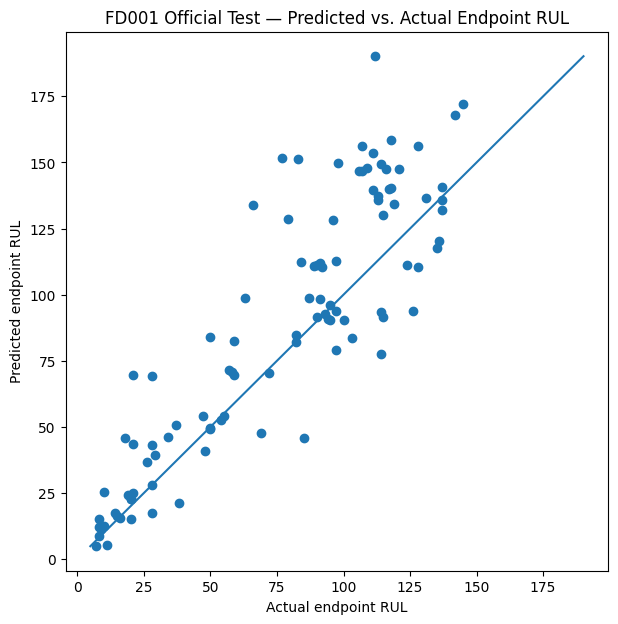

In [81]:
# 7S — Visualize official endpoint predictions versus actual RUL
#
# What this does:
# Shows the final-cycle predictions for all 100 official test engines.
#
# Why this matters:
# The diagonal represents perfect prediction.

fig, ax = plt.subplots(
    figsize=(7, 7)
)


ax.scatter(
    official_endpoint_predictions[
        "actual_rul"
    ],
    official_endpoint_predictions[
        "predicted_rul"
    ],
)


axis_min = min(
    official_endpoint_predictions[
        "actual_rul"
    ].min(),
    official_endpoint_predictions[
        "predicted_rul"
    ].min(),
)


axis_max = max(
    official_endpoint_predictions[
        "actual_rul"
    ].max(),
    official_endpoint_predictions[
        "predicted_rul"
    ].max(),
)


ax.plot(
    [
        axis_min,
        axis_max,
    ],
    [
        axis_min,
        axis_max,
    ],
)


ax.set_xlabel(
    "Actual endpoint RUL"
)

ax.set_ylabel(
    "Predicted endpoint RUL"
)

ax.set_title(
    "FD001 Official Test — Predicted vs. Actual Endpoint RUL"
)


plt.show()

## 7T — The Most Important Post-Test Rule

After the official labels have been revealed, the test set is no longer
pristine for this project's future model-development decisions.

Suppose the final result suggests:

"The model performs poorly at high RUL."

That is a valuable finding.

It can motivate FUTURE WORK.

For example, Phase 2 might investigate:

- a different target formulation,
- additional temporal representations,
- alternative model families,
- different loss functions.

But we should not:

observe the official test weakness
→ modify Phase 1 model
→ score the same official test again
→ report the improved score as another untouched test result

That would turn test feedback into development feedback.

### Mental rule

Test results may inspire the NEXT experiment.

They should not rewrite the experiment they just judged.

In [82]:
# 7U — Save final official-test evidence
#
# What this does:
# Preserves both observation-level predictions and engine-level diagnostics.

OFFICIAL_TEST_PREDICTIONS_PATH = (
    REPORTS_DIR
    / "phase_1_official_test_predictions.csv"
)

OFFICIAL_ENDPOINT_PREDICTIONS_PATH = (
    REPORTS_DIR
    / "phase_1_official_endpoint_predictions.csv"
)

OFFICIAL_TEST_ENGINE_METRICS_PATH = (
    REPORTS_DIR
    / "phase_1_official_test_per_engine_metrics.csv"
)


official_test_predictions.to_csv(
    OFFICIAL_TEST_PREDICTIONS_PATH,
    index=False,
)

official_endpoint_predictions.to_csv(
    OFFICIAL_ENDPOINT_PREDICTIONS_PATH,
    index=False,
)

official_test_per_engine.to_csv(
    OFFICIAL_TEST_ENGINE_METRICS_PATH,
    index=False,
)


print(
    "Saved row-level test predictions:"
)

print(
    OFFICIAL_TEST_PREDICTIONS_PATH
)

print()

print(
    "Saved endpoint predictions:"
)

print(
    OFFICIAL_ENDPOINT_PREDICTIONS_PATH
)

print()

print(
    "Saved per-engine test diagnostics:"
)

print(
    OFFICIAL_TEST_ENGINE_METRICS_PATH
)

Saved row-level test predictions:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_1_official_test_predictions.csv

Saved endpoint predictions:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_1_official_endpoint_predictions.csv

Saved per-engine test diagnostics:
/Users/stuart/repos/ml-predictive-maintenance-mlops/reports/phase_1_official_test_per_engine_metrics.csv


In [83]:
# 7V — Create the machine-readable Phase 1 conclusion
#
# What this does:
# Records the complete chain from selected model through final untouched test
# evaluation.
#
# Why this matters:
# This becomes the final reproducible summary of Phase 1.

PHASE_1_CONCLUSION_PATH = (
    REPORTS_DIR
    / "phase_1_conclusion.json"
)


phase_1_conclusion = {
    "dataset": (
        DATASET_NAME
    ),

    "phase_1_complete": True,

    "selected_candidate": (
        locked_candidate_id
    ),

    "model_family": (
        official_test_locked_spec[
            "model_family"
        ]
    ),

    "capacity_setting": (
        official_test_locked_spec[
            "capacity_setting"
        ]
    ),

    "n_features": int(
        official_test_locked_spec[
            "n_features"
        ]
    ),

    "target": (
        official_test_locked_spec[
            "target"
        ]
    ),

    "weighting": (
        official_test_locked_spec[
            "weighting"
        ]
    ),

    "selection_metric": (
        "pooled grouped-CV OOF RMSE"
    ),

    "development_pooled_oof_rmse": float(
        locked_cv_evidence[
            "pooled_oof_rmse"
        ]
    ),

    "development_pooled_oof_mae": float(
        locked_cv_evidence[
            "pooled_oof_mae"
        ]
    ),

    "official_test_row_level_rmse": float(
        official_test_row_metrics.rmse
    ),

    "official_test_row_level_mae": float(
        official_test_row_metrics.mae
    ),

    "official_test_endpoint_rmse": float(
        official_endpoint_metrics.rmse
    ),

    "official_test_endpoint_mae": float(
        official_endpoint_metrics.mae
    ),

    "official_test_engines": int(
        official_endpoint_predictions[
            GROUP_COLUMN
        ].nunique()
    ),

    "final_model_sha256": (
        FINAL_MODEL_SHA256
    ),

    "test_labels_revealed_only_after_prediction": True,

    "post_test_phase_1_tuning_allowed": False,
}


with open(
    PHASE_1_CONCLUSION_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        phase_1_conclusion,
        file,
        indent=2,
    )


print(
    json.dumps(
        phase_1_conclusion,
        indent=2,
    )
)

{
  "dataset": "FD001",
  "phase_1_complete": true,
  "selected_candidate": "candidate_A_current_leader",
  "model_family": "RandomForest",
  "capacity_setting": "max_depth=5",
  "n_features": 36,
  "target": "uncapped RUL",
  "weighting": "ordinary row weighting",
  "selection_metric": "pooled grouped-CV OOF RMSE",
  "development_pooled_oof_rmse": 37.439092445905096,
  "development_pooled_oof_mae": 26.350960414880262,
  "official_test_row_level_rmse": 41.34185107076347,
  "official_test_row_level_mae": 31.02209101393462,
  "official_test_endpoint_rmse": 25.91401662256538,
  "official_test_endpoint_mae": 19.061923112994936,
  "official_test_engines": 100,
  "final_model_sha256": "bb5825d198d6eda27d1e720e67837a469ac7d126dfdd2e832bd9b5374514596b",
  "test_labels_revealed_only_after_prediction": true,
  "post_test_phase_1_tuning_allowed": false
}


## 7W — Phase 1 Conclusion: What We Can Now Claim

At the end of Phase 1, we have completed an end-to-end predictive-maintenance
model-development process with a clear separation between development and
final evaluation.

We can now make evidence-based claims such as:

- the model predicts exact uncapped RUL from causal, engine-bounded temporal
  information,
- candidate selection used grouped cross-validation by engine,
- every development engine served as unseen validation data exactly once,
- the final candidate was chosen using the predeclared pooled OOF RMSE rule,
- the winning configuration was locked before official test labels were used,
- the winner was refit on all development engines without changing its recipe,
- the final serialized estimator was frozen before official test evaluation,
- and final performance was measured on the untouched FD001 test population.

### What we should NOT claim

The project does not establish that:

- the chosen model family is universally optimal,
- the chosen temporal features capture the physical causal mechanism of engine
  degradation,
- FD001 performance automatically generalizes to other C-MAPSS subsets or
  real industrial equipment,
- or the official test result proves a production system is ready.

Those would require additional evidence.

### Phase 1 accomplishment

The important achievement is not merely obtaining one RMSE value.

It is establishing a defensible experimental chain:

problem framing
→ leakage-safe data preparation
→ controlled experiments
→ grouped model selection
→ locked final configuration
→ full-development refit
→ untouched official test evaluation

In [84]:
# 7X — Generate the final Phase 1 notebook summary

phase_1_final_summary = pd.DataFrame(
    {
        "item": [
            "Dataset",
            "Development engines",
            "Official test engines",
            "Locked candidate",
            "Model family",
            "Feature count",
            "Development selection metric",
            "Development pooled OOF RMSE",
            "Official row-level test RMSE",
            "Official endpoint test RMSE",
            "Official endpoint test MAE",
            "Final model frozen before test labels",
            "Post-test Phase 1 tuning allowed",
            "Phase 1 status",
        ],
        "value": [
            DATASET_NAME,
            100,
            100,
            locked_candidate_id,
            official_test_locked_spec[
                "model_family"
            ],
            official_test_locked_spec[
                "n_features"
            ],
            "Pooled grouped-CV OOF RMSE",
            locked_cv_evidence[
                "pooled_oof_rmse"
            ],
            official_test_row_metrics.rmse,
            official_endpoint_metrics.rmse,
            official_endpoint_metrics.mae,
            "Yes",
            "No",
            "COMPLETE",
        ],
    }
)


display(
    phase_1_final_summary
)

,item,value
0,Dataset,FD001
1,Development engines,100
2,Official test engines,100
3,Locked candidate,candidate_A_current_leader
4,Model family,RandomForest
5,Feature count,36
6,Development selection metric,Pooled grouped-CV OOF RMSE
7,Development pooled OOF RMSE,37.439092
8,Official row-level test RMSE,41.341851
9,Official endpoint test RMSE,25.914017


## Task Group 7 — Active Recall

### Question 1
Why should the final serialized estimator generate official test predictions before the official RUL labels are used, and what would happen if we repeatedly modified the model in response to test performance?

**Best sections to review: 7B — Prediction: Why Must Predictions Come Before Labels? and 7T — The Most Important Post-Test Rule**

*Because we want to have an honest set of predictions to compare to the held-out official test labels. If we modified the model in response to the test performance we would wind up fitting to the test data and compromise the model's ability to generalize to truly new and unseen test data.*

The precise term for this is adaptive test-set use or test-set overfitting.

The frozen estimator should generate predictions before official labels influence any decision so that the test score reflects performance of a model developed independently of the test outcomes. Repeatedly modifying the model in response to test results would adapt the development process to that test set, gradually turning it into another validation set and making its reported performance optimistic. 

### Question 2
What does the official FD001 RUL file directly tell us, how can we reconstruct RUL for earlier observed test cycles, and what is the difference between the endpoint evaluation and the reconstructed row-level evaluation?

**Best section to review: 7K — Understanding the FD001 Test Labels**

*It tells us the true RUL label at the time of truncation in the test set. We can reconstruct RUL for earlier observed test cycles by adding the true RUL to the number of cycles passed at the time of truncation. Then we make a simple calculation to figure out the true RUL at any given cycle earlier in the engines trajectory. Endpoint evaluation is the prediction our model makes at the time of truncation in the test set, reconstructed row-level evaluation is made possible by calculation that was just descrived.*

The official FD001 RUL file gives the true remaining useful life at each test engine's final observed cycle.

The FD001 RUL file directly provides one true RUL value per test engine at its final observed, truncated cycle. For an earlier cycle t, we reconstruct its RUL plus the difference between the engine's final observed cycle at t. Endpoint evaluation therefore scores on prediction per engine directly against the supplied NASA labels, while reconstructred row-level evaluation scores all eligible observed cycles using derived RUL targets. 

### Question 3
Why should we be cautious about interpreting the difference between development pooled OOF RMSE and official test RMSE as a pure measure of overfitting?

**Best section to review: 7P — Prediction: Can We Call Test RMSE Minus OOF RMSE a Pure "Generalization Gap"?**

*While a difference between development pooled OOF RMSE and official test RMSE can be an indicator of overfitting, it can also come as a result of the population differences between the training and test sets without having cause to suspect overfitting. The development engines are complete run-to-failure trajectories while the official test engines are truncated trajectories. That has the consequence of dealing with prediction populations that do not necessarily contain the same RUL distribution or lifecycle composition.*

The model performed differently on two related but non-identical evaluation populations.

### Question 4
After the official test labels have been revealed, why can poor test behavior legitimately motivate future experiments but not justify modifying the Phase 1 model and reporting another score on the same test set as an untouched evaluation?

**Best section to review: 7T — The Most Important Post-Test Rule**

*We need to realize that after official test labels have been revealed, the test set is no longer a secret answer sheet that needs to be saved for evaluation and the project's future model-development decisions. The results of applying the model to the official test set can still be thought of as valuable findings. Test result are allowed to inspire the next experiment, but they should not rewrite the experiment that they just judged.*

Once we've seen the answers, the test set is no longer pristine.

The first official test set could be thought of as an exam, while after seeing the answers it gets demoted to being study material (but it can still be useful).

### Question 5
What evidence chain allows us to say that Phase 1 produced a defensibly evaluated final model, and what kinds of claims would still go beyond the evidence we collected?

**Best section to review: 7W — Phase 1 Conclusion: What We Can Now Claim**

*The accomplishment of this section is that we now have a defensible experimental chain. The sequence is problem framing, leakage-safe data preparation, controlled experiments, grouped model selection, locked final configuration, full-development refit, and finally an untouched official test evaluation. But there are still things that the project does not establish at this point, and among them are that the chosen model family is universally optimal or that the official test result indicates our model is production ready.*

Good FD001 results do not imply that we have proof that it will generalize to FD002/FD003/FD004. 

Predictive temporal relationship does not imply proof of physical causal mechanisms of engine degradation.

Phase 1 produced a reproducible, leakage-aware model-development and evaluation pipline with grouped model selection and an untouched final test evaluation. The evidence supports this configuration's predictive performance on FD001 under our stated target and feature design, but it does not establish universal model optimality, physical causality, transfer to other operating regimes, or production readiness.

**Using test labels to make new modeling decisions converts test feedback into development feedback.**

**Official FD001 labels give endpoint RUL; earlier RUL is reconstructed as endpoint RUL + remaining observed-cycle distance.**

**Endpoint evaluation = 100 direct NASA labels. Row-level evaluation = reconstructed labels across eligible cycles.**

**OOF RMSE vs test RMSE is not a pure overfitting measurement because the populations differ.**

**After test labels are revealed, the test set can inspire future work but is no longer pristine for another "untouched" evaluation.**

**The strongest achievement of Phase 1 is the evaluation chain, not merely the final RMSE.**

**Strong FD001 predictive evidence does not imply universal optimality, causality, cross-dataset generalization, or production readiness.**